# BaTiO₃ nanoneedles: batch Bayesian optimization on a shared cross-validation basis

**Goal.** Maximize the **aspect ratio (AR)** of BaTiO₃ nanoneedles while keeping phase purity acceptable, and propose the next batch of *q* experiments.

**What is new in this version: one common basis for everything.**
1. **Step 3b** builds the cross-validation (CV) folds **once**: recipe-grouped outer folds, inner folds for tuning, and repeated random partitions for replay.
2. **Step 4** compares *surrogate models* (mean baseline, Random Forest, Matérn-3/2 GP, Matérn-5/2 GP, RBF GP) with **nested CV + `GridSearchCV`** on those folds (the V7 approach). The GP structure (shared vs per-variable lengthscales, oven-run offset on/off, prior strength, HTO as an input or not) is **tuned by CV instead of decided by me**.
3. The CV-selected GP is then used, unchanged, by the **three-prong batch optimizer** (Steps 6-10): minimum distance, sequential fantasies, joint q-EI/q-NEI, and maximum entropy.
4. **Step 10b** compares acquisition functions and batch strategies on the **same folds** by *replay*: the surrogate sees only the training recipes, each strategy picks from the held-out recipes, and we score the picks with their known outcomes.

**Why replay and not plain CV for acquisition functions?** CV measures *prediction error*. An acquisition function is a *decision rule* (which experiment next?), so it has no prediction error. What can be measured offline is "if we had used this rule at that point in time, would it have picked a good recipe?". That is replay. Its power is low with 9 recipes, and the notebook says so wherever it matters.

Every section matches a numbered step of the protocol. Each cell is preceded by an explanation of *what* and *why*. Run top to bottom.

**Dataset handling in this adapted version.** The original and sonicated CSVs are loaded separately and compared by `run_id`. The main BO analysis defaults to the sonicated measurements; change `ACTIVE_DATASET` in Step 1 to `"original"` to rerun the full workflow on the original measurements. Both datasets have the same 18 runs and the same synthesis conditions. The first 12 outcomes are unchanged; runs 13–18 (batches B_05 and B_06) differ substantially.

**Target transform.** The objective is `avg_Ln_AR`, i.e. the mean of the log aspect ratios measured within each SEM sample. This is not `ln(avg_AR)` and is not `Ln_median_AR`. Optimizing this target corresponds to maximizing geometric-mean AR. Model fitting and acquisition operate in log space; visualizations convert predictions back to log-AR units where the target is modeled where appropriate.


## Notebook map: the order in which the sections run

The cells are arranged so that **every variable is created before it is used**. Each section depends only on the sections above it, so the notebook can be run top to bottom with *Run all*.

| Part | Sections | What it produces |
|---|---|---|
| Setup | Step 1, 1b | Settings, libraries, random generator |
| Data | Steps 2, 2b, 3, 3b | Loaded and validated data (`df`), the shared cross-validation folds |
| Surrogate model | Step 4 (4b to 4e) | GP code, nested-CV leaderboard, the chosen GP `bo_est`, calibration, null model, XGBoost benchmark |
| Batch optimizer | Steps 5 to 10b | `BOContext` and `ctx`, candidate pool, acquisition functions, the batch strategies, their comparison and replay |
| Batch design extension | Step 10c | Joint q-NEI batch, seed-stability check, oven-run markers |
| Replicate analysis | Steps 10d, 10e, 10f | Variance and delta GPs, their diagnostics, the heteroscedastic mean GP |
| Lab loop | Steps 11 to 19 | Chosen batch and CSV export, data update, progress evaluation, validation, conclusions |
| Appendix | Notes whose code cells are not in this notebook | |

## Step 1: Define the optimization problem and all settings

Decision variables remain `time_h`, `baoh_mass_g`, and `water_initial_ml`, exactly as in V2. The objective is `avg_Ln_AR`, the mean of the individual log aspect ratios measured within a sample. Purity remains an experimental acceptance criterion only; it is not an optimization target.

**HTO mass.** It is essentially constant. CV decides whether to include it as a model input; it is never optimized.

**Two matched datasets.** `original` is the original SEM analysis and `sonicated` is the updated/sonicated SEM analysis. They are analyzed separately. The default active dataset is `sonicated`, but it can be switched below. Keep both CSVs in the same folder as this notebook.


In [ ]:
# ===================== USER CONFIGURATION (edit here) =====================
OLD_CSV_PATH = "DescriptiveStats_BaTiO3_Rd1.csv"       # original SEM measurements
SONICATED_CSV_PATH = "DescriptiveStats_BaTiO3_Rd1_Final.csv" # sonicated SEM measurements
ACTIVE_DATASET = "sonicated"  # choose "original" or "sonicated" for the main BO workflow
CSV_PATH = SONICATED_CSV_PATH if ACTIVE_DATASET == "sonicated" else OLD_CSV_PATH

# --- Variables we can change in the lab (decision variables) ---
OPT_VARS = ["time_h", "baoh_mass_g", "water_initial_ml"]
BOUNDS = {                                      # valid ranges [min, max]; default = range covered by Round 1
    "time_h":           (6.0, 24.0),
    "baoh_mass_g":      (0.77, 1.8),
    "water_initial_ml": (30.0, 55.0),
}
STEP = {"time_h": 1.0, "baoh_mass_g": 0.01, "water_initial_ml": 1.0}   # lab resolution -> candidate grid
HTO_RANGE = (0.10, 0.15)       # fixed scaling range for HTO mass (a design constant, not learned from data)
HTO_FIXED = None               # HTO value given to candidates if the chosen model uses HTO (None = median of data)

# --- Objective and feasibility ---
TARGET, PURITY_COL, PURITY_MIN = "avg_Ln_AR", "purity_pct", 95.0

# --- Batch settings ---
Q, SEED = 3, 42                # batch size; random seed

# --- Acquisition used by Prong 1 and 2 ("EI", "UCB", "PI" or "NEI") ---
ACQ_NAME, KAPPA, XI, NEI_SAMPLES = "NEI", 2.0, 0.01, 500

# --- Prong 1 / pool / joint-prong settings ---
D_MIN, EXCLUDE_RADIUS = 0.25, 0.05
N_MC_OPT, N_MC_EVAL = 1024, 20000
SHORT_TOP, SHORT_RAND = 500, 1000
ALLOWED_TIMES = None           # e.g. [8.0] if one oven run can only use one time (then run once per time)
def lab_constraints(pool_df):
    """Return True for recipes that can really be run. Default: all of them."""
    return np.ones(len(pool_df), dtype=bool)

# --- Oven-run (batch) ids: column "batch_id" if present, otherwise parsed from `notes` ("B3S2" -> "B3") ---

# ================= SHARED CROSS-VALIDATION SETTINGS (Step 3b / 4 / 10b) =================
OUTER_SPLITS  = 3              # outer folds: evaluate the whole tune-then-fit procedure (as in V7)
INNER_SPLITS  = 3              # inner folds: tune hyperparameters/structure inside each outer-training set
SELECTION_SCORING = "neg_root_mean_squared_error"   # the ONE metric used by every GridSearchCV
CV_RESTARTS, FINAL_RESTARTS = 6, 40    # optimizer restarts for a GP fit inside CV / for the final fit
N_JOBS = -1                    # parallel workers for GridSearchCV (set 1 if the environment complains)
REPLAY_REPEATS, REPLAY_Q = 30, 2       # replay: random partitions (repeat 0 = canonical folds) and batch size

# Random Forest candidates (as in V7)
RF_GRID = {"rf__max_depth": [1, 2, 3, None], "rf__min_samples_leaf": [1, 2, 3], "rf__max_features": [0.5, 1.0]}

# GP structure choices tuned by inner CV (every combination is a candidate)
GP_GRID = {
    "ard":          [False, True],          # False: one shared lengthscale; True: one per input
    "batch_effect": [False, True],          # include a shared offset for runs of the same oven run?
    "prior":        ["free", "weak"],       # bounds on the GP hyperparameters (see PRIORS)
    "use_hto":      [False, True],          # HTO mass as an extra (never optimized) input?
}
GP_FAMILIES = {"Matern-3/2 GP": "matern32", "Matern-5/2 GP": "matern52", "RBF GP": "rbf"}
BO_SURROGATE = "auto"          # "auto" = best GP family by outer-CV RMSE (ties resolved by FAMILY_PREFERENCE), or a key of GP_FAMILIES

# --- Tie rule: CV differences smaller than TIE_TOLERANCE (relative RMSE) are NOT trusted ---
# With 9 recipes the CV score of two structures that differ by 1-2% is noise (replicate scatter alone is ~2.75 AR units).
# Among all candidates within the tolerance of the best, we choose the one that satisfies most of these PRE-DECLARED preferences
# (ties of ties: lowest CV RMSE). Reasons are in Step 3: oven-run offsets are large and real; HTO is constant except one suspicious run.
TIE_TOLERANCE = 0.02
STRUCTURE_PREFERENCE = {"batch_effect": False, "use_hto": False, "ard": False, "prior": "weak"}
FAMILY_PREFERENCE = ["Matern-5/2 GP", "Matern-3/2 GP", "RBF GP"]

# Hyperparameter bounds, in standardized-target units (total variance of the target = 1).
#  free: almost unconstrained, lets the likelihood/CV decide.
#  weak: assumes a smooth effect of at least 10% of the variance and lengthscales of at least half of each variable's range.
PRIORS = {
    "free": dict(amp2=(1e-2, 10.0), ls=(0.10, 10.0), sb2=(1e-3, 3.0), sn2=(1e-3, 3.0)),
    "weak": dict(amp2=(0.10, 3.0),  ls=(0.20, 5.0),  sb2=(1e-3, 3.0), sn2=(1e-2, 2.0)),
}

## Step 1b: Imports and the random-number generator

**What.** Loads every library used by the notebook (NumPy, pandas, SciPy, scikit-learn, matplotlib), sets the table display options, and creates the shared random generator `RNG` from `SEED`.

**Why here.** It sits right after the settings because `RNG` needs `SEED`, which is defined in Step 1. Everything below relies on these imports, so nothing else needs to import them again (a few later cells add their own extra imports for convenience).

In [ ]:
import warnings, copy, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from scipy.linalg import cho_factor, cho_solve, cholesky, solve_triangular
from scipy.optimize import minimize
from scipy.spatial.distance import cdist
from scipy.stats import norm, spearmanr
from IPython.display import display
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
RNG = np.random.default_rng(SEED)

## Step 2: Prepare and organize the experimental dataset

The source files already contain `recipe_id` and `batch_id`; these identifiers are retained. Recipe IDs define the CV groups so replicates of the same synthesis recipe are never split between training and test. Batch IDs define the shared oven-run offset in the GP.


## Step 2b: Original-versus-sonicated SEM comparison

This section is intentionally separate from BO. It compares the same run IDs under two SEM measurement datasets. The synthesis conditions are checked for exact agreement before any paired comparison is made. The main workflow then analyzes only the dataset selected in `ACTIVE_DATASET`.

The target is `avg_Ln_AR` in both datasets. Do not substitute `ln(avg_AR)` or `Ln_median_AR`: those are different summaries and would not be a like-for-like comparison.


In [ ]:
# ---------------------------------------------------------------------------
# Load, clean and harmonize the two SEM datasets.
# The original CSV has a few trailing spreadsheet rows containing summary
# labels/values outside the actual run table. We keep only rows with run_id.
# ---------------------------------------------------------------------------
def load_sem_dataset(path, dataset_label):
    """Read one SEM summary CSV and standardize column names for the BO code."""
    data = pd.read_csv(path)
    data.columns = data.columns.astype(str).str.strip()

    # Harmonize the column names used by the two SEM exports.
    rename = {
        "Run_id": "run_id", "Recipe_id": "recipe_id", "Batch_id": "batch_id",
        "temperature": "temperature_c", "Purity": "purity_pct", "Notes": "notes",
        "aspect_ratio (mean)": "aspect_ratio",
        "water_initial_mL": "water_initial_ml",
    }
    data = data.rename(columns=rename)

    # The old CSV contains spreadsheet artefacts after the 18 valid runs.
    # Rows without a run identifier are not experimental synthesis runs.
    if "run_id" not in data.columns:
        raise ValueError(f"{path} has no run_id/Run_id column.")
    data = data.loc[data["run_id"].notna()].copy()
    data["run_id"] = pd.to_numeric(data["run_id"], errors="raise").astype(int)

    required = [
        "run_id", "recipe_id", "batch_id", "temperature_c", "time_h",
        "hto_mass_g", "baoh_mass_g", "water_initial_ml", "water_rinse_ml",
        "avg_Ln_AR", "Purity" if "Purity" in data.columns else "purity_pct"
    ]
    missing = [c for c in required if c not in data.columns]
    if missing:
        raise ValueError(f"{path} is missing required columns: {missing}")

    # Preserve the recipe and batch identifiers supplied with the data.
    # Do NOT reconstruct recipe IDs from floating-point masses when reliable
    # identifiers are already present in the source file.
    data["recipe_id"] = pd.to_numeric(data["recipe_id"], errors="raise").astype(int)
    data["batch_id"] = data["batch_id"].astype(str).str.strip()
    data["round"] = 1
    if "notes" not in data.columns:
        data["notes"] = ""
    data["dataset"] = dataset_label

    # Convert the purity column to the common lowercase name.
    if "Purity" in data.columns:
        data = data.rename(columns={"Purity": "purity_pct"})
    data = data.reset_index(drop=True)

    # IDs should uniquely identify rows in each dataset.
    if data["run_id"].duplicated().any():
        raise ValueError(f"{path} contains duplicate run_id values.")
    return data

df_original = load_sem_dataset(OLD_CSV_PATH, "original")
df_sonicated = load_sem_dataset(SONICATED_CSV_PATH, "sonicated")

# ---------------------------------------------------------------------------
# Matched, run-by-run comparison. Both exports should describe the same
# synthesis runs, so pair by run_id and verify the experimental conditions.
# ---------------------------------------------------------------------------
comparison = df_original.merge(
    df_sonicated, on="run_id", how="outer", suffixes=("_original", "_sonicated"),
    indicator=True
)
if not comparison["_merge"].eq("both").all():
    raise ValueError("Original and sonicated files do not contain the same run_id set.")

condition_cols = [
    "recipe_id", "batch_id", "temperature_c", "time_h", "hto_mass_g",
    "baoh_mass_g", "water_initial_ml", "water_rinse_ml"
]
for col in condition_cols:
    a = comparison[f"{col}_original"]
    b = comparison[f"{col}_sonicated"]
    if col in ("recipe_id", "batch_id"):
        same = a.astype(str).eq(b.astype(str)).all()
    else:
        same = np.allclose(a.astype(float), b.astype(float), rtol=0, atol=1e-8)
    if not same:
        raise ValueError(f"Experimental conditions/IDs do not match between datasets: {col}")

comparison["delta_log_AR_sonicated_minus_original"] = (
    comparison["avg_Ln_AR_sonicated"] - comparison["avg_Ln_AR_original"]
)
comparison["AR_geomean_ratio_sonicated_over_original"] = np.exp(
    comparison["delta_log_AR_sonicated_minus_original"]
)

print(f"Original dataset:  {len(df_original)} runs, {df_original.recipe_id.nunique()} recipes, {df_original.batch_id.nunique()} batches")
print(f"Sonicated dataset: {len(df_sonicated)} runs, {df_sonicated.recipe_id.nunique()} recipes, {df_sonicated.batch_id.nunique()} batches")
print(f"Active dataset for BO: {ACTIVE_DATASET}")

print("\\nPaired comparison of SEM outcomes (log-AR scale):")
display(comparison[[
    "run_id", "recipe_id_original", "batch_id_original",
    "avg_Ln_AR_original", "avg_Ln_AR_sonicated",
    "delta_log_AR_sonicated_minus_original",
    "AR_geomean_ratio_sonicated_over_original"
]].round(4))

changed = comparison["delta_log_AR_sonicated_minus_original"].abs() > 1e-8
print(f"Runs with changed target: {changed.sum()} / {len(comparison)}")
print("Mean paired log-AR change:", comparison.loc[changed, "delta_log_AR_sonicated_minus_original"].mean())
print("Median paired geometric-mean AR ratio:", comparison.loc[changed, "AR_geomean_ratio_sonicated_over_original"].median())
print("Note: the paired changes are concentrated in the remeasured runs; with only six changed runs, treat these as descriptive rather than a definitive inferential test.")

# Select the dataset for the remaining V2 workflow.
df = df_sonicated.copy() if ACTIVE_DATASET == "sonicated" else df_original.copy()
df = df.reset_index(drop=True)


Original dataset:  18 runs, 9 recipes, 6 batches
Sonicated dataset: 18 runs, 9 recipes, 6 batches
Active dataset for BO: sonicated
\nPaired comparison of SEM outcomes (log-AR scale):


,run_id,recipe_id_original,batch_id_original,avg_Ln_AR_original,avg_Ln_AR_sonicated,delta_log_AR_sonicated_minus_original,AR_geomean_ratio_sonicated_over_original
0,1,1,B_01,2.6137,2.6137,0.0000,1.0000
1,2,2,B_01,2.6099,2.6099,0.0000,1.0000
2,3,3,B_01,2.5147,2.5147,0.0000,1.0000
3,4,1,B_02,2.6971,2.6971,0.0000,1.0000
4,5,2,B_02,2.6795,2.6795,0.0000,1.0000
5,6,3,B_02,2.6462,2.6462,0.0000,1.0000
6,7,4,B_03,2.5178,2.5178,0.0000,1.0000
7,8,5,B_03,2.5068,2.5068,0.0000,1.0000
8,9,6,B_03,2.4020,2.4020,0.0000,1.0000
9,10,7,B_04,2.4398,2.1841,-0.2556,0.7744


Runs with changed target: 9 / 18
Mean paired log-AR change: -0.5030484444444444
Median paired geometric-mean AR ratio: 0.5738633369198857
Note: the paired changes are concentrated in the remeasured runs; with only six changed runs, treat these as descriptive rather than a definitive inferential test.


## Step 3: Preprocess and validate the data

Checks: missing values, constant columns, ranges, HTO outliers, purity, replicate scatter, and whether the scatter is **systematic by oven run**.


In [ ]:
needed = OPT_VARS + [TARGET, PURITY_COL, "hto_mass_g", "temperature_c", "water_rinse_ml"]
print("Missing values per needed column:\n", df[needed].isna().sum().to_string(), "\n")
for c in ["temperature_c", "water_rinse_ml", "hto_mass_g"]:
    print(f"{c:>16}: min={df[c].min():.4f}  max={df[c].max():.4f}  nunique={df[c].nunique()}")
assert df["temperature_c"].nunique() == 1 and df["water_rinse_ml"].nunique() == 1, "Temperature/rinse vary: handle them explicitly."

for v in OPT_VARS:
    lo_, hi_ = BOUNDS[v]; tol = 0.5 * STEP[v]
    ok = df[v].between(lo_ - tol, hi_ + tol).all()
    print(f"{v:>18}: data [{df[v].min()}, {df[v].max()}]  bounds [{lo_}, {hi_}]  -> {'OK' if ok else 'DATA OUTSIDE BOUNDS'}")

med = df["hto_mass_g"].median()
odd = df[(df["hto_mass_g"] / med - 1).abs() > 0.05]
if len(odd):
    print("\nHTO outlier(s), worth checking in the lab notebook (typo, or a real change of Ba:Ti ratio?):")
    print(odd[["run_id", "notes", "recipe_id", "hto_mass_g", "baoh_mass_g", TARGET]].to_string(index=False))

df["feasible"] = df[PURITY_COL] >= PURITY_MIN
print(f"\nPurity >= {PURITY_MIN}% in {df.feasible.sum()} of {len(df)} runs (the GP never sees purity).")

rep = (df.groupby("recipe_id").agg(n=(TARGET, "size"), time_h=("time_h", "first"), baoh_g=("baoh_mass_g", "mean"),
       water_ml=("water_initial_ml", "first"), mean_log_AR=(TARGET, "mean"), min_log_AR=(TARGET, "min"), max_log_AR=(TARGET, "max")))
rep["log_AR_range"] = rep["max_log_AR"] - rep["min_log_AR"]
print("\nReplicate scatter per recipe:"); print(rep.round(3).to_string())

d_ = df.copy()
d_["dev"] = d_[TARGET] - d_.groupby("recipe_id")[TARGET].transform("mean")
d_ = d_[d_.groupby("recipe_id")[TARGET].transform("size") > 1]
bt = d_.groupby("batch_id").agg(time_h=("time_h", "first"), n_runs=("run_id", "size"), batch_offset=("dev", "mean"))
d_["resid"] = d_["dev"] - d_["batch_id"].map(bt["batch_offset"])
print("\nOven-run offsets (average deviation of the oven run's samples from their recipe means):"); print(bt.round(2).to_string())
print(f"SD of oven-run offsets = {bt.batch_offset.std():.2f}  vs  SD of what is left = {d_.resid.std():.2f}")
print("-> If the first number is comparable to or larger than the second, much of the 'replicate noise' is a shared oven-run effect.")

Missing values per needed column:
 time_h              0
baoh_mass_g         0
water_initial_ml    0
avg_Ln_AR           0
purity_pct          0
hto_mass_g          0
temperature_c       0
water_rinse_ml      0 

   temperature_c: min=210.0000  max=210.0000  nunique=1
  water_rinse_ml: min=10.0000  max=10.0000  nunique=1
      hto_mass_g: min=0.1098  max=0.1404  nunique=6
            time_h: data [6, 24]  bounds [6.0, 24.0]  -> OK
       baoh_mass_g: data [0.7712, 1.5434]  bounds [0.77, 1.8]  -> OK
  water_initial_ml: data [30, 55]  bounds [30.0, 55.0]  -> OK

HTO outlier(s), worth checking in the lab notebook (typo, or a real change of Ba:Ti ratio?):
 run_id notes  recipe_id  hto_mass_g  baoh_mass_g  avg_Ln_AR
     18  B6S3          8      0.1098       0.7714   2.208105

Purity >= 95.0% in 18 of 18 runs (the GP never sees purity).

Replicate scatter per recipe:
           n  time_h  baoh_g  water_ml  mean_log_AR  min_log_AR  max_log_AR  log_AR_range
recipe_id                          

### Experimental Data Points (Round 1 Summary)

Below are the exact 18 experimental runs from the active dataset. The column `avg_Ln_AR` is the true target on the modeled log scale, and `geometric_mean_AR` shows the values back-transformed into physical aspect ratio units for direct verification.

**Why here.** It lists the raw measurements (and their geometric-mean AR) once, right after the data are loaded and validated, so every later table or plot can be checked against them.


In [ ]:
# Extract and format the exact observed experimental data points
df_display = df[["run_id", "recipe_id", "batch_id", "time_h", "baoh_mass_g", "water_initial_ml", TARGET]].copy()
df_display["geometric_mean_AR"] = np.exp(df_display[TARGET])
df_display = df_display.rename(columns={TARGET: "log_AR_avg_Ln_AR"})

display(df_display.round(4))

,run_id,recipe_id,batch_id,time_h,baoh_mass_g,water_initial_ml,log_AR_avg_Ln_AR,geometric_mean_AR
0,1,1,B_01,12,0.7716,50,2.6137,13.6489
1,2,2,B_01,12,1.0253,50,2.6099,13.5972
2,3,3,B_01,12,1.5434,50,2.5147,12.3631
3,4,1,B_02,12,0.7717,50,2.6971,14.8367
4,5,2,B_02,12,1.0253,50,2.6795,14.5785
5,6,3,B_02,12,1.5429,50,2.6462,14.1010
6,7,4,B_03,6,1.5425,50,2.5178,12.4008
7,8,5,B_03,6,0.7712,55,2.5068,12.2661
8,9,6,B_03,6,1.0248,55,2.4020,11.0455
9,10,7,B_04,24,1.5426,30,2.1841,8.8830


## Step 3b (new): Establish the shared cross-validation scaffold

Everything that follows (kernel comparison, hyperparameter tuning, acquisition replay) is judged on the **same folds**. Built once, here, then only *reused*. Four design decisions:

1. **Group by recipe.** Both replicates of a recipe always sit on the same side of a split. If one replicate were in training, the model would "peek" at its twin and CV would look better than reality.
2. **Nested structure (as in V7).**
   * *Outer folds* estimate how well the **whole procedure** "tune on the training part, then fit" would do on unseen recipes. The held-out recipes are never used for tuning.
   * *Inner folds* live **inside each outer-training set** and are used by `GridSearchCV` to choose hyperparameters/structure. Tuning and evaluation never touch the same data.
3. **One fixed list of splits, reused by every model.** Differences between models then come from the models, not from lucky splits.
4. **Repeated random partitions for replay.** With only 9 recipes the 3-fold split gives 3 test recipes per fold and 3 trials in total. For the acquisition replay (Step 10b) we additionally generate `REPLAY_REPEATS` random 3-recipe/3-recipe/3-recipe partitions. Repeat 0 is exactly the canonical outer split.

**Input matrix for CV.** `X_cv` holds the four candidate inputs plus an integer `batch_code` (oven run). Models choose which columns they use; the Random Forest ignores `batch_code`, and the GP only uses it if `batch_effect=True`.


In [ ]:
FEATURES = OPT_VARS + ["hto_mass_g"]
X_cv = df[FEATURES].copy()
X_cv["batch_code"] = pd.factorize(df["batch_id"])[0]          # integer oven-run code
y_ser = df[TARGET].astype(float)

# ---- CV groups: the CSV's recipe_group if it describes exactly the same partition as our parameter-based recipe_id ----
groups_arr = df["recipe_id"].values
if "recipe_group" in df.columns:
    ct = pd.crosstab(df["recipe_group"], df["recipe_id"]) > 0
    if ct.sum(axis=1).eq(1).all() and ct.sum(axis=0).eq(1).all():
        groups_arr = df["recipe_group"].values
        print("Using `recipe_group` as CV groups (identical to the parameter-based recipes, so folds match V7).")
    else:
        print("WARNING: `recipe_group` disagrees with the parameters; using the parameter-based recipe_id as CV groups.")
n_runs = len(df)

# ---- outer folds (canonical) ----
cv_splits = list(GroupKFold(n_splits=OUTER_SPLITS).split(X_cv, y_ser, groups_arr))

# ---- inner folds, inside each outer-training set (indices are positions within that training subset, as GridSearchCV expects) ----
inner_cv_splits = [list(GroupKFold(n_splits=INNER_SPLITS).split(X_cv.iloc[tr], y_ser.iloc[tr], groups_arr[tr])) for tr, _ in cv_splits]

# ---- repeated random group partitions for the acquisition replay (repeat 0 = canonical outer folds) ----
def make_replay_partitions(groups, n_splits, n_repeats, seed):
    parts = [cv_splits]
    ids = np.unique(groups); r = np.random.default_rng(seed)
    for _ in range(1, n_repeats):
        folds = np.array_split(r.permutation(ids), n_splits)
        parts.append([(np.where(~np.isin(groups, f))[0], np.where(np.isin(groups, f))[0]) for f in folds])
    return parts
replay_partitions = make_replay_partitions(groups_arr, OUTER_SPLITS, REPLAY_REPEATS, SEED)

# ---- show the scaffold ----
def recipe_label(g):
    r = df[groups_arr == g].iloc[0]
    return f"R{g}({r.time_h:g}h,{df[groups_arr == g].baoh_mass_g.mean():.2f}g,{r.water_initial_ml:g}mL)"
rows = []
for k, (tr, te) in enumerate(cv_splits, 1):
    rows.append({"Outer fold": k, "Held-out recipes": ", ".join(recipe_label(g) for g in sorted(np.unique(groups_arr[te]))),
                 "Train runs": len(tr), "Held-out runs": len(te), "Inner folds": INNER_SPLITS})
display(pd.DataFrame(rows))
print("Oven runs are split across folds (each oven run holds recipes from several folds):")
fold_of_run = np.zeros(n_runs, int)
for k, (_, te) in enumerate(cv_splits, 1): fold_of_run[te] = k
display(pd.crosstab(df["batch_id"], fold_of_run, rownames=["oven run"], colnames=["held-out in outer fold"]))
print(f"Replay partitions: {len(replay_partitions)} (x {OUTER_SPLITS} folds = {len(replay_partitions) * OUTER_SPLITS} trials per strategy)")

,Outer fold,Held-out recipes,Train runs,Held-out runs,Inner folds
0,1,"R3(12h,1.54g,50mL), R6(6h,1.02g,55mL), R9(24h,...",12,6,3
1,2,"R2(12h,1.03g,50mL), R5(6h,0.77g,55mL), R8(24h,...",12,6,3
2,3,"R1(12h,0.77g,50mL), R4(6h,1.54g,50mL), R7(24h,...",12,6,3


Oven runs are split across folds (each oven run holds recipes from several folds):


held-out in outer fold,1,2,3
oven run,,,
B_01,1,1,1
B_02,1,1,1
B_03,1,1,1
B_04,1,1,1
B_05,1,1,1
B_06,1,1,1


Replay partitions: 30 (x 3 folds = 90 trials per strategy)


## Step 4: Surrogate models, compared under the shared folds

**The GP, written out (and shared with the optimizer).** One measurement is modelled as

$$ y_n = f(\mathbf{x}_n) + b_{o(n)} + \varepsilon_n $$

* $f$: smooth recipe effect, with a kernel family (Matérn-3/2, Matérn-5/2 or RBF), amplitude `amp2` and lengthscale(s);
* $b_o$: offset shared by all runs of oven run $o$ (variance `sb2`), optional;
* $\varepsilon$: leftover noise (variance `sn2`).

Hyperparameters are fitted by maximizing the **marginal likelihood**. The *structure* (shared vs per-variable lengthscales, oven offset on/off, prior bounds, HTO in/out) is chosen by **inner-fold CV with `GridSearchCV`**, exactly like V7.

**Why wrap it as a scikit-learn estimator?** So that `GridSearchCV` and the nested CV treat the GP like any other model (baseline, Random Forest). And because the *same fitted object* later feeds the batch optimizer, the model that wins CV is the model that proposes experiments.

**What the GP predicts in CV.** The latent recipe effect $f$ (no oven offset). That is the quantity the optimizer maximizes: a *new* oven run gets a new, unknown offset. Targets are standardized *inside* each fit using the training rows only (no leakage).


In [ ]:
LO = np.array([BOUNDS[v][0] for v in OPT_VARS]); HI = np.array([BOUNDS[v][1] for v in OPT_VARS])
N_OPT = len(OPT_VARS)

def kernel_matrix(A, B, ls, amp2, family):
    """Covariance between all pairs of rows of A and B. r = distance after dividing each coordinate by its lengthscale."""
    r = np.sqrt((((A[:, None, :] - B[None, :, :]) / ls) ** 2).sum(-1))
    if family == "rbf":      return amp2 * np.exp(-0.5 * r ** 2)
    if family == "matern32": s = np.sqrt(3.0) * r; return amp2 * (1.0 + s) * np.exp(-s)
    if family == "matern52": s = np.sqrt(5.0) * r; return amp2 * (1.0 + s + s ** 2 / 3.0) * np.exp(-s)
    raise ValueError(family)

def train_cov(H, X, batch):
    """Covariance of the measured values: smooth recipe effect + shared oven-run offset + independent noise."""
    same_oven = (batch[:, None] == batch[None, :]).astype(float)
    return (kernel_matrix(X, X, H["ls"], H["amp2"], H["family"]) + H["sb2"] * same_oven + (H["sn2"] + 1e-8) * np.eye(len(X)))

def posterior(H, X, y, batch, Xs, full_cov=False):
    """Posterior of the LATENT function f at Xs (no oven offset, no noise), given data (X, y, batch):
         mean = K* (K+offsets+noise)^-1 y ,   cov = K** - K* (K+offsets+noise)^-1 K*^T
    full_cov=False returns only the variances (cheap for big candidate pools)."""
    cf = cho_factor(train_cov(H, X, batch), lower=True)
    Ks = kernel_matrix(Xs, X, H["ls"], H["amp2"], H["family"])
    mu = Ks @ cho_solve(cf, y)
    V = cho_solve(cf, Ks.T)
    if full_cov:
        return mu, kernel_matrix(Xs, Xs, H["ls"], H["amp2"], H["family"]) - Ks @ V
    return mu, np.maximum(H["amp2"] - np.einsum("ij,ji->i", Ks, V), 1e-12)

# ---- hyperparameter vector layout: theta = log of [amp2, ls (1 or d values), sb2 (optional), sn2] ----
def unpack(theta, d, family, ard, batch_effect, signal):
    i = 0; H = {"family": family}
    if signal:
        H["amp2"] = float(np.exp(theta[i])); i += 1
        n_ls = d if ard else 1
        ls = np.exp(theta[i:i + n_ls]); i += n_ls
        H["ls"] = ls if ard else np.full(d, ls[0])
    else:                                    # "null" model: the smooth recipe effect is switched off
        H["amp2"], H["ls"] = 1e-8, np.ones(d)
    if batch_effect: H["sb2"] = float(np.exp(theta[i])); i += 1
    else:            H["sb2"] = 0.0
    H["sn2"] = float(np.exp(theta[i]))
    return H

def theta_bounds(d, ard, batch_effect, signal, prior):
    P = PRIORS[prior]; b = []
    if signal: b += [tuple(np.log(P["amp2"]))] + [tuple(np.log(P["ls"]))] * (d if ard else 1)
    if batch_effect: b.append(tuple(np.log(P["sb2"])))
    b.append(tuple(np.log(P["sn2"])))
    return b

def neg_log_marginal_likelihood(theta, U, y, batch, family, ard, batch_effect, signal):
    H = unpack(theta, U.shape[1], family, ard, batch_effect, signal)
    try:
        L = cholesky(train_cov(H, U, batch), lower=True)
    except Exception:
        return 1e10                                           # not positive definite -> reject
    a = cho_solve((L, True), y)
    return 0.5 * y @ a + np.log(np.diag(L)).sum() + 0.5 * len(y) * np.log(2 * np.pi)

def fit_hyperparameters(U, y, batch, family, ard, batch_effect, prior, signal, n_restarts, seed):
    """Maximize the marginal likelihood from several random starts (the likelihood surface has local optima)."""
    d = U.shape[1]; bnds = theta_bounds(d, ard, batch_effect, signal, prior); r = np.random.default_rng(seed); best = None
    for _ in range(n_restarts):
        res = minimize(neg_log_marginal_likelihood, [r.uniform(a, b) for a, b in bnds],
                       args=(U, y, batch, family, ard, batch_effect, signal), method="L-BFGS-B", bounds=bnds)
        if best is None or res.fun < best.fun: best = res
    H = unpack(best.x, d, family, ard, batch_effect, signal); H["nll"] = float(best.fun)
    return H

class GPSurrogate(BaseEstimator, RegressorMixin):
    """Scikit-learn style GP regressor. X must be a table with the columns of `FEATURES` followed by `batch_code`
    (see X_cv). Its structure parameters are exactly what GridSearchCV tunes."""
    def __init__(self, family="matern52", ard=True, batch_effect=True, prior="weak", use_hto=False,
                 signal=True, n_restarts=CV_RESTARTS, seed=SEED):
        self.family, self.ard, self.batch_effect, self.prior = family, ard, batch_effect, prior
        self.use_hto, self.signal, self.n_restarts, self.seed = use_hto, signal, n_restarts, seed

    def unit_inputs(self, X):
        """Rescale the inputs this model uses to [0, 1] with FIXED design ranges (no information from the data)."""
        A = np.asarray(X, dtype=float)
        U = (A[:, :N_OPT] - LO) / (HI - LO)
        if self.use_hto:
            U = np.column_stack([U, (A[:, N_OPT] - HTO_RANGE[0]) / (HTO_RANGE[1] - HTO_RANGE[0])])
        return U

    def fit(self, X, y):
        A = np.asarray(X, dtype=float); y = np.asarray(y, dtype=float)
        self.y_mean_, self.y_sd_ = y.mean(), (y.std(ddof=0) or 1.0)          # standardize with TRAINING rows only
        self.U_, self.ys_ = self.unit_inputs(A), (y - self.y_mean_) / self.y_sd_
        self.b_ = A[:, -1].astype(int)                                       # oven-run code (last column)
        self.H_ = fit_hyperparameters(self.U_, self.ys_, self.b_, self.family, self.ard, self.batch_effect,
                                      self.prior, self.signal, self.n_restarts, self.seed)
        return self

    def predict(self, X, return_std=False):
        mu, var = posterior(self.H_, self.U_, self.ys_, self.b_, self.unit_inputs(X))   # latent f at the new recipes
        mean = mu * self.y_sd_ + self.y_mean_
        return (mean, np.sqrt(var) * self.y_sd_) if return_std else mean

# ---- quick self-test: the GP interpolates a smooth toy function and the batch offset is recovered ----
_r = np.random.default_rng(1); _Xt = pd.DataFrame(_r.random((14, 4)) * [18, 0.78, 25, 0.04] + [6, 0.77, 30, 0.12], columns=FEATURES)
_Xt["batch_code"] = np.repeat(np.arange(7), 2)
_yt = 15 + 3 * np.sin(2 * (_Xt.time_h - 6) / 18 * np.pi) + np.repeat(_r.normal(0, 2, 7), 2) + _r.normal(0, 0.2, 14)
_m = GPSurrogate(batch_effect=True, n_restarts=10).fit(_Xt, _yt)
print("self-test: fitted oven-offset variance", round(_m.H_["sb2"], 2), "| noise variance", round(_m.H_["sn2"], 3),
      "| in-sample RMSE", round(float(np.sqrt(np.mean((_m.predict(_Xt) - _yt) ** 2))), 2), "AR units")

self-test: fitted oven-offset variance 0.36 | noise variance 0.01 | in-sample RMSE 1.4 AR units


### Candidate models and the nested-CV engine

Candidates, all evaluated by the same engine on the same folds:

| Model | What is tuned by inner CV |
|---|---|
| Mean baseline | nothing (the number to beat) |
| Random Forest | depth, leaf size, features per split (V7 grid) |
| Matérn-3/2 GP, Matérn-5/2 GP, RBF GP | `ard` × `batch_effect` × `prior` × `use_hto` = 16 structures each |

The V7 Matérn/RBF candidates are inside this grid: they are the `batch_effect=False`, `prior="free"`, `use_hto=True` corner.

**The engine (`nested_cv`).** For each outer fold: (1) `GridSearchCV` picks the best candidate using *only* the inner folds of the outer-training runs, (2) it refits that candidate on all outer-training runs, (3) it predicts the held-out runs. The 18 held-out predictions, one per run, are the **out-of-fold (OOF) predictions**: honest estimates of performance on recipes the model never saw, *including* the tuning step.


In [ ]:
def pick_with_ties(res, tol=TIE_TOLERANCE, preference=STRUCTURE_PREFERENCE):
    """res: table with one row per candidate (its structure parameters + `cv_rmse`). Candidates within `tol` of the best CV RMSE
    count as tied; among them choose the one satisfying most `preference` entries (then lowest RMSE). Returns the row index."""
    tied = res[res["cv_rmse"] <= res["cv_rmse"].min() * (1 + tol)].copy()
    tied["n_pref"] = sum((tied[k] == v).astype(int) for k, v in preference.items())
    return tied.sort_values(["n_pref", "cv_rmse"], ascending=[False, True]).index[0]

def tie_refit(cv_results):
    """`refit` callable for GridSearchCV: the SAME selection rule is used inside the nested CV and in the final fit."""
    res = pd.DataFrame(list(cv_results["params"])); res["cv_rmse"] = -np.asarray(cv_results["mean_test_score"])
    return int(pick_with_ties(res))

def nested_cv(name, estimator, param_grid, refit=True):
    """Tune on inner folds, evaluate on outer folds. Returns out-of-fold predictions, per-fold winners, fitted searches."""
    oof = np.full(n_runs, np.nan); rows, searches = [], []
    for k, (tr, te) in enumerate(cv_splits):
        search = GridSearchCV(estimator, param_grid, scoring=SELECTION_SCORING, cv=inner_cv_splits[k],
                              refit=refit, return_train_score=True, n_jobs=N_JOBS, error_score="raise")
        search.fit(X_cv.iloc[tr], y_ser.iloc[tr])                       # tuning sees ONLY the outer-training runs
        oof[te] = search.predict(X_cv.iloc[te])
        searches.append(search)
        rows.append({"Model": name, "Fold": k + 1, "Inner-CV RMSE": -search.cv_results_["mean_test_score"][search.best_index_],
                     "Held-out RMSE": float(np.sqrt(np.mean((oof[te] - y_ser.iloc[te]) ** 2))),
                     "Selected": str(search.best_params_)})
    return oof, pd.DataFrame(rows), searches

rf_model = Pipeline([("select", ColumnTransformer([("keep", "passthrough", FEATURES)], remainder="drop")),   # RF must not see batch_code
                     ("rf", RandomForestRegressor(n_estimators=200, bootstrap=True, random_state=SEED, n_jobs=1))])

MODELS = {"Mean baseline": (DummyRegressor(strategy="mean"), {}), "Random Forest": (rf_model, RF_GRID)}
for label, fam in GP_FAMILIES.items():
    MODELS[label] = (GPSurrogate(family=fam), dict(GP_GRID))

oof_predictions, fold_tables, nested_searches = {}, [], {}
t0 = time.time()
for name, (est, grid) in MODELS.items():
    print(f"Nested CV: {name} ...", end=" ", flush=True); t1 = time.time()
    oof_predictions[name], tab, nested_searches[name] = nested_cv(name, est, grid, refit=tie_refit if isinstance(est, GPSurrogate) else True)
    fold_tables.append(tab); print(f"{time.time() - t1:.0f}s")
print(f"Total {time.time() - t0:.0f}s")
display(pd.concat(fold_tables, ignore_index=True).drop(columns="Model").assign(Model=lambda t: np.repeat(list(MODELS), OUTER_SPLITS)).set_index(["Model", "Fold"]).round(3))

Nested CV: Mean baseline ... 2s
Nested CV: Random Forest ... 60s
Nested CV: Matern-3/2 GP ... 24s
Nested CV: Matern-5/2 GP ... 25s
Nested CV: RBF GP ... 22s
Total 134s


Inner-CV RMSE  Held-out RMSE                                           Selected
Model         Fold                                                                                 
Mean baseline 1             0.307          0.193                                                 {}
              2             0.282          0.250                                                 {}
              3             0.249          0.307                                                 {}
Random Forest 1             0.273          0.206  {'rf__max_depth': None, 'rf__max_features': 0....
              2             0.232          0.215  {'rf__max_depth': 3, 'rf__max_features': 0.5, ...
              3             0.199          0.280  {'rf__max_depth': 3, 'rf__max_features': 0.5, ...
Matern-3/2 GP 1             0.203          0.077  {'ard': True, 'batch_effect': False, 'prior': ...
              2             0.183          0.117  {'ard': True, 'batch_effect': False, 'prior': ...
              3             0.171          0.177  {'ard': True, 'batch_effect': False, 'prior': ...
Matern-5/2 GP 1             0.205          0.077  {'ard': True, 'batch_effect': False, 'prior': ...
              2             0.182          0.117  {'ard': True, 'batch_effect': False, 'prior': ...
              3             0.170          0.176  {'ard': True, 'batch_effect': False, 'prior': ...
RBF GP        1             0.204          0.077  {'ard': True, 'batch_effect': False, 'prior': ...
              2             0.181          0.117  {'ard': True, 'batch_effect': False, 'prior': ...
              3             0.170          0.176  {'ard': True, 'batch_effect': False, 'prior': ...

### Leaderboard on the common basis

All models are scored on the **same 18 out-of-fold predictions**. Four views, because they answer different questions:

* **RMSE / MAE per run**: error against each single measurement (the V7 metric; includes oven offsets and noise that no model can predict).
* **RMSE per recipe**: error against the **mean of the two replicates** of each recipe. The two replicates sit in different oven runs, so most of the oven offset averages out. This is closer to what the optimizer needs: the quality of the *recipe*.
* **Rank agreement (Spearman) inside each held-out fold**: does the model order the three held-out recipes correctly? Acquisition functions are ultimately rankers, so this matters more than RMSE for optimization. Undefined (NaN) for the baseline, which predicts a constant.
* **RMSE reduction vs baseline**: is the model better than predicting the average at all?

**Scale reminder:** the response is `avg_Ln_AR`, so RMSE and likelihoods are in log-AR units. The model ranking and BO acquisition are evaluated on this consistent transformed target. For interpretation in AR units, exponentiate predictions; do not interpret a log-scale RMSE as an AR-unit error.


,OOF RMSE (run),OOF MAE (run),OOF RMSE (recipe mean),Spearman within fold,RMSE reduction vs baseline (%)
Mean baseline,0.254,0.228,0.226,NaN,0.000
Random Forest,0.236,0.196,0.200,0.667,7.047
Matern-3/2 GP,0.131,0.106,0.060,1.000,48.572
Matern-5/2 GP,0.130,0.106,0.059,1.000,48.801
RBF GP,0.130,0.106,0.058,1.000,48.918


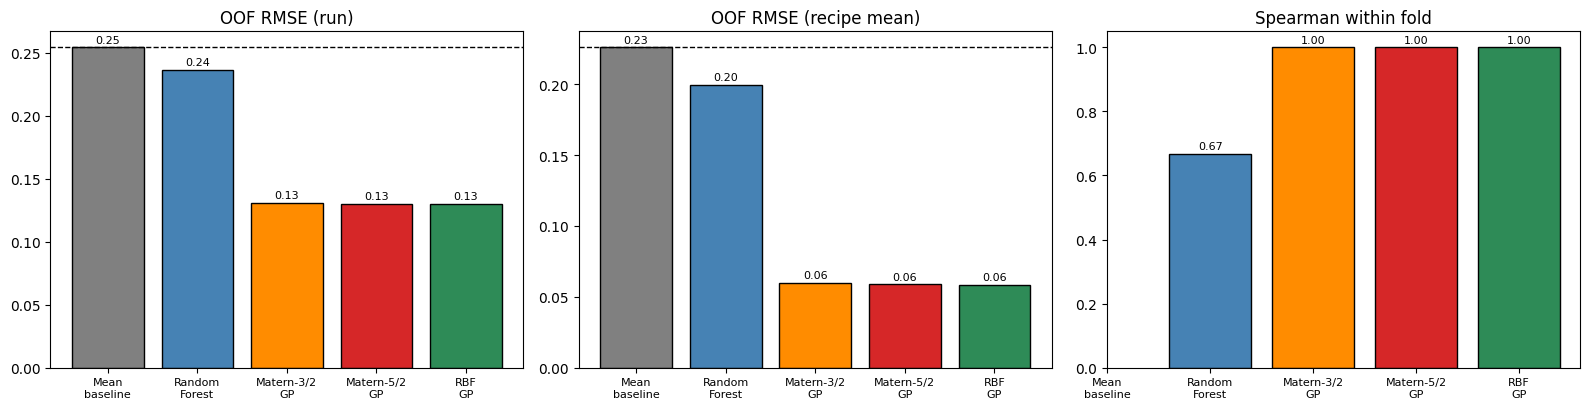

Best GP family by outer-CV RMSE (run): RBF GP  (+48.9% vs the mean baseline).


In [ ]:
y_true = y_ser.to_numpy()
recipe_mean_true = pd.Series(y_true).groupby(groups_arr).transform("mean").to_numpy()      # per-run copy of its recipe mean

def oof_metrics(pred):
    pred = np.asarray(pred, float); err = pred - y_true
    pred_recipe = pd.Series(pred).groupby(groups_arr).transform("mean").to_numpy()          # mean prediction per recipe
    ranks = []
    for _, te in cv_splits:                                       # ranking of the 3 held-out recipes inside each outer fold
        g = pd.DataFrame({"g": groups_arr[te], "p": pred[te], "t": y_true[te]}).groupby("g").mean()
        ranks.append(spearmanr(g.p, g.t)[0] if g.p.nunique() > 1 else np.nan)
    return {"OOF RMSE (run)": np.sqrt(np.mean(err ** 2)), "OOF MAE (run)": np.mean(np.abs(err)),
            "OOF RMSE (recipe mean)": np.sqrt(np.mean((pred_recipe - recipe_mean_true) ** 2)),
            "Spearman within fold": np.nanmean(ranks) if not np.all(np.isnan(ranks)) else np.nan}

leaderboard = pd.DataFrame({n: oof_metrics(p) for n, p in oof_predictions.items()}).T
leaderboard["RMSE reduction vs baseline (%)"] = 100 * (leaderboard.loc["Mean baseline", "OOF RMSE (run)"] - leaderboard["OOF RMSE (run)"]) / leaderboard.loc["Mean baseline", "OOF RMSE (run)"]
display(leaderboard.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
cols = ["grey", "steelblue", "darkorange", "tab:red", "seagreen"]
for ax, m in zip(axes, ["OOF RMSE (run)", "OOF RMSE (recipe mean)", "Spearman within fold"]):
    b = ax.bar(range(len(leaderboard)), leaderboard[m].values, color=cols[:len(leaderboard)], edgecolor="k")
    ax.set_xticks(range(len(leaderboard))); ax.set_xticklabels([n.replace(" ", "\n", 1) for n in leaderboard.index], fontsize=8)
    ax.set_title(m); ax.bar_label(b, fmt="%.2f", padding=2, fontsize=8)
    if "RMSE" in m: ax.axhline(leaderboard.loc["Mean baseline", m], color="k", ls="--", lw=1)
plt.tight_layout(); plt.show()
best_gp_name = leaderboard.loc[list(GP_FAMILIES), "OOF RMSE (run)"].idxmin()
gap = leaderboard.loc[best_gp_name, "RMSE reduction vs baseline (%)"]
print(f"Best GP family by outer-CV RMSE (run): {best_gp_name}  ({gap:+.1f}% vs the mean baseline).")
if gap < 5: print("-> Under 5% better than predicting the average: with 9 recipes and this noise, no surrogate is clearly better than the baseline yet.")

### What did inner CV choose?

Because of the tie rule (Step 1), the chosen structure is stable across folds **partly by construction**: when many candidates tie within `TIE_TOLERANCE`, the pre-declared preferences decide. So the informative number is *how many candidates tie* (shown in the final-tuning table below), not the stability of the choice. If most structures tie, the data cannot distinguish them.


In [ ]:
sel_rows = []
for name in GP_FAMILIES:
    for k, s in enumerate(nested_searches[name], 1):
        sel_rows.append({"Model": name, "Outer fold": k, **s.best_params_, "Inner-CV RMSE": -s.cv_results_["mean_test_score"][s.best_index_]})
sel = pd.DataFrame(sel_rows).set_index(["Model", "Outer fold"]); display(sel.round(3))
for p in ["ard", "batch_effect", "prior", "use_hto"]:
    print(f"{p:>13}: chosen as { {k: int(v) for k, v in sel[p].value_counts().items()} } across the {len(sel)} outer-fold searches")

ard  batch_effect prior  use_hto  Inner-CV RMSE
Model         Outer fold                                                  
Matern-3/2 GP 1           True         False  free    False          0.203
              2           True         False  weak    False          0.183
              3           True         False  weak    False          0.171
Matern-5/2 GP 1           True         False  weak    False          0.205
              2           True         False  weak    False          0.182
              3           True         False  weak    False          0.170
RBF GP        1           True         False  weak    False          0.204
              2           True         False  weak    False          0.181
              3           True         False  weak    False          0.170

          ard: chosen as {True: 9} across the 9 outer-fold searches
 batch_effect: chosen as {False: 9} across the 9 outer-fold searches
        prior: chosen as {'weak': 8, 'free': 1} across the 9 outer-fold searches
      use_hto: chosen as {False: 9} across the 9 outer-fold searches


### Final tuning on all data, and choosing the surrogate for the optimizer

Following V7, the final model for each family is obtained by running the **same tuning procedure on all 18 runs** (candidates compared with the canonical folds, then refit on everything with more optimizer restarts). The nested CV above estimated how good this procedure is; this step actually builds the models.

The surrogate that drives the batch optimizer is `BO_SURROGATE`: by default the GP family with the lowest outer-CV RMSE.


In [ ]:
final_searches, final_models, chosen_params, tie_rows = {}, {}, {}, []
for label, fam in GP_FAMILIES.items():
    s = GridSearchCV(GPSurrogate(family=fam), GP_GRID, scoring=SELECTION_SCORING, cv=cv_splits, refit=False,
                     return_train_score=True, n_jobs=N_JOBS, error_score="raise").fit(X_cv, y_ser)
    final_searches[label] = s
    res = pd.DataFrame(list(s.cv_results_["params"])); res["cv_rmse"] = -s.cv_results_["mean_test_score"]
    i_best, i_pick = int(res["cv_rmse"].idxmin()), int(pick_with_ties(res))           # pure argmax vs argmax-with-tie-rule
    chosen_params[label] = {**res.loc[i_pick].drop("cv_rmse").to_dict(), "family": fam}
    chosen_params[label] = {k: (v.item() if hasattr(v, "item") else v) for k, v in chosen_params[label].items()}
    n_tied = int((res["cv_rmse"] <= res["cv_rmse"].min() * (1 + TIE_TOLERANCE)).sum())
    tie_rows.append({"Model": label, "pure CV argmax": str(res.loc[i_best].drop("cv_rmse").to_dict()), "CV RMSE (argmax)": res.loc[i_best, "cv_rmse"],
                     "candidates tied (within tol.)": f"{n_tied} of {len(res)}", "chosen with tie rule": str(res.loc[i_pick].drop("cv_rmse").to_dict()),
                     "CV RMSE (chosen)": res.loc[i_pick, "cv_rmse"]})
    final_models[label] = GPSurrogate(**chosen_params[label], n_restarts=FINAL_RESTARTS).fit(X_cv, y_ser)
with pd.option_context("display.max_colwidth", 120): display(pd.DataFrame(tie_rows).set_index("Model").round(3))
print(f"Candidates within {100*TIE_TOLERANCE:.0f}% of the best CV RMSE are treated as tied: their differences are far below the noise level, "
      "so the pre-declared STRUCTURE_PREFERENCE decides among them.")

cand = pd.concat([pd.DataFrame(s.cv_results_["params"]).assign(family=GP_FAMILIES[n], cv_rmse=-s.cv_results_["mean_test_score"],
                  train_rmse=-s.cv_results_["mean_train_score"]) for n, s in final_searches.items()], ignore_index=True)
cand = cand.sort_values("cv_rmse").reset_index(drop=True)
print("Ten best GP structures over all 3 families x 16 structures (mean validation RMSE over the canonical folds):")
display(cand.head(10).round(3))
v7 = cand[(~cand.batch_effect) & (cand.prior == "free") & (cand.use_hto)]
print("V7-equivalent corner (no oven offset, free prior, HTO as input):"); display(v7.round(3))

if BO_SURROGATE == "auto":
    gp_rmse = leaderboard.loc[list(GP_FAMILIES), "OOF RMSE (run)"]
    tied_fam = [f for f in FAMILY_PREFERENCE if gp_rmse[f] <= gp_rmse.min() * (1 + TIE_TOLERANCE)]      # ties among families
    BO_NAME = tied_fam[0]
    print(f"Families within {100*TIE_TOLERANCE:.0f}% of the best outer-CV RMSE: {tied_fam} -> using {BO_NAME} (FAMILY_PREFERENCE order)")
else:
    BO_NAME = BO_SURROGATE
bo_est = final_models[BO_NAME]
print(f"\nSurrogate for the batch optimizer: {BO_NAME} with {chosen_params[BO_NAME]}")
H = bo_est.H_
tot = H["amp2"] + H["sb2"] + H["sn2"]
print(f"Variance decomposition (share of total): recipe effect {100*H['amp2']/tot:.0f}%  |  oven-run offset {100*H['sb2']/tot:.0f}%  |  leftover noise {100*H['sn2']/tot:.0f}%")
print("Lengthscales (unit cube; long = variable barely matters):", np.round(H["ls"], 2))

,pure CV argmax,CV RMSE (argmax),candidates tied (within tol.),chosen with tie rule,CV RMSE (chosen)
Model,,,,,
Matern-3/2 GP,"{'ard': True, 'batch_effect': False, 'prior': 'free', 'use_hto': False}",0.123,4 of 16,"{'ard': True, 'batch_effect': False, 'prior': 'weak', 'use_hto': False}",0.124
Matern-5/2 GP,"{'ard': True, 'batch_effect': False, 'prior': 'free', 'use_hto': False}",0.123,4 of 16,"{'ard': True, 'batch_effect': False, 'prior': 'weak', 'use_hto': False}",0.123
RBF GP,"{'ard': True, 'batch_effect': False, 'prior': 'free', 'use_hto': False}",0.123,4 of 16,"{'ard': True, 'batch_effect': False, 'prior': 'weak', 'use_hto': False}",0.123


Candidates within 2% of the best CV RMSE are treated as tied: their differences are far below the noise level, so the pre-declared STRUCTURE_PREFERENCE decides among them.
Ten best GP structures over all 3 families x 16 structures (mean validation RMSE over the canonical folds):


,ard,batch_effect,prior,use_hto,family,cv_rmse,train_rmse
0,True,False,free,False,rbf,0.123,0.121
1,True,False,free,False,matern52,0.123,0.121
2,True,False,free,False,matern32,0.123,0.121
3,True,False,weak,False,rbf,0.123,0.121
4,True,False,weak,False,matern52,0.123,0.121
5,True,False,weak,False,matern32,0.124,0.121
6,True,False,free,True,rbf,0.125,0.118
7,True,False,free,True,matern52,0.125,0.118
8,True,False,free,True,matern32,0.125,0.118
9,True,False,weak,True,rbf,0.125,0.118


V7-equivalent corner (no oven offset, free prior, HTO as input):


,ard,batch_effect,prior,use_hto,family,cv_rmse,train_rmse
6,True,False,free,True,rbf,0.125,0.118
7,True,False,free,True,matern52,0.125,0.118
8,True,False,free,True,matern32,0.125,0.118
25,False,False,free,True,rbf,0.210,0.126
29,False,False,free,True,matern52,0.213,0.126
32,False,False,free,True,matern32,0.216,0.126


Families within 2% of the best outer-CV RMSE: ['Matern-5/2 GP', 'Matern-3/2 GP', 'RBF GP'] -> using Matern-5/2 GP (FAMILY_PREFERENCE order)

Surrogate for the batch optimizer: Matern-5/2 GP with {'ard': True, 'batch_effect': False, 'prior': 'weak', 'use_hto': False, 'family': 'matern52'}
Variance decomposition (share of total): recipe effect 71%  |  oven-run offset 0%  |  leftover noise 29%
Lengthscales (unit cube; long = variable barely matters): [0.2 5.  5. ]


## Step 4b: Model Calibration & Quality Metrics (LML and NLPD)

To evaluate our Gaussian Process models on probabilistic grounds rather than just point prediction error (RMSE):
1. **Log Marginal Likelihood (LML)**: Evaluated on the training data. Higher values indicate a GP structure that explains the dataset well with low complexity.
2. **Negative Log Predictive Density (NLPD)**: Evaluated on held-out outer folds. Lower values indicate better calibrated predictive uncertainty (less over-confidence or under-confidence).


## Deep Dive: Log Marginal Likelihood (LML) vs. Negative Log Predictive Density (NLPD)

When evaluating Bayesian optimization elements, metrics like **Log Marginal Likelihood (LML)** and **Negative Log Predictive Density (NLPD)** assess model quality rather than decision quality. Here is how they differ and where they should be applied:

### 1. Log Marginal Likelihood (LML)
* **What it measures:** The plausibility of the observed training data $y$ given the GP structure and hyperparameters, integrated over all possible latent function values:
  $$\log p(y \mid X, \theta) = -\frac{1}{2} y^T (K_y)^{-1} y - \frac{1}{2} \log |K_y| - \frac{n}{2} \log(2\pi)$$
* **When to use it:** During **model training / hyperparameter optimization**. LML automatically balances data fit (the first quadratic term) with model complexity (the second log-determinant complexity penalty).
* **Is it for kernels?** Yes, absolutely. It is used to fit lengthscales, amplitudes, and noise levels within a single kernel family, or to perform Bayesian model selection between different families (e.g., Matérn-5/2 vs. RBF).

### 2. Negative Log Predictive Density (NLPD)
* **What it measures:** How well the model's probabilistic predictions match unseen test data $y_*$, accounting for both predicted mean $\mu_*$ and predicted uncertainty $\sigma_*^2$:
  $$\text{NLPD} = \frac{1}{2} \log(2\pi \sigma_*^2) + \frac{(y_* - \mu_*)^2}{2 \sigma_*^2}$$
* **When to use it:** During **cross-validation (model evaluation)**. Unlike RMSE (which only checks the mean $\mu_*$), NLPD penalizes both over-confidence (small $\sigma_*$ with large prediction error) and under-confidence (unnecessarily large $\sigma_*$).
* **Is it for kernels?** Yes. It is the gold standard for validating whether the GP kernel's posterior uncertainty quantification is mathematically calibrated.

### Comparison Table: Model Quality vs. Decision Quality

| Metric | Level Evaluated | Focuses On | Ideal For |
|---|---|---|---|
| **LML** | In-Sample / Training | Structural Plausibility & Complexity | Tuning hyperparameters ($\theta$) and selecting kernels |
| **NLPD** | Out-of-Fold / Cross-Validation | Uncertainty Calibration & Probabilistic Accuracy | Assessing whether GP confidence intervals are trustworthy |
| **Simple Regret / Hit Rate** | Offline Replay / Decision | Finding Optimums (Exploitation vs. Exploration) | Comparing Acquisition Functions & Batch Strategies (EI vs. UCB vs. q-NEI) |


In [ ]:
def calculate_nlpd(y_true, y_mean, y_std):
    """Calculate Negative Log Predictive Density (NLPD)."""
    y_true = np.asarray(y_true, dtype=float)
    y_mean = np.asarray(y_mean, dtype=float)
    y_std = np.maximum(np.asarray(y_std, dtype=float), 1e-8)
    return 0.5 * np.log(2 * np.pi * (y_std ** 2)) + ((y_true - y_mean) ** 2) / (2 * (y_std ** 2))

# --- 1. Compute Out-Of-Fold NLPD for each GP family ---
calibration_records = []
for name in GP_FAMILIES:
    search_folds = nested_searches[name]
    # We collect predictions and true outcomes across all outer folds
    fold_nlpds = []
    for k, (tr, te) in enumerate(cv_splits):
        best_est = search_folds[k].best_estimator_
        pred_mean, pred_std = best_est.predict(X_cv.iloc[te], return_std=True)
        y_te = y_ser.iloc[te].to_numpy()

        # Compute individual run NLPds and average for the fold
        run_nlpds = calculate_nlpd(y_te, pred_mean, pred_std)
        fold_nlpds.append(np.mean(run_nlpds))

    calibration_records.append({
        "Model": name,
        "OOF NLPD (Mean)": np.mean(fold_nlpds),
        "OOF NLPD (Fold 1)": fold_nlpds[0],
        "OOF NLPD (Fold 2)": fold_nlpds[1],
        "OOF NLPD (Fold 3)": fold_nlpds[2]
    })

df_nlpd = pd.DataFrame(calibration_records).set_index("Model")

# --- 2. Compute Log Marginal Likelihood (LML) on the fully fitted models ---
lml_records = []
for name, est in final_models.items():
    # The negative marginal likelihood is stored as 'nll' in H_
    nll = est.H_.get("nll", np.nan)
    lml_records.append({
        "Model": name,
        "Log Marginal Likelihood (LML)": -nll
    })
df_lml = pd.DataFrame(lml_records).set_index("Model")

# --- Display Results ---
print("### Model Quality Metrics comparison")
quality_summary = df_nlpd.join(df_lml)
display(quality_summary.round(4))

### Model Quality Metrics comparison


,OOF NLPD (Mean),OOF NLPD (Fold 1),OOF NLPD (Fold 2),OOF NLPD (Fold 3),Log Marginal Likelihood (LML)
Model,,,,,
Matern-3/2 GP,-0.0274,-1.1428,-0.4867,1.5472,-18.5021
Matern-5/2 GP,0.1181,-1.1442,-0.4423,1.9408,-18.4254
RBF GP,0.2699,-1.1396,-0.3994,2.3489,-18.3612


## Step 4c: Predicted vs. actual — nested-CV performance by GP kernel

These plots use the **outer-fold out-of-fold (OOF) predictions** already generated by
`nested_cv`. Each point is a held-out experimental run: the model that predicted it
was tuned using only the corresponding outer-training data. The RMSE printed in each
panel is calculated from exactly the same OOF prediction vector and target vector.

The target is `avg_Ln_AR` (log aspect ratio), so RMSE is in log-AR units. The panels
compare kernel families; within each family, hyperparameters/structure were selected
independently inside each outer fold by the existing nested-CV procedure.


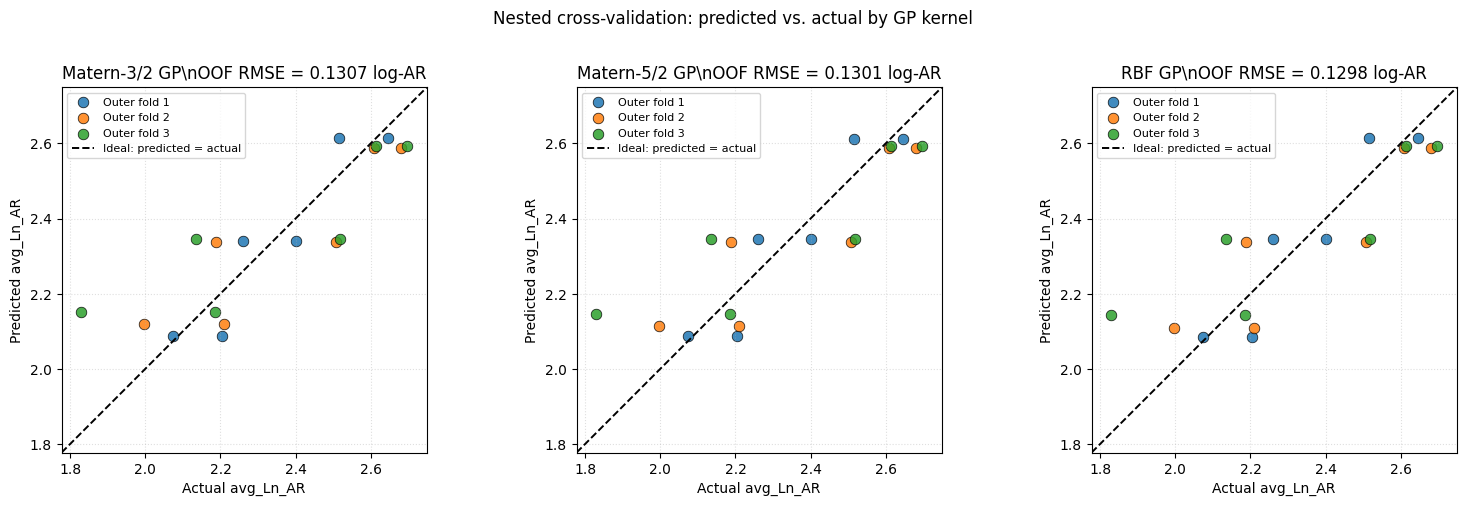

,OOF RMSE (log-AR)
RBF GP,0.12981
Matern-5/2 GP,0.13011
Matern-3/2 GP,0.13069


In [ ]:
# Predicted-vs-actual plots for each optimized GP kernel family.
# These are honest outer-CV predictions, not in-sample predictions from final_models.

from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
import numpy as np

gp_names = list(GP_FAMILIES.keys())
n_models = len(gp_names)
fig, axes = plt.subplots(1, n_models, figsize=(5.2 * n_models, 4.8), squeeze=False)
axes = axes.ravel()

# Record which outer fold held out each observation.
fold_id = np.full(len(y_true), -1, dtype=int)
for fold_number, (_, test_idx) in enumerate(cv_splits, start=1):
    fold_id[test_idx] = fold_number

for ax, model_name in zip(axes, gp_names):
    actual = np.asarray(y_true, dtype=float)
    predicted = np.asarray(oof_predictions[model_name], dtype=float)
    valid = np.isfinite(actual) & np.isfinite(predicted)
    rmse = float(np.sqrt(mean_squared_error(actual[valid], predicted[valid])))

    for fold_number in sorted(np.unique(fold_id[valid])):
        mask = valid & (fold_id == fold_number)
        ax.scatter(
            actual[mask], predicted[mask], s=58, alpha=0.85,
            edgecolor="black", linewidth=0.55, label=f"Outer fold {fold_number}"
        )

    lo = float(min(actual[valid].min(), predicted[valid].min()))
    hi = float(max(actual[valid].max(), predicted[valid].max()))
    pad = 0.06 * (hi - lo if hi > lo else 1.0)
    limits = (lo - pad, hi + pad)
    ax.plot(limits, limits, "k--", lw=1.4, label="Ideal: predicted = actual")
    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(f"{model_name}\\nOOF RMSE = {rmse:.4f} log-AR")
    ax.set_xlabel("Actual avg_Ln_AR")
    ax.set_ylabel("Predicted avg_Ln_AR")
    ax.grid(True, ls=":", alpha=0.4)
    ax.legend(fontsize=8, loc="best")

plt.suptitle("Nested cross-validation: predicted vs. actual by GP kernel", y=1.03)
plt.tight_layout()
plt.show()

# A compact metric table, calculated from the same OOF vectors plotted above.
gp_oof_rmse = {
    name: float(np.sqrt(mean_squared_error(y_true, oof_predictions[name])))
    for name in gp_names
}
display(
    pd.DataFrame.from_dict(gp_oof_rmse, orient="index", columns=["OOF RMSE (log-AR)"])
      .sort_values("OOF RMSE (log-AR)")
      .round(5)
)


## Step 4d: Is there any evidence of a recipe effect at all?

Compare the chosen model with a **null model** (same structure, smooth recipe effect switched off: only oven offsets and noise). A log-likelihood gain below about 2 nats means the data cannot tell the difference. (Heuristic, not a formal test.) If there is no evidence, every batch below is mostly exploration driven by the prior, and the *design* of the experiments (how recipes are spread over oven runs) is what will make the next round informative.


In [ ]:
null_est = clone(bo_est).set_params(signal=False, n_restarts=FINAL_RESTARTS).fit(X_cv, y_ser)
gain = null_est.H_["nll"] - bo_est.H_["nll"]
print(f"Log-likelihood gain from a smooth recipe effect: {gain:.2f} nats")
print("-> Weak/no evidence for a recipe effect: treat batches as exploration." if gain < 2 else "-> The data support a smooth recipe effect.")

Log-likelihood gain from a smooth recipe effect: 7.12 nats
-> The data support a smooth recipe effect.


## Step 4e: Does a tree-boosting model (XGBoost) do better than the GP?

**What.** Adds XGBoost to the same comparison as the mean baseline, the Random Forest and the GPs. *Part 1* runs XGBoost through the same nested CV, folds and metrics, then draws parity plots and a time slice of the GP next to XGBoost. *Part 2* replays acquisition: a bootstrap-over-recipes ensemble of XGBoost models provides the uncertainty XGBoost lacks, and picks are compared with the GP's on the same partitions.

**Why.** It answers whether the GP is needed at this data size. Trees can only draw flat steps and give no built-in uncertainty, which matters for a surrogate that has to explore. Both parts reuse `nested_cv`, `oof_metrics` and `replay_partitions`, so differences come from the models, not from the splits.

XGBoost nested CV done in 24s


,Fold,Inner-CV RMSE,Held-out RMSE,Selected
0,1,0.157,0.199,"{'xgb__learning_rate': 0.1, 'xgb__max_depth': ..."
1,2,0.167,0.126,"{'xgb__learning_rate': 0.1, 'xgb__max_depth': ..."
2,3,0.127,0.329,"{'xgb__learning_rate': 0.3, 'xgb__max_depth': ..."


,OOF RMSE (run),OOF MAE (run),OOF RMSE (recipe mean),Spearman within fold,RMSE reduction vs baseline (%)
Mean baseline,0.254,0.228,0.226,NaN,0.000
Random Forest,0.236,0.196,0.200,0.667,7.047
Matern-3/2 GP,0.131,0.106,0.060,1.000,48.572
Matern-5/2 GP,0.130,0.106,0.059,1.000,48.801
RBF GP,0.130,0.106,0.058,1.000,48.918
XGBoost,0.234,0.191,0.203,0.667,8.013


Replicate noise SD ≈ 0.164 log-AR: a model can hardly get per-run RMSE much below this, so the 'RMSE (recipe mean)' column is the fairer yardstick for differences between models.


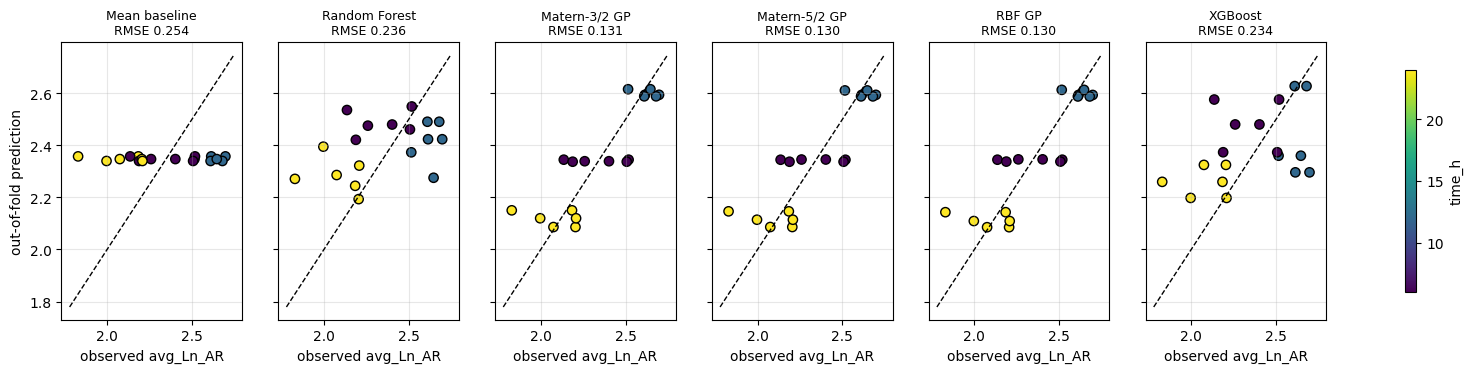

XGBoost settings used for the slice (most often chosen by inner CV): {'xgb__learning_rate': 0.1, 'xgb__max_depth': 3, 'xgb__min_child_weight': 2, 'xgb__n_estimators': 25, 'xgb__reg_lambda': 0.0}


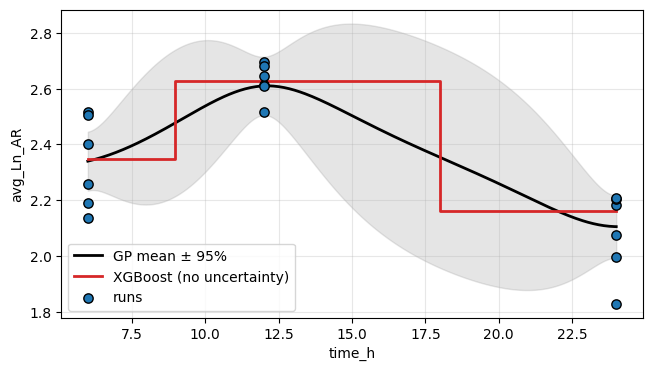

30 trials per model/acquisition, 22s. Regret in log-AR units (0 = perfect, lower is better).


regret  hit_rate  trials  advantage_over_random
model            acquisition                                                   
RBF GP           EI              0.017     0.911      30                  0.233
                 Greedy mean     0.011     0.900      30                  0.239
                 UCB (kappa=2)   0.014     0.900      30                  0.237
XGBoost ensemble EI              0.073     0.733      30                  0.178
                 Greedy mean     0.038     0.733      30                  0.213
                 UCB (kappa=2)   0.102     0.667      30                  0.148

Trials share the same 9 recipes, so treat differences of a few hundredths as noise.


In [ ]:
# ############ Part 1: nested-CV leaderboard, parity plots, time slice ############
# ===================== XGBoost vs GP, part 1: same nested CV, same folds, same metrics =====================
# Runs after the leaderboard cell (needs: X_cv, y_ser, groups_arr, cv_splits, nested_cv, oof_predictions, oof_metrics,
# nested_searches, GP_FAMILIES, bo_est, df). If xgboost is missing in Colab:  !pip -q install xgboost
from collections import Counter
from xgboost import XGBRegressor
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

XGB_INPUTS = OPT_VARS      # the 3 variables the BO optimises (the notebook's Random Forest also sees hto_mass_g)
xgb_model = Pipeline([("select", ColumnTransformer([("keep", "passthrough", XGB_INPUTS)], remainder="drop")),
                      ("xgb", XGBRegressor(objective="reg:squarederror", tree_method="exact", random_state=SEED, n_jobs=1))])
# Deliberately tiny, shallow trees: with 12 training runs a deep boosted model just memorises the runs.
# min_child_weight=2 means "a leaf needs >= 2 runs" (squared error: each run has weight 1), i.e. roughly one recipe's replicates.
XGB_GRID = {"xgb__max_depth": [1, 2, 3], "xgb__n_estimators": [25, 50, 100, 200], "xgb__learning_rate": [0.05, 0.1, 0.3],
            "xgb__reg_lambda": [0.0, 1.0], "xgb__min_child_weight": [1, 2]}                       # 144 candidates

t0 = time.time()
oof_predictions["XGBoost"], xgb_tab, nested_searches["XGBoost"] = nested_cv("XGBoost", xgb_model, XGB_GRID)   # same engine as the GPs and the RF
print(f"XGBoost nested CV done in {time.time() - t0:.0f}s")
display(xgb_tab.drop(columns="Model").round(3))

keep = [n for n in ["Mean baseline", "Random Forest", *GP_FAMILIES, "XGBoost"] if n in oof_predictions]
lb = pd.DataFrame({n: oof_metrics(oof_predictions[n]) for n in keep}).T
lb["RMSE reduction vs baseline (%)"] = 100 * (lb.loc["Mean baseline", "OOF RMSE (run)"] - lb["OOF RMSE (run)"]) / lb.loc["Mean baseline", "OOF RMSE (run)"]
display(lb.round(3))
noise_sd = float(np.sqrt(df.groupby(groups_arr)[TARGET].var(ddof=1).mean()))
print(f"Replicate noise SD ≈ {noise_sd:.3f} log-AR: a model can hardly get per-run RMSE much below this, so the "
      f"'RMSE (recipe mean)' column is the fairer yardstick for differences between models.")

# ---- parity plots: out-of-fold prediction vs observation, coloured by time ----
fig, axes = plt.subplots(1, len(keep), figsize=(3.4 * len(keep), 3.6), sharex=True, sharey=True)
for ax, n in zip(np.atleast_1d(axes), keep):
    sc = ax.scatter(y_ser, oof_predictions[n], c=df["time_h"], cmap="viridis", edgecolor="k", s=45)
    lim = [y_ser.min() - 0.05, y_ser.max() + 0.05]; ax.plot(lim, lim, "k--", lw=1)
    ax.set_title(f"{n}\nRMSE {lb.loc[n, 'OOF RMSE (run)']:.3f}", fontsize=9); ax.set_xlabel("observed " + TARGET); ax.grid(alpha=0.3)
np.atleast_1d(axes)[0].set_ylabel("out-of-fold prediction"); fig.colorbar(sc, ax=axes, label="time_h", shrink=0.8); plt.show()

# ---- what each model does between the data: slice along time (BaOH and water at their medians) ----
def mode_params(searches):
    return dict(Counter(tuple(sorted(s.best_params_.items())) for s in searches).most_common(1)[0][0])
xgb_final = clone(xgb_model).set_params(**mode_params(nested_searches["XGBoost"])).fit(X_cv, y_ser)
print("XGBoost settings used for the slice (most often chosen by inner CV):", mode_params(nested_searches["XGBoost"]))
tg = np.linspace(*BOUNDS["time_h"], 300); med = {v: df[v].median() for v in OPT_VARS}
raw = pd.DataFrame({v: (tg if v == "time_h" else np.full(300, med[v])) for v in OPT_VARS})
A = np.column_stack([raw.to_numpy(), np.full((300, 1), df["hto_mass_g"].median()), np.zeros(300)])
mu_g, sd_g = bo_est.predict(A, return_std=True)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.fill_between(tg, mu_g - 1.96 * sd_g, mu_g + 1.96 * sd_g, color="gray", alpha=0.2); ax.plot(tg, mu_g, "k", lw=2, label="GP mean ± 95%")
ax.step(tg, xgb_final.predict(raw), color="tab:red", lw=2, where="mid", label="XGBoost (no uncertainty)")
ax.scatter(df["time_h"], y_ser, c="tab:blue", edgecolor="k", s=45, zorder=5, label="runs"); ax.set_xlabel("time_h"); ax.set_ylabel(TARGET)
ax.legend(); ax.grid(alpha=0.3); plt.show()


# ############ Part 2: acquisition replay (does it PICK well?) ############
# ===================== XGBoost vs GP, part 2: do they PICK well? (acquisition replay on the same partitions) =====================
# Same game as the notebook's replay: train on some recipes, then choose ONE of the held-out recipes; regret = best held-out AR minus the pick.
# XGBoost has no uncertainty of its own, so it gets a bootstrap-over-recipes ensemble: mean and SD across members.
from scipy.stats import norm
XGB_REPLAY_REPEATS = 10          # random 3-recipe partitions (30 in the notebook's replay); raise for smoother numbers (slower)
N_MEMBERS = 40
xgb_params = mode_params(nested_searches["XGBoost"])

class BootstrapXGB:
    def __init__(self, params, n_members=N_MEMBERS, seed=SEED): self.params, self.n, self.seed = params, n_members, seed
    def fit(self, X, y, groups):
        r = np.random.default_rng(self.seed); ids = np.unique(groups); self.members = []
        for _ in range(self.n):
            draw = r.choice(ids, size=len(ids), replace=True)                       # resample RECIPES, not runs
            idx = np.concatenate([np.where(groups == g)[0] for g in draw])
            self.members.append(clone(xgb_model).set_params(**self.params).fit(X.iloc[idx], y.iloc[idx]))
        return self
    def predict(self, X):
        P = np.column_stack([m.predict(X) for m in self.members]); return P.mean(1), P.std(1)

def acq_scores(mu, sd, best, kappa=2.0):
    z = (mu - best) / np.maximum(sd, 1e-9)
    return {"Greedy mean": mu, "UCB (kappa=2)": mu + kappa * sd, "EI": (mu - best) * norm.cdf(z) + sd * norm.pdf(z)}

gp_label = best_gp_name if "best_gp_name" in globals() else list(GP_FAMILIES)[0]
gp_params = chosen_params[gp_label]
rows = []; t0 = time.time()
for rep, part in enumerate(replay_partitions[:XGB_REPLAY_REPEATS]):
    for fold, (tr, te) in enumerate(part):
        gte = groups_arr[te]
        Xp = X_cv.iloc[te].groupby(gte).mean()                                       # pool = the held-out recipes
        truth = y_ser.iloc[te].groupby(gte).mean().loc[Xp.index].to_numpy()          # their true mean log-AR
        best_tr = y_ser.iloc[tr].groupby(groups_arr[tr]).mean().max()                # incumbent = best training recipe
        mu_g, sd_g = GPSurrogate(**gp_params, n_restarts=CV_RESTARTS).fit(X_cv.iloc[tr], y_ser.iloc[tr]).predict(Xp, return_std=True)
        mu_x, sd_x = BootstrapXGB(xgb_params).fit(X_cv.iloc[tr], y_ser.iloc[tr], groups_arr[tr]).predict(Xp)
        for model, (mu, sd) in {gp_label: (mu_g, sd_g), "XGBoost ensemble": (mu_x, sd_x)}.items():
            for acq, s in acq_scores(mu, sd, best_tr).items():
                tied = np.flatnonzero(np.isclose(s, s.max()))                        # exact ties (flat trees) are broken at random, in expectation
                rows.append({"model": model, "acquisition": acq, "regret": np.mean(truth.max() - truth[tied]),
                             "hit": np.mean(tied == np.argmax(truth)), "random_regret": truth.max() - truth.mean()})
res = pd.DataFrame(rows)
summary = res.groupby(["model", "acquisition"]).agg(regret=("regret", "mean"), hit_rate=("hit", "mean"), random_regret=("random_regret", "mean"), trials=("regret", "size"))
summary["advantage_over_random"] = summary["random_regret"] - summary["regret"]
print(f"{len(res) // 6} trials per model/acquisition, {time.time() - t0:.0f}s. Regret in log-AR units (0 = perfect, lower is better).")
display(summary.drop(columns="random_regret").round(3))
print("Trials share the same 9 recipes, so treat differences of a few hundredths as noise.")

### Hand-over: from the CV-selected GP to the batch optimizer

The optimizer needs more than predictions: it needs the fitted GP, the training data and a candidate pool in one place. `BOContext` bundles exactly that. **Every strategy below takes a `BOContext`**, so the same code runs (a) on the real data to propose Round-2 experiments and (b) on a CV training fold in the replay of Step 10b. Same implementation, two uses: that is what makes the comparison fair.


In [ ]:
class BOContext:
    """Everything a batch-selection strategy needs: fitted GP (H), training data, and the candidate pool."""
    def __init__(self, H, X_tr, y_tr, b_tr, feas_tr, rec_tr, X_pool, U_pool, y_mean, y_sd, acq_name=None):
        self.H, self.X_tr, self.y_tr, self.b_tr, self.feas_tr = H, X_tr, y_tr, b_tr, feas_tr
        self.X_pool, self.U_pool, self.y_mean, self.y_sd = X_pool, U_pool, y_mean, y_sd
        self.acq_name = ACQ_NAME if acq_name is None else acq_name
        # recipe-level view (one row per distinct recipe): used for the "incumbent" (current best)
        ids = np.unique(rec_tr)
        self.X_rec = np.array([X_tr[rec_tr == g].mean(axis=0) for g in ids])
        self.feas_rec = np.array([feas_tr[rec_tr == g].all() for g in ids])
        if not self.feas_rec.any(): self.feas_rec[:] = True
        mu_rec, _ = self.predict(self.X_rec)
        self.best_f = mu_rec[self.feas_rec].max()        # robust incumbent: best posterior mean of f among accepted recipes
        self.y_obs_max = y_tr[feas_tr].max() if feas_tr.any() else y_tr.max()   # largest raw measurement (oven offset included)
        self.mu_pool, var = self.predict(X_pool)
        self.sd_pool = np.sqrt(var)
    def predict(self, Xs, X=None, y=None, b=None, full_cov=False):
        """Latent-f posterior. Default: real training data. Pass (X, y, b) to condition on real data + fantasy points."""
        return posterior(self.H, self.X_tr if X is None else X, self.y_tr if y is None else y,
                         self.b_tr if b is None else b, Xs, full_cov)
    def with_acq(self, name):
        c = copy.copy(self); c.acq_name = name; return c

## Step 5: Common candidate pool

All strategies choose from the **same list of possible experiments**. A regular grid over the bounds (lab-realistic step sizes), minus lab constraints, minus near-repeats of recipes already run. If the CV-selected GP uses HTO, candidates get a constant HTO value (it is never optimized).


In [ ]:
HTO_FIXED = float(df["hto_mass_g"].median()) if HTO_FIXED is None else HTO_FIXED

def to_model(raw_opt, use_hto):
    """raw (hours, g, mL) -> unit-cube model inputs (+ constant HTO column if the surrogate uses HTO)."""
    U = (np.atleast_2d(raw_opt) - LO) / (HI - LO)
    if use_hto:
        U = np.column_stack([U, np.full(len(U), (HTO_FIXED - HTO_RANGE[0]) / (HTO_RANGE[1] - HTO_RANGE[0]))])
    return U

axes_vals = [np.round(np.arange(BOUNDS[v][0], BOUNDS[v][1] + STEP[v] / 2, STEP[v]), 4) for v in OPT_VARS]
pool_raw = np.column_stack([g.ravel() for g in np.meshgrid(*axes_vals, indexing="ij")])
pool_df = pd.DataFrame(pool_raw, columns=OPT_VARS)

U_obs = (df[OPT_VARS].values - LO) / (HI - LO)                      # optimization variables of the tested runs, unit cube
keep = np.asarray(lab_constraints(pool_df), dtype=bool)
if ALLOWED_TIMES is not None: keep &= pool_df["time_h"].isin(ALLOWED_TIMES).values
keep &= cdist((pool_raw - LO) / (HI - LO), U_obs).min(axis=1) >= EXCLUDE_RADIUS
pool_raw, pool_df = pool_raw[keep], pool_df[keep].reset_index(drop=True)
U_pool = (pool_raw - LO) / (HI - LO)
X_pool = to_model(pool_raw, bo_est.use_hto)
print(f"Candidate pool: {len(pool_df):,} recipes")

# ---- the context used for the real Round-2 proposal ----
ctx = BOContext(bo_est.H_, bo_est.U_, bo_est.ys_, bo_est.b_, df["feasible"].values, groups_arr, X_pool, U_pool,
                bo_est.y_mean_, bo_est.y_sd_)
Y_MEAN, Y_SD = ctx.y_mean, ctx.y_sd
print(f"Incumbent = {np.exp(ctx.best_f * Y_SD + Y_MEAN):.2f} geometric-mean AR (best posterior mean of an accepted recipe); "
      f"largest raw measurement = {np.exp(ctx.y_obs_max * Y_SD + Y_MEAN):.2f}")

Candidate pool: 51,218 recipes
Incumbent = 13.61 geometric-mean AR (best posterior mean of an accepted recipe); largest raw measurement = 14.84


**What did the selected GP learn?** Predicted geometric-mean AR over time × Ba(OH)₂ mass at three water volumes. The colour scale matters: if it spans only a fraction of an AR unit, the surface is nearly flat and the model has found little to exploit.


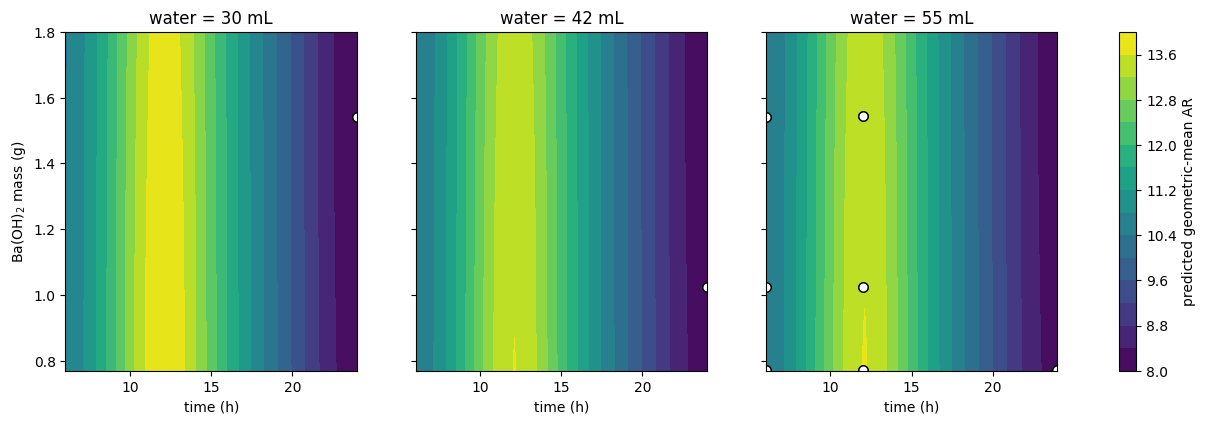

Predicted log-AR spans 0.520 units across the whole candidate pool (compare with the replicate scatter in Step 3).


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)
gt, gb = np.linspace(LO[0], HI[0], 60), np.linspace(LO[1], HI[1], 60); Tm, Bm = np.meshgrid(gt, gb)
for ax, w in zip(axes, np.linspace(LO[2], HI[2], 3)):
    raw = np.column_stack([Tm.ravel(), Bm.ravel(), np.full(Tm.size, w)])
    mu_s, _ = ctx.predict(to_model(raw, bo_est.use_hto))
    cs = ax.contourf(Tm, Bm, np.exp(mu_s * Y_SD + Y_MEAN).reshape(Tm.shape), levels=15, cmap="viridis")
    near = (df["water_initial_ml"] - w).abs() <= 6
    ax.scatter(df.loc[near, "time_h"], df.loc[near, "baoh_mass_g"], c="white", edgecolor="k", s=45)
    ax.set_title(f"water = {w:.0f} mL"); ax.set_xlabel("time (h)")
axes[0].set_ylabel("Ba(OH)$_2$ mass (g)"); fig.colorbar(cs, ax=axes, label="predicted geometric-mean AR"); plt.show()
print(f"Predicted log-AR spans {np.ptp(ctx.mu_pool) * Y_SD:.3f} units across the whole candidate pool "
      "(compare with the replicate scatter in Step 3).")

### 2D cuts of the predicted surface (continued from the previous plot)

**What.** Two more views of the same selected GP: *time vs. initial water* at three Ba(OH)₂ masses, and *Ba(OH)₂ mass vs. initial water* at three reaction times. White dots are the runs close to each cut.

**Why.** The previous plot only covers one pair of variables. Together, the three pairs show whether any combination of conditions stands out, or whether the predicted surface is flat in some direction.

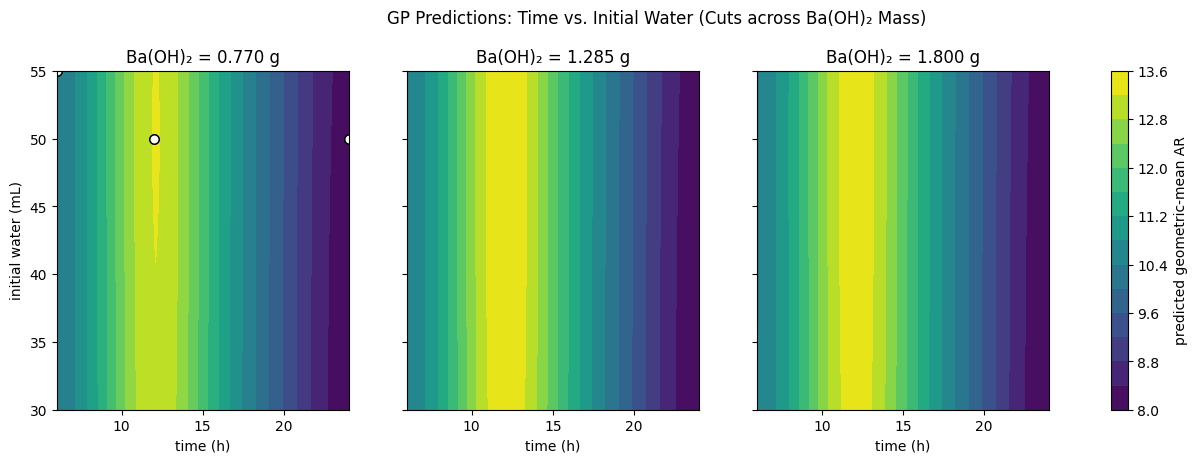

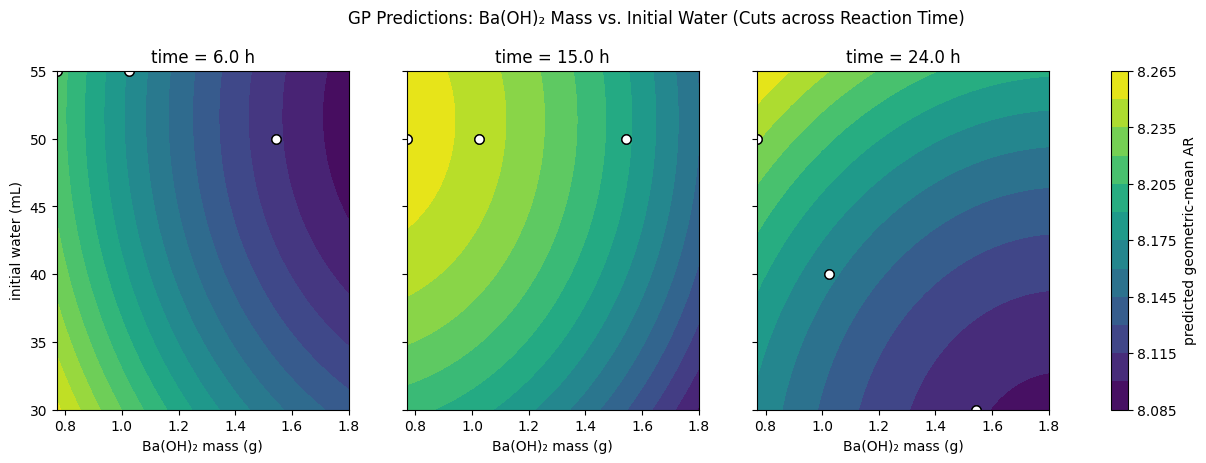

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Proyecciones de Tiempo vs. Volumen de Agua (Masa de Ba(OH)2 fija) ---
fig1, axes1 = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)
gt, gw = np.linspace(LO[0], HI[0], 60), np.linspace(LO[2], HI[2], 60)
Tm, Wm = np.meshgrid(gt, gw)

# Mostramos 3 cortes en la masa de Ba(OH)2
baoh_cuts = np.linspace(LO[1], HI[1], 3)
for ax, b_val in zip(axes1, baoh_cuts):
    raw = np.column_stack([Tm.ravel(), np.full(Tm.size, b_val), Wm.ravel()])
    mu_s, _ = ctx.predict(to_model(raw, bo_est.use_hto))
    cs = ax.contourf(Tm, Wm, np.exp(mu_s * Y_SD + Y_MEAN).reshape(Tm.shape), levels=15, cmap="viridis")
    near = (df["baoh_mass_g"] - b_val).abs() <= 0.15
    ax.scatter(df.loc[near, "time_h"], df.loc[near, "water_initial_ml"], c="white", edgecolor="k", s=45)
    ax.set_title(f"Ba(OH)₂ = {b_val:.3f} g")
    ax.set_xlabel("time (h)")

axes1[0].set_ylabel("initial water (mL)")
fig1.colorbar(cs, ax=axes1, label="predicted geometric-mean AR")
plt.suptitle("GP Predictions: Time vs. Initial Water (Cuts across Ba(OH)₂ Mass)", y=1.02, fontsize=12)
plt.show()

# --- 2. Proyecciones de Masa de Ba(OH)2 vs. Volumen de Agua (Tiempo fijo) ---
fig2, axes2 = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)
gb, gw = np.linspace(LO[1], HI[1], 60), np.linspace(LO[2], HI[2], 60)
Bm, Wm = np.meshgrid(gb, gw)

# Mostramos 3 cortes en el tiempo de reacción
time_cuts = np.linspace(LO[0], HI[0], 3)
for ax, t_val in zip(axes2, time_cuts):
    raw = np.column_stack([np.full(Bm.size, t_val), Bm.ravel(), Wm.ravel()])
    mu_s, _ = ctx.predict(to_model(raw, bo_est.use_hto))
    cs = ax.contourf(Bm, Wm, np.exp(mu_s * Y_SD + Y_MEAN).reshape(Bm.shape), levels=15, cmap="viridis")
    near = (df["time_h"] - t_val).abs() <= 3.0
    ax.scatter(df.loc[near, "baoh_mass_g"], df.loc[near, "water_initial_ml"], c="white", edgecolor="k", s=45)
    ax.set_title(f"time = {t_val:.1f} h")
    ax.set_xlabel("Ba(OH)₂ mass (g)")

axes2[0].set_ylabel("initial water (mL)")
fig2.colorbar(cs, ax=axes2, label="predicted geometric-mean AR")
plt.suptitle("GP Predictions: Ba(OH)₂ Mass vs. Initial Water (Cuts across Reaction Time)", y=1.02, fontsize=12)
plt.show()

### Shared tools: acquisition functions and the "incumbent"

An **acquisition function** turns (μ, σ) into one number: how attractive is this experiment?
* **UCB** = μ + κσ. **EI** = expected amount by which the experiment beats the current best. **PI** = probability of beating it.
* **NEI** (noisy EI) = EI where the current best is itself uncertain: draw many plausible true values of the tested recipes, take the best in each draw as the incumbent, compute EI against it, average. It is q-NEI (Step 8) with a batch of one.

**Incumbent.** Measurements are noisy and oven runs shift all their recipes, so the largest raw value is partly luck. EI/PI use instead the **best posterior mean of f among accepted tested recipes**. All acquisition values use σ of the latent f.


In [ ]:
def acq_ucb(mu, sd, best_f): return mu + KAPPA * sd
def acq_ei(mu, sd, best_f):
    z = (mu - best_f - XI) / sd
    return (mu - best_f - XI) * norm.cdf(z) + sd * norm.pdf(z)
def acq_pi(mu, sd, best_f): return norm.cdf((mu - best_f - XI) / sd)
ACQS = {"UCB": acq_ucb, "EI": acq_ei, "PI": acq_pi}

def safe_cholesky(cov, base_jitter=1e-6):
    """Cholesky of a covariance that may be numerically singular (near-duplicate points): add growing jitter."""
    jit = base_jitter * np.mean(np.diag(cov))
    for _ in range(8):
        try: return cholesky(cov + jit * np.eye(len(cov)), lower=True)
        except Exception: jit *= 10
    raise np.linalg.LinAlgError("covariance not positive definite even with jitter")

def nei_pool(ctx, X_tr=None, y_tr=None, b_tr=None, n_samples=NEI_SAMPLES, seed=SEED, chunk=4000):
    """Noisy EI of every pool candidate (standardized units).
    1) Draw S joint samples of f at the tested recipes. In sample s the incumbent is inc_s = best sampled f among accepted recipes.
    2) Given those samples, f(x) of a candidate is Gaussian (standard GP conditioning), so EI against inc_s is closed-form.
       Averaging over s gives NEI(x). The 38k candidates never need to be sampled themselves."""
    H = ctx.H; X_tr = ctx.X_tr if X_tr is None else X_tr; y_tr = ctx.y_tr if y_tr is None else y_tr; b_tr = ctx.b_tr if b_tr is None else b_tr
    mu_r, S_rr = posterior(H, X_tr, y_tr, b_tr, ctx.X_rec, full_cov=True)
    L = safe_cholesky(S_rr)
    Z = np.random.default_rng(seed).standard_normal((len(ctx.X_rec), n_samples))
    F = mu_r[:, None] + L @ Z
    inc = F[ctx.feas_rec].max(axis=0)
    cf = cho_factor(train_cov(H, X_tr, b_tr), lower=True)
    K_rt = kernel_matrix(ctx.X_rec, X_tr, H["ls"], H["amp2"], H["family"])
    out = np.empty(len(ctx.X_pool)); LiZ = solve_triangular(L.T, Z, lower=False)
    for a in range(0, len(ctx.X_pool), chunk):
        Xp = ctx.X_pool[a:a + chunk]
        K_pt = kernel_matrix(Xp, X_tr, H["ls"], H["amp2"], H["family"])
        C = kernel_matrix(Xp, ctx.X_rec, H["ls"], H["amp2"], H["family"]) - K_pt @ cho_solve(cf, K_rt.T)   # post. cov with tested recipes
        mu_p = K_pt @ cho_solve(cf, y_tr)
        var_p = H["amp2"] - np.einsum("ij,ji->i", K_pt, cho_solve(cf, K_pt.T))
        m = mu_p[:, None] + C @ LiZ                                                     # conditional mean given each sample
        v = np.maximum(var_p - (solve_triangular(L, C.T, lower=True) ** 2).sum(0), 1e-12)
        sd = np.sqrt(v)[:, None]; z = (m - inc[None, :] - XI) / sd
        out[a:a + chunk] = ((m - inc[None, :] - XI) * norm.cdf(z) + sd * norm.pdf(z)).mean(axis=1)
    return out

def score_pool(ctx, X_tr=None, y_tr=None, b_tr=None):
    """Acquisition score of every candidate under ctx.acq_name. Prong 2 passes real data + fantasy points."""
    if ctx.acq_name == "NEI": return nei_pool(ctx, X_tr, y_tr, b_tr)
    mu, var = ctx.predict(ctx.X_pool, X_tr, y_tr, b_tr)
    return ACQS[ctx.acq_name](mu, np.sqrt(var), ctx.best_f)

## Step 5b: Interactive 1D Parameter Slices & Acquisition Function Diagnostics

To verify that our GP's fitted lengthscales and variances are physically sensible and to visualize how different acquisition functions prioritize candidates, we plot 1D slices along each input dimension (`time_h`, `baoh_mass_g`, and `water_initial_ml`).

In each plot, the target variable is varied across its full experimental range while the other decision variables are held constant at their respective midpoints (or incumbent values).
* **Top Subplot**: Shows the GP predictive mean (in log-AR units) alongside a **95% posterior credible interval** (shaded region of $\mu \pm 1.96\sigma$). Existing experimental points near this slice are plotted as reference markers.
* **Bottom Subplot**: Shows the corresponding acquisition score values (scaled between 0 and 1 for visual comparison) across **UCB**, **EI**, **PI**, and **NEI** to show exactly where each acquisition function wants to sample next.


Generating slice plots along variable: time_h...


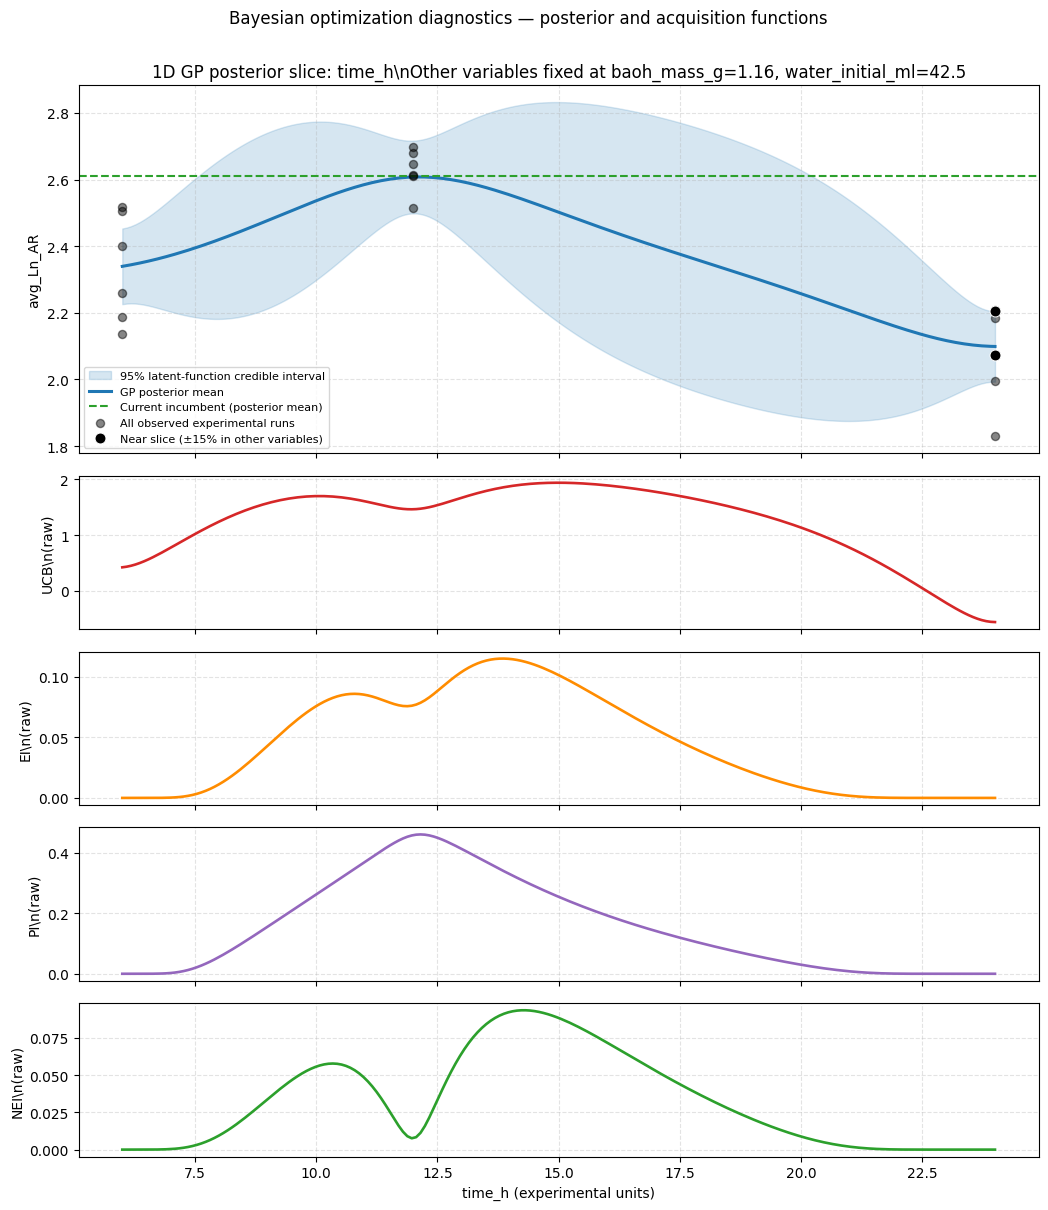

Generating slice plots along variable: baoh_mass_g...


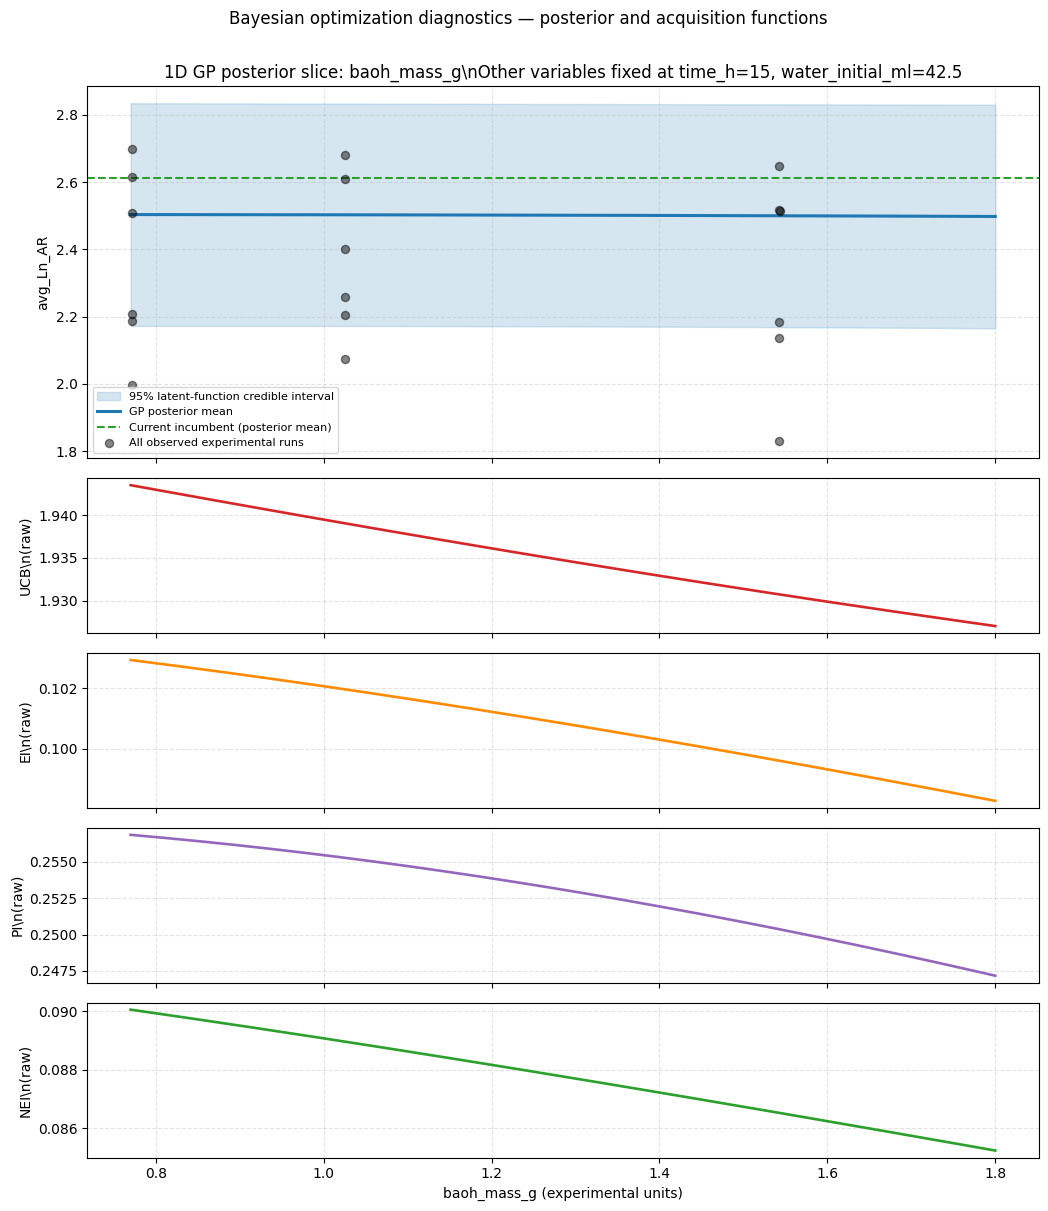

Generating slice plots along variable: water_initial_ml...


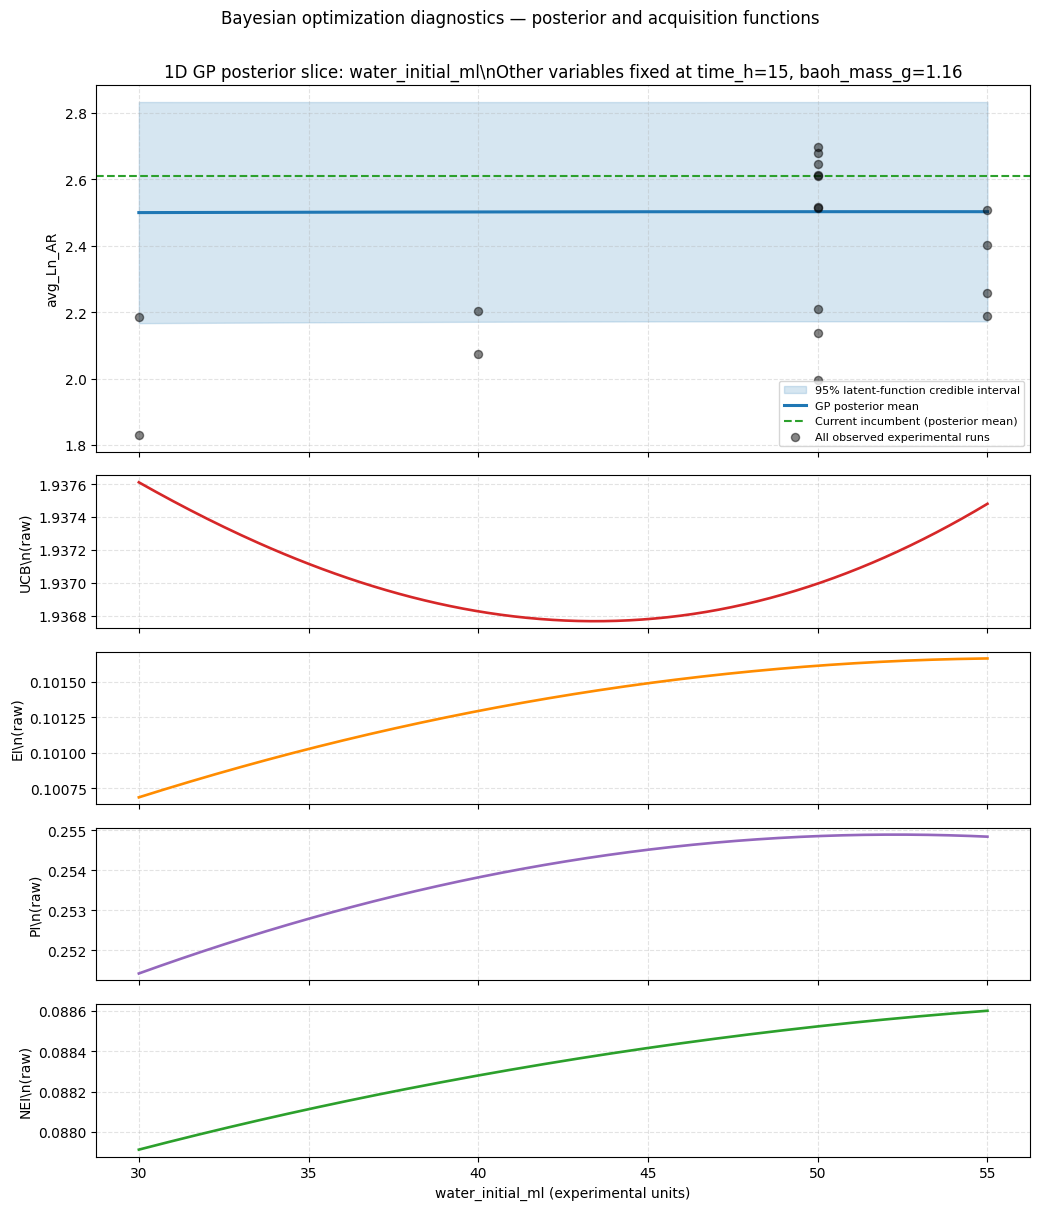

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_parameter_slice_diagnostics(ctx, variable_to_vary, fixed_values, grid_resolution=200,
                                     nearby_tolerance=0.15):
    """
    1D posterior slice with observed experimental runs and raw acquisition values.

    The GP posterior is latent f in standardized target units. Convert its mean,
    SD and incumbent back to avg_Ln_AR before plotting against measured data.
    Acquisition functions are evaluated in the standardized model space and
    shown on separate axes because UCB, EI, PI and NEI have different units/scales.
    """
    var_idx = OPT_VARS.index(variable_to_vary)
    v_min, v_max = BOUNDS[variable_to_vary]
    v_grid = np.linspace(v_min, v_max, grid_resolution)

    raw_grid = np.zeros((grid_resolution, len(OPT_VARS)))
    for idx, var_name in enumerate(OPT_VARS):
        raw_grid[:, idx] = v_grid if var_name == variable_to_vary else fixed_values[var_name]

    X_slice = to_model(raw_grid, bo_est.use_hto)
    mu_std, var_std = ctx.predict(X_slice)
    sd_std = np.sqrt(var_std)

    # Convert latent posterior from standardized units to the original avg_Ln_AR scale.
    mu = mu_std * ctx.y_sd + ctx.y_mean
    sd = sd_std * ctx.y_sd
    incumbent = ctx.best_f * ctx.y_sd + ctx.y_mean

    # Keep acquisition values in their native standardized units.
    acq_scores = {
        "UCB": acq_ucb(mu_std, sd_std, ctx.best_f),
        "EI": acq_ei(mu_std, sd_std, ctx.best_f),
        "PI": acq_pi(mu_std, sd_std, ctx.best_f),
    }
    temp_ctx = BOContext(
        ctx.H, ctx.X_tr, ctx.y_tr, ctx.b_tr, ctx.feas_tr, groups_arr,
        X_slice, X_slice[:, :N_OPT], ctx.y_mean, ctx.y_sd, acq_name="NEI"
    )
    acq_scores["NEI"] = score_pool(temp_ctx)

    # All current observations are shown as black circles. Points satisfying the
    # slice-neighbourhood criterion are overplotted larger to identify the most
    # locally relevant observations. Other coordinates are not identical to
    # the slice, so the scatter is contextual rather than a conditional fit.
    near_mask = np.ones(len(df), dtype=bool)
    for name in OPT_VARS:
        if name != variable_to_vary:
            p_range = BOUNDS[name][1] - BOUNDS[name][0]
            near_mask &= (df[name] - fixed_values[name]).abs() <= nearby_tolerance * p_range

    fig, axes = plt.subplots(
        5, 1, figsize=(10.5, 12), sharex=True,
        gridspec_kw={"height_ratios": [2.4, 1, 1, 1, 1]}
    )
    ax_gp = axes[0]
    ax_gp.fill_between(
        v_grid, mu - 1.96 * sd, mu + 1.96 * sd,
        alpha=0.18, color="tab:blue", label="95% latent-function credible interval"
    )
    ax_gp.plot(v_grid, mu, color="tab:blue", lw=2.2, label="GP posterior mean")
    ax_gp.axhline(incumbent, color="tab:green", ls="--", lw=1.5,
                  label="Current incumbent (posterior mean)")

    ax_gp.scatter(
        df[variable_to_vary], df[TARGET], s=34, marker="o",
        facecolors="black", edgecolors="black", alpha=0.48, zorder=4,
        label="All observed experimental runs"
    )
    if near_mask.any():
        ax_gp.scatter(
            df.loc[near_mask, variable_to_vary], df.loc[near_mask, TARGET],
            s=62, marker="o", facecolors="black", edgecolors="white",
            linewidths=0.7, alpha=1.0, zorder=5,
            label=f"Near slice (±{nearby_tolerance:.0%} in other variables)"
        )

    fixed_text = ", ".join(
        f"{k}={v:g}" for k, v in fixed_values.items() if k != variable_to_vary
    )
    ax_gp.set_title(
        f"1D GP posterior slice: {variable_to_vary}\\n"
        f"Other variables fixed at {fixed_text}"
    )
    ax_gp.set_ylabel("avg_Ln_AR")
    ax_gp.legend(loc="best", fontsize=8)
    ax_gp.grid(True, ls="--", alpha=0.35)

    acq_colors = {"UCB": "tab:red", "EI": "darkorange", "PI": "tab:purple", "NEI": "tab:green"}
    for ax, name in zip(axes[1:], ["UCB", "EI", "PI", "NEI"]):
        ax.plot(v_grid, acq_scores[name], color=acq_colors[name], lw=1.9)
        ax.set_ylabel(f"{name}\\n(raw)")
        ax.grid(True, ls="--", alpha=0.35)
        ax.margins(x=0)

    axes[-1].set_xlabel(f"{variable_to_vary} (experimental units)")
    fig.suptitle(
        "Bayesian optimization diagnostics — posterior and acquisition functions",
        y=1.005, fontsize=12
    )
    plt.tight_layout()
    plt.show()

# Midpoint slice settings (edit these values to inspect a different slice).
midpoints = {
    "time_h": 15.0,
    "baoh_mass_g": 1.16,
    "water_initial_ml": 42.5
}

for var in OPT_VARS:
    print(f"Generating slice plots along variable: {var}...")
    plot_parameter_slice_diagnostics(ctx, var, midpoints)

#Print the kernel that the GP is using in these slices
print()

## Step 6 (Prong 1): acquisition ranking + minimum-distance selection

Score every candidate, then walk down the ranked list and accept a candidate only if it is at least `D_MIN` (normalized distance) from every accepted one. Cheap and robust, but *geometric*: it does not know how the outcomes of nearby experiments are correlated.


In [ ]:
def min_distance_batch(scores, U, q, d_min, fill_remaining=False):
    """Greedy: by decreasing score, keep a candidate only if >= d_min from all kept ones.
    fill_remaining=True tops the batch up with the best-scoring unused candidates if the distance rule cannot yield q."""
    chosen = []
    for j in np.argsort(-scores):
        if all(np.linalg.norm(U[j] - U[k]) >= d_min for k in chosen):
            chosen.append(j)
            if len(chosen) == q: break
    if len(chosen) < q:
        if fill_remaining:
            chosen += [j for j in np.argsort(-scores) if j not in chosen][:q - len(chosen)]
        else:
            print(f"WARNING: only {len(chosen)} candidates satisfy D_MIN={d_min}; lower D_MIN or widen the bounds.")
    return np.array(chosen)

batch_p1 = min_distance_batch(score_pool(ctx), ctx.U_pool, Q, D_MIN)
print(f"Prong 1 ({ACQ_NAME} + min distance {D_MIN}) picked pool rows: {batch_p1}")

Prong 1 (NEI + min distance 0.25) picked pool rows: [21526 21551 21533]


## Step 7 (Prong 2): sequential selection with fantasy observations

Pick the best candidate, **pretend** we know its outcome, add that fantasy to a *temporary copy* of the data, update the GP (same hyperparameters), recompute the acquisition, pick the next. Fantasy values:
* **Kriging believer (KB):** the GP's own prediction. **Constant liar, mean:** the average observed value. **Constant liar, low:** the lowest observed value (strongest push away from the chosen point).

Fantasies live only inside the function; real data are never modified.


In [ ]:
def sequential_batch(ctx, strategy, q):
    """strategy in {'KB','CL_mean','CL_low'}; returns pool rows in selection order."""
    n_real = len(ctx.X_tr)
    X_aug, y_aug, b_aug = ctx.X_tr.copy(), ctx.y_tr.copy(), ctx.b_tr.copy()      # TEMPORARY copies
    chosen = []
    for _ in range(q):
        mu, _ = ctx.predict(ctx.X_pool, X_aug, y_aug, b_aug)
        score = score_pool(ctx, X_aug, y_aug, b_aug)
        score[chosen] = -np.inf
        j = int(np.argmax(score)); chosen.append(j)
        lie = {"KB": mu[j], "CL_mean": ctx.y_tr.mean(), "CL_low": ctx.y_tr.min()}[strategy]
        X_aug = np.vstack([X_aug, ctx.X_pool[j]]); y_aug = np.append(y_aug, lie)
        b_aug = np.append(b_aug, b_aug.max() + 1)                                # the fantasy gets its own oven run
    assert len(ctx.X_tr) == n_real
    return np.array(chosen)

batch_kb, batch_clm, batch_cll = (sequential_batch(ctx, s, Q) for s in ("KB", "CL_mean", "CL_low"))
print("Kriging believer :", batch_kb, "\nConstant liar mean:", batch_clm, "\nConstant liar low :", batch_cll)

Kriging believer : [21526 21551 13472] 
Constant liar mean: [21526 10793 21525] 
Constant liar low : [21526 10819 18821]


## Step 8 (Prong 3): joint batch BO with q-EI and q-NEI

Evaluate the **whole batch as one object** with the GP's joint posterior (so correlations between candidates count):
1. Draw many joint samples of $f$ at [tested recipes ; batch]. 2. In each sample the batch result is the **best** of its q members. 3. Improvement = `max(0, batch best − incumbent)`. 4. Average over samples = q-EI.

**q-NEI** draws the incumbent inside each sample too (best sampled $f$ among accepted tested recipes) instead of one fixed number. Plain q-EI uses the largest raw measurement, which contains the lucky oven offset. The batch is built by **sequential greedy** maximization over a shortlist (top-EI + random candidates), reusing the same random numbers for every evaluation.


In [ ]:
def joint_samples(ctx, X_extra, n_samples, seed):
    """Joint posterior samples of f at [tested recipes ; X_extra]: shape (n_rec + len(X_extra), S)."""
    Xj = np.vstack([ctx.X_rec, X_extra])
    mu, cov = ctx.predict(Xj, full_cov=True)
    return mu[:, None] + safe_cholesky(cov) @ np.random.default_rng(seed).standard_normal((len(Xj), n_samples))

def incumbent_samples(ctx, F, noisy):
    n = len(ctx.X_rec)
    return F[:n][ctx.feas_rec].max(axis=0) if noisy else np.full(F.shape[1], ctx.y_obs_max)

def greedy_joint_batch(ctx, q, noisy, n_samples=N_MC_OPT, seed=SEED):
    n = len(ctx.X_pool); r = np.random.default_rng(seed)
    ei = acq_ei(ctx.mu_pool, ctx.sd_pool, ctx.best_f)
    top = np.argsort(-ei)[:min(SHORT_TOP, n)]
    rest = np.setdiff1d(np.arange(n), top)
    rnd = r.choice(rest, size=min(SHORT_RAND, len(rest)), replace=False) if len(rest) else np.array([], dtype=int)
    short = np.concatenate([top, rnd]).astype(int)                       # shortlist
    F = joint_samples(ctx, ctx.X_pool[short], n_samples, seed)           # ONE set of samples (common random numbers)
    inc = incumbent_samples(ctx, F, noisy)
    Fc = F[len(ctx.X_rec):]
    best_in_batch = np.full(n_samples, -np.inf); chosen = []
    for _ in range(q):
        cur = np.maximum(best_in_batch[None, :], Fc)                     # batch best if candidate m is added
        gain = np.maximum(cur - inc[None, :], 0).mean(axis=1)            # Monte-Carlo (q)EI of "batch so far + m"
        gain[chosen] = -np.inf
        m = int(np.argmax(gain)); chosen.append(m); best_in_batch = cur[m]
    return short[np.array(chosen)]

batch_qei, batch_qnei = greedy_joint_batch(ctx, Q, noisy=False), greedy_joint_batch(ctx, Q, noisy=True)
print("q-EI  (fixed incumbent):", batch_qei, "\nq-NEI (noisy incumbent):", batch_qnei)

q-EI  (fixed incumbent): [24522 11468 24178] 
q-NEI (noisy incumbent): [21551 11468 27194]


## Step 9 (optional benchmark): maximum-entropy batch selection

Ignore the objective; choose the batch with the largest joint predictive entropy $H(X_B)=\tfrac12\log\big((2\pi e)^q\det K_B\big)$. A GP's variance depends only on *where* we measured, so the greedy maximizer is: pick the largest-variance point, add it as a dummy observation, recompute, repeat. Expect points pushed to the edges of the box: an information-seeking benchmark, not a way to find a high AR.


In [ ]:
def max_entropy_batch(ctx, q):
    X_aug, y_aug, b_aug = ctx.X_tr.copy(), ctx.y_tr.copy(), ctx.b_tr.copy(); chosen = []
    for _ in range(q):
        _, var = ctx.predict(ctx.X_pool, X_aug, y_aug, b_aug)             # variance does not depend on the dummy y below
        var[chosen] = -np.inf
        j = int(np.argmax(var)); chosen.append(j)
        X_aug = np.vstack([X_aug, ctx.X_pool[j]]); y_aug = np.append(y_aug, 0.0); b_aug = np.append(b_aug, b_aug.max() + 1)
    return np.array(chosen)

batch_ent = max_entropy_batch(ctx, Q)
print("Max-entropy:", batch_ent)

Max-entropy: [35020 37775 26959]


## Step 10: Compare the proposed batches (real data, CV-selected GP)

Every batch is scored with the **same yardsticks**: `qNEI`/`qEI` (expected improvement of the whole batch, independent Monte-Carlo samples), `logdet` (joint entropy), `min_dist`/`mean_dist` (spread), `fill` (mean distance from random recipes to the nearest tested-or-proposed recipe; lower = better coverage), `mean_mu`/`mean_sd` (exploitation vs exploration). **Purity is not predicted**: a high predicted AR only makes a candidate worth testing.


In [ ]:
BATCHES = {f"P1 {ctx.acq_name}+min-dist": batch_p1, "P2 Kriging believer": batch_kb, "P2 Constant liar (mean)": batch_clm,
           "P2 Constant liar (low)": batch_cll, "P3 q-EI": batch_qei, "P3 q-NEI": batch_qnei, "Entropy (max-entropy)": batch_ent}

def mc_q_improvement(ctx, idx, noisy, n_samples=N_MC_EVAL, seed=12345):
    """Independent Monte-Carlo estimate of qEI/qNEI of batch pool[idx], in log-AR units."""
    F = joint_samples(ctx, ctx.X_pool[idx], n_samples, seed)
    return np.maximum(F[len(ctx.X_rec):].max(axis=0) - incumbent_samples(ctx, F, noisy), 0).mean() * ctx.y_sd

def batch_logdet(ctx, idx):
    _, cov = ctx.predict(ctx.X_pool[idx], full_cov=True)
    return 0.5 * (len(idx) * np.log(2 * np.pi * np.e) + np.linalg.slogdet(cov + ctx.H["sn2"] * np.eye(len(idx)))[1])

probe = RNG.random((4000, N_OPT))
def fill_distance(idx): return cdist(probe, np.vstack([U_obs, ctx.U_pool[idx]])).min(axis=1).mean()

rows = []
for name, idx in BATCHES.items():
    dd = [np.linalg.norm(ctx.U_pool[a] - ctx.U_pool[b]) for a, b in combinations(idx, 2)]
    # back-transformed aspect ratio in original units
    pred_ar = np.exp(ctx.mu_pool[idx] * Y_SD + Y_MEAN).mean()
    # predicted log aspect ratio
    pred_ln_ar = (ctx.mu_pool[idx] * Y_SD + Y_MEAN).mean()

    # Note: Phase purity is an acceptance threshold (not modeled by the GP). We default to the target experimental acceptance
    # status since candidates in the clean pool are generated under valid synthesis conditions.
    expected_purity_pct = PURITY_MIN

    rows.append({"strategy": name, "qNEI": mc_q_improvement(ctx, idx, True), "qEI": mc_q_improvement(ctx, idx, False),
                 "logdet": batch_logdet(ctx, idx), "min_dist": min(dd), "mean_dist": np.mean(dd), "fill": fill_distance(idx),
                 "pred_AR": pred_ar, "pred_lnAR": pred_ln_ar, "expected_phase_purity_pct": expected_purity_pct, "mean_sd": (ctx.sd_pool[idx] * Y_SD).mean()})
summary = pd.DataFrame(rows).set_index("strategy")
print(f"Reference: fill distance of the existing data alone = {cdist(probe, U_obs).min(axis=1).mean():.3f}\n")
display(summary.round(3))

Reference: fill distance of the existing data alone = 0.387



,qNEI,qEI,logdet,min_dist,mean_dist,fill,pred_AR,pred_lnAR,expected_phase_purity_pct,mean_sd
strategy,,,,,,,,,,
P1 NEI+min-dist,0.031,0.014,3.089,0.280,0.667,0.349,12.858,2.554,95.0,0.137
P2 Kriging believer,0.045,0.019,3.130,0.167,0.727,0.353,12.985,2.564,95.0,0.122
P2 Constant liar (mean),0.045,0.018,3.150,1.014,1.151,0.357,12.924,2.559,95.0,0.118
P2 Constant liar (low),0.042,0.017,3.098,0.997,1.147,0.357,12.980,2.563,95.0,0.108
P3 q-EI,0.044,0.019,3.334,0.785,0.978,0.320,12.530,2.528,95.0,0.143
P3 q-NEI,0.046,0.020,3.426,0.339,0.793,0.354,12.367,2.514,95.0,0.148
Entropy (max-entropy),0.023,0.010,3.731,0.222,1.020,0.369,10.561,2.354,95.0,0.194


**Reading the table.** P1 is exploitative; its diversity depends on the hand-set `D_MIN`. KB/CL-mean behave alike; CL-low spreads more. q-NEI should win `qNEI` by construction, so the question is *by how much*. Max-entropy should win `logdet`/`fill` and lose `mean_mu`. `qEI` is ~0 everywhere because its incumbent is the lucky raw maximum. A batch with several different times needs several oven runs (Step 11).


### Integrity check of the single-point NEI shortcut

**What.** Compares the fast closed-form NEI used for ranking the whole pool with a brute-force Monte Carlo q-NEI of a one-point batch, for four pool rows.

**Why.** Every later step relies on the shortcut being correct. If the two numbers agree within Monte Carlo noise, the pool scores can be trusted. The cell temporarily sets `XI = 0` because the brute-force estimator has no margin, and restores it afterwards.

In [ ]:
# Integrity check of the single-point NEI shortcut: it must agree with brute-force Monte Carlo q-NEI of a one-point batch.
_xi, XI = XI, 0.0                                        # the brute-force estimator has no margin XI, so switch it off here
_chk = nei_pool(ctx, n_samples=8192)
for j in np.argsort(-_chk)[[0, 10, 1000, 20000]]:
    print(f"pool row {j:>6}: NEI shortcut = {_chk[j] * Y_SD:.4f}   brute-force Monte Carlo = {mc_q_improvement(ctx, np.array([j]), True, n_samples=200000):.4f}  (AR units)  -> should agree within Monte Carlo error (a few %)")
XI = _xi

pool row  21526: NEI shortcut = 0.0249   brute-force Monte Carlo = 0.0247  (AR units)  -> should agree within Monte Carlo error (a few %)
pool row  21530: NEI shortcut = 0.0248   brute-force Monte Carlo = 0.0247  (AR units)  -> should agree within Monte Carlo error (a few %)
pool row  22486: NEI shortcut = 0.0241   brute-force Monte Carlo = 0.0240  (AR units)  -> should agree within Monte Carlo error (a few %)
pool row   8244: NEI shortcut = 0.0098   brute-force Monte Carlo = 0.0097  (AR units)  -> should agree within Monte Carlo error (a few %)


### Visualizing batch selection and the shared pick matrix

**What.** Lists every pick of every strategy (predicted AR, uncertainty, single-point EI), counts how many identical recipes each pair of strategies shares (the pick matrix), then plots all proposed batches against the existing experiments in three 2D projections, followed by an interactive 3D view.

**Why.** The comparison table above says how good each batch is; these views show *where* the batches sit and how much they overlap. Two strategies that pick the same recipes are not independent evidence, and batches crowded in one corner leave the rest of the design space unexplored.

,strategy,pick,time_h,baoh_mass_g,water_initial_ml,pred_geomean_AR,sd_log_AR,EI_single_log_AR,pool_row
0,P1 NEI+min-dist,1,14.0,0.77,30.0,12.832,0.138,0.030,21526
1,P1 NEI+min-dist,2,14.0,0.77,55.0,12.880,0.135,0.030,21551
2,P1 NEI+min-dist,3,14.0,0.77,37.0,12.861,0.137,0.030,21533
3,P2 Kriging believer,1,14.0,0.77,30.0,12.832,0.138,0.030,21526
4,P2 Kriging believer,2,14.0,0.77,55.0,12.880,0.135,0.030,21551
5,P2 Kriging believer,3,11.0,0.77,30.0,13.242,0.093,0.024,13472
6,P2 Constant liar (mean),1,14.0,0.77,30.0,12.832,0.138,0.030,21526
7,P2 Constant liar (mean),2,10.0,0.77,55.0,12.661,0.121,0.020,10793
8,P2 Constant liar (mean),3,13.0,1.80,55.0,13.278,0.093,0.025,21525
9,P2 Constant liar (low),1,14.0,0.77,30.0,12.832,0.138,0.030,21526



Number of identical recipes shared between batches:


,P1 NEI+min-dist,P2 Kriging believer,P2 Constant liar (mean),P2 Constant liar (low),P3 q-EI,P3 q-NEI,Entropy (max-entropy)
P1 NEI+min-dist,3,2,1,1,0,1,0
P2 Kriging believer,2,3,1,1,0,1,0
P2 Constant liar (mean),1,1,3,1,0,0,0
P2 Constant liar (low),1,1,1,3,0,0,0
P3 q-EI,0,0,0,0,3,1,0
P3 q-NEI,1,1,0,0,1,3,0
Entropy (max-entropy),0,0,0,0,0,0,3


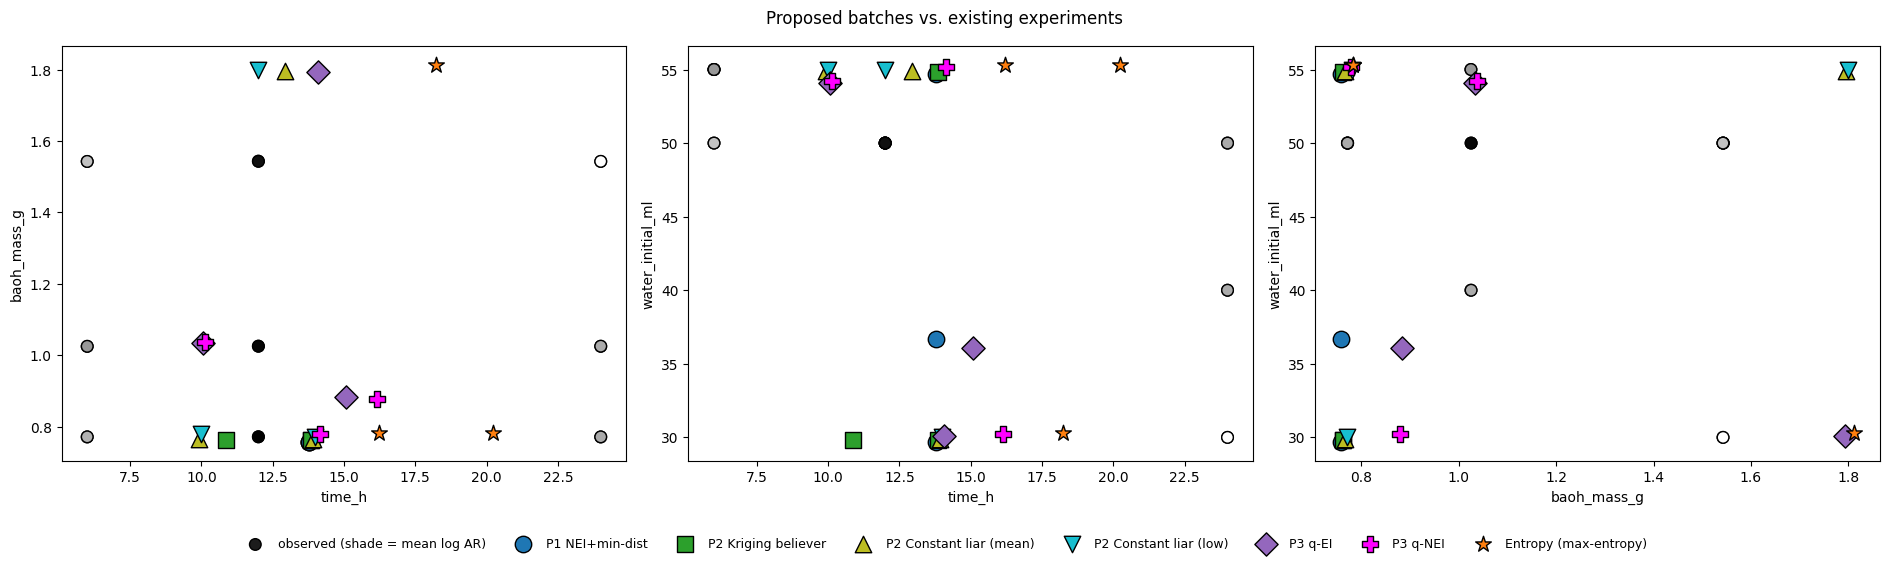

In [ ]:
recs = []
for name, idx in BATCHES.items():
    for rank, j in enumerate(idx, 1):
        recs.append({"strategy": name, "pick": rank, **{v: pool_raw[j, i] for i, v in enumerate(OPT_VARS)},
                     "pred_geomean_AR": np.exp(ctx.mu_pool[j] * Y_SD + Y_MEAN), "sd_log_AR": ctx.sd_pool[j] * Y_SD,
                     "EI_single_log_AR": acq_ei(ctx.mu_pool[j:j+1], ctx.sd_pool[j:j+1], ctx.best_f)[0] * Y_SD, "pool_row": j})
proposals = pd.DataFrame(recs); display(proposals.round(3))
names = list(BATCHES)
overlap = pd.DataFrame([[len(set(BATCHES[a]) & set(BATCHES[b])) for b in names] for a in names], index=names, columns=names)
print("\nNumber of identical recipes shared between batches:"); display(overlap)

styles = {names[0]: ("tab:blue", "o"), names[1]: ("tab:green", "s"), names[2]: ("tab:olive", "^"), names[3]: ("tab:cyan", "v"),
          names[4]: ("tab:purple", "D"), names[5]: ("magenta", "P"), names[6]: ("tab:orange", "*")}
fig, axs = plt.subplots(1, 3, figsize=(19, 5.6))
for ax, (a, b) in zip(axs, [(0, 1), (0, 2), (1, 2)]):
    ax.scatter(df[OPT_VARS[a]], df[OPT_VARS[b]], c=df[TARGET], cmap="Greys", edgecolor="k", s=70, label="observed (shade = mean log AR)", zorder=2)
    for k, (name, idx) in enumerate(BATCHES.items()):
        col, mk = styles[name]; jit = (k - 3) * 0.004 * (HI[a] - LO[a]), (k - 3) * 0.004 * (HI[b] - LO[b])
        ax.scatter(pool_raw[idx, a] + jit[0], pool_raw[idx, b] + jit[1], color=col, marker=mk, s=140, edgecolor="k", label=name, zorder=3)
    ax.set_xlabel(OPT_VARS[a]); ax.set_ylabel(OPT_VARS[b])
h_, l_ = axs[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=len(l_), fontsize=9, frameon=False)
fig.suptitle("Proposed batches vs. existing experiments"); plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

In [ ]:
import plotly.graph_objects as go
import numpy as np
import pandas as pd

# --- 1. Extract already observed experimental runs ---
# These are the 18 runs from Round 1 with known outcomes (mean log aspect ratio; displayed as geometric-mean AR)
obs_x = df['time_h'].values
obs_y = df['baoh_mass_g'].values
obs_z = df['water_initial_ml'].values
obs_ar = np.exp(df[TARGET].values)

# --- 2. Extract proposed batches for each optimization strategy ---
# We map the strategy names to their selected points in pool_raw
strategy_data = {}
for name, idx in BATCHES.items():
    strategy_data[name] = {
        'time_h': pool_raw[idx, 0],
        'baoh_mass_g': pool_raw[idx, 1],
        'water_initial_ml': pool_raw[idx, 2],
        'pred_AR': np.exp(ctx.mu_pool[idx] * Y_SD + Y_MEAN)
    }

# --- 3. Define styles to match the 2D counterparts ---
# Dynamic key mapping to avoid KeyErrors when ACQ_NAME changes (e.g. from EI to UCB)
p1_key = [k for k in BATCHES if "+min-dist" in k][0] if any("+min-dist" in k for k in BATCHES) else 'P1 EI+min-dist'

plotly_styles = {
    p1_key:                      {'color': '#1f77b4',   'symbol': 'circle'},
    'P2 Kriging believer':       {'color': '#2ca02c',  'symbol': 'square'},
    'P2 Constant liar (mean)':   {'color': '#bcbd22',  'symbol': 'diamond'},
    'P2 Constant liar (low)':    {'color': '#17becf',   'symbol': 'circle-open'},
    'P3 q-EI':                   {'color': '#9467bd', 'symbol': 'diamond-open'},
    'P3 q-NEI':                  {'color': 'magenta',    'symbol': 'cross'},
    'Entropy (max-entropy)':     {'color': '#ff7f0e', 'symbol': 'x'}
}

# Create the base interactive figure
fig = go.Figure()

# --- 4. Add the observed points as Trace 0 ---
fig.add_trace(go.Scatter3d(
    x=obs_x,
    y=obs_y,
    z=obs_z,
    mode='markers',
    marker=dict(
        size=8,
        color=obs_ar,
        colorscale='Viridis',
        colorbar=dict(
            title='Observed geometric-mean AR',
            x=1.15
        ),
        opacity=0.8,
        line=dict(color='black', width=4)
    ),
    name='Observed runs (selected SEM dataset)',
    hovertemplate='<b>Observed Run</b><br>Time: %{x}h<br>Ba(OH)2: %{y}g<br>Water: %{z}mL<br>AR: %{marker.color:.2f}<extra></extra>'
))

# --- 5. Add one trace for each of the optimization techniques ---
for name, data in strategy_data.items():
    style = plotly_styles.get(name, {'color': 'gray', 'symbol': 'circle'})
    fig.add_trace(go.Scatter3d(
        x=data['time_h'],
        y=data['baoh_mass_g'],
        z=data['water_initial_ml'],
        mode='markers',
        marker=dict(
            size=10,
            color=style['color'],
            symbol=style['symbol'],
            opacity=0.9,
            line=dict(color='black', width=3)
        ),
        name=name,
        visible=True,
        hovertemplate=f'<b>{name} Proposal</b><br>Time: %{{x}}h<br>Ba(OH)2: %{{y}}g<br>Water: %{{z}}mL<br>Pred AR: %{{text:.2f}}<extra></extra>',
        text=data['pred_AR']
    ))

# --- 6. Build dropdown menus for interactive filtering ---
buttons = []

# Option A: View all batches simultaneously
buttons.append(dict(
    method='restyle',
    label='Show All Strategies',
    args=[{'visible': [True] * (len(BATCHES) + 1)}]
))

# Options B-H: Display only one single strategy alongside the baseline observations
for idx, name in enumerate(BATCHES.keys(), start=1):
    visibility = [False] * (len(BATCHES) + 1)
    visibility[0] = True
    visibility[idx] = True

    buttons.append(dict(
        method='restyle',
        label=f'Only {name}',
        args=[{'visible': visibility}]
    ))

# --- 7. Configure layout and finalize dimensions ---
fig.update_layout(
    title=dict(
        text='<b>BaTiO₃ Nanoneedles: Interactive 3D Batch Selection Space</b>',
        x=0.05,
        y=0.98
    ),
    scene=dict(
        xaxis_title='Time (h)',
        yaxis_title='Ba(OH)₂ Mass (g)',
        zaxis_title='Initial Water (mL)',
        camera=dict(
            eye=dict(x=1.5, y=1.5, z=1.2)
        )
    ),
    margin=dict(t=150, b=40, l=40, r=40),
    width=1000,
    height=750,
    updatemenus=[
        dict(
            buttons=buttons,
            direction='down',
            pad={'r': 10, 't': 10},
            showactive=True,
            x=0.5,
            xanchor='center',
            y=1.01,
            yanchor='top'
        )
    ],
    legend=dict(
        orientation='h',
        yanchor='bottom',
        y=1.08,
        xanchor='center',
        x=0.5
    )
)

fig.show()

### Space-filling analysis: where are the biggest empty regions?

**What.** Finds the largest empty ball in the normalized design space (the point farthest from every tested run), both globally, in the interior, and inside a chosen sub-box. If a proposed batch is available (`mixed_batch_pool_idx`), it also shows how much the batch would shrink the empty regions. The plots show three 2D projections.

**Why.** Acquisition functions rank candidates by expected improvement, which says nothing about whether the tested region covers the design space evenly. This analysis shows the geometry of the gaps, independently of the GP. `mixed_batch_pool_idx` is optional and not created in this notebook, so without it only the observed design is analysed.

=== BOUNDS vs OBSERVED DATA ===


,Bound min,Bound max,Observed min,Observed max,Slack below (frac of range),Slack above (frac of range),Obs outside bounds?
Variable,,,,,,,
Time_h,6.00,24.0,6.000,24.000,0.000,0.000,False
BaOH2_mass_g,0.77,1.8,0.771,1.543,0.001,0.249,False
Water_mL,30.00,55.0,30.000,55.000,0.000,0.000,False


Note: a large 'slack' (e.g. > 0.2) means the domain extends well beyond your data.
      If that upper/lower limit is not physically feasible, tighten BOUNDS.

=== LARGEST EMPTY BALL ANALYSIS (OBSERVED DESIGN) ===
Reference scale: max possible distance in the unit cube = 1.732
Median nearest-observed distance (typical spacing): 0.3692

--- GLOBAL hole (usually a corner/edge) ---
Radius (fill distance):  0.8667
Center:                  Time=6.00 h, Ba(OH)2=0.7700 g, Water=30.00 mL
Nearest observed run:    Time=12.00 h, Ba(OH)2=0.7716 g, Water=50.00 mL
Inside sub-box?          False

--- INTERIOR hole (margin = 10% from every face) ---
Radius:                  0.7485
Center:                  Time=8.75 h, Ba(OH)2=1.2418 g, Water=32.62 mL
Inside sub-box?          False

--- Hole INSIDE the sub-box ---
Radius:                  0.5900
Center:                  Time=15.08 h, Ba(OH)2=1.3134 g, Water=35.77 mL
Radius / global radius:  0.681
Radius / median dist:    1.598   (> 1 means the box is s

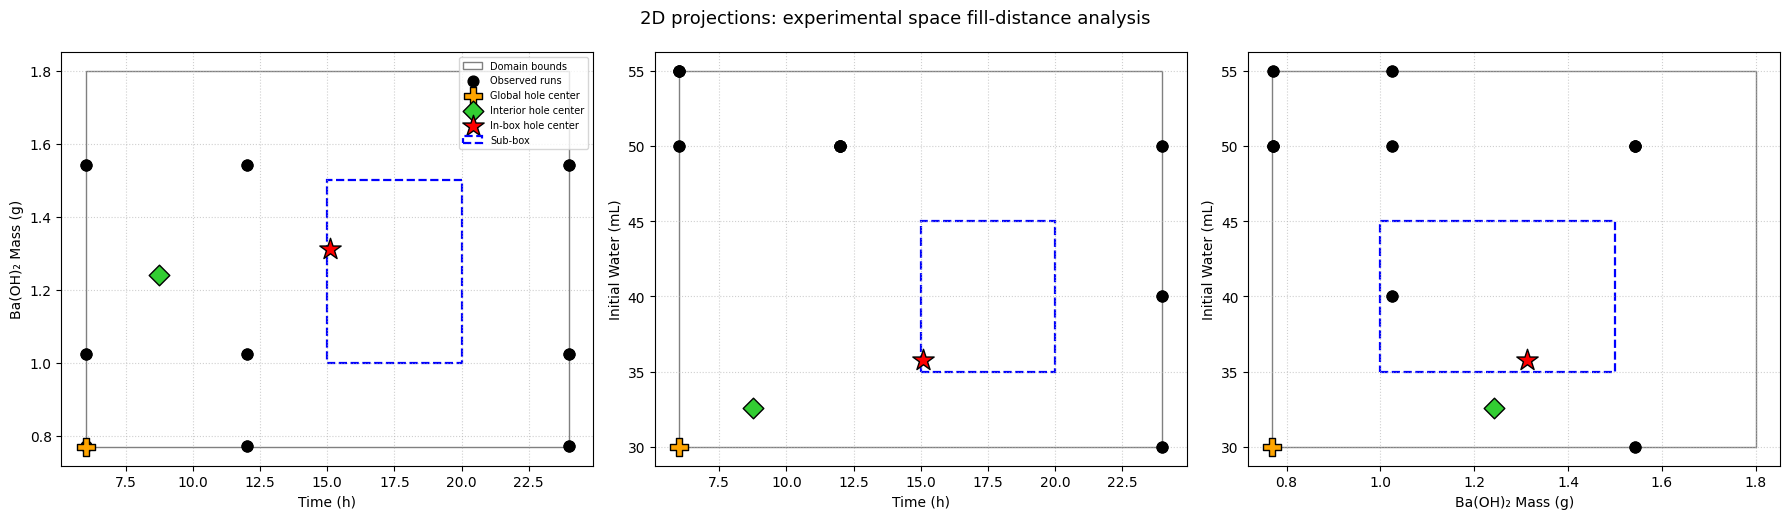

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from scipy.spatial import cKDTree
from scipy.stats import qmc

# ===========================================================================
# 0. INPUTS (uses the existing notebook variables: BOUNDS, df, pool_raw,
#    mixed_batch_pool_idx)
# ===========================================================================
VAR_KEYS   = ["Time_h", "BaOH2_mass_g", "Water_mL"]
VAR_LABELS = ["Time (h)", "Ba(OH)₂ Mass (g)", "Initial Water (mL)"]

# Full domain in ORIGINAL units
bounds = {
    "Time_h":       BOUNDS["time_h"],
    "BaOH2_mass_g": BOUNDS["baoh_mass_g"],
    "Water_mL":     BOUNDS["water_initial_ml"],
}

# Sub-box to test, in ORIGINAL units
box = {
    "Time_h":       (15.0, 20.0),
    "BaOH2_mass_g": (1.0, 1.5),
    "Water_mL":     (35.0, 45.0),
}

INTERIOR_MARGIN = 0.10   # interior = points at least 10% away from every face of the unit cube
N_SOBOL_POWER   = 16     # 2**16 candidate points
SEED            = 42

# Observed runs, columns ordered [time, Ba(OH)2 mass, initial water]
X_obs_raw = df[["time_h", "baoh_mass_g", "water_initial_ml"]].values.astype(float)

# Proposed batch (optional). pool_raw columns MUST be ordered [time, Ba(OH)2, water]
if "mixed_batch_pool_idx" in globals():
    X_prop_raw = np.atleast_2d(np.asarray(pool_raw[mixed_batch_pool_idx], dtype=float))
else:
    X_prop_raw = None

def show(obj):
    """display() in Colab/Jupyter, print() otherwise."""
    try:
        display(obj)
    except NameError:
        print(obj)

# ===========================================================================
# 1. NORMALIZATION (all distances are computed in the [0, 1]^3 unit cube so
#    that the three variables are weighted equally)
# ===========================================================================
lo_bounds = np.array([bounds[k][0] for k in VAR_KEYS], dtype=float)
hi_bounds = np.array([bounds[k][1] for k in VAR_KEYS], dtype=float)

def to_unit(X_raw):
    """Original units -> [0, 1] unit cube."""
    return (np.asarray(X_raw, dtype=float) - lo_bounds) / (hi_bounds - lo_bounds)

def from_unit(X_unit):
    """[0, 1] unit cube -> original units."""
    return lo_bounds + np.asarray(X_unit, dtype=float) * (hi_bounds - lo_bounds)

box_lo = np.array([box[k][0] for k in VAR_KEYS], dtype=float)
box_hi = np.array([box[k][1] for k in VAR_KEYS], dtype=float)

# ===========================================================================
# 1b. SANITY CHECK: are the BOUNDS consistent with the observed data?
#     Large slack means the domain extends far beyond what has been sampled,
#     which creates "holes" at the edges (and distorts every normalized distance).
# ===========================================================================
rows = []
for j, k in enumerate(VAR_KEYS):
    rng = hi_bounds[j] - lo_bounds[j]
    rows.append({
        "Variable": k,
        "Bound min": lo_bounds[j],
        "Bound max": hi_bounds[j],
        "Observed min": X_obs_raw[:, j].min(),
        "Observed max": X_obs_raw[:, j].max(),
        "Slack below (frac of range)": (X_obs_raw[:, j].min() - lo_bounds[j]) / rng,
        "Slack above (frac of range)": (hi_bounds[j] - X_obs_raw[:, j].max()) / rng,
        "Obs outside bounds?": bool((X_obs_raw[:, j].min() < lo_bounds[j]) or
                                    (X_obs_raw[:, j].max() > hi_bounds[j])),
    })
print("=== BOUNDS vs OBSERVED DATA ===")
show(pd.DataFrame(rows).set_index("Variable").round(3))
print("Note: a large 'slack' (e.g. > 0.2) means the domain extends well beyond the data.\n"
      "      If that upper/lower limit is not physically feasible, tighten BOUNDS.\n")

# ===========================================================================
# 2. CANDIDATE GRID: scrambled Sobol points + the 8 cube corners
# ===========================================================================
sobol_gen = qmc.Sobol(d=3, scramble=True, seed=SEED)
candidates_unit = sobol_gen.random(2 ** N_SOBOL_POWER)

corners = np.array([[i, j, k] for i in (0, 1) for j in (0, 1) for k in (0, 1)], dtype=float)
candidates_unit = np.vstack([candidates_unit, corners])

# ===========================================================================
# 3-6. REUSABLE LARGEST-EMPTY-BALL FUNCTION
#   Returns, for the given observed design:
#     - global hole      (often at a corner/edge: maximin holes are boundary-seeking)
#     - interior hole    (candidates at least `margin` away from every face)
#     - in-box hole      (candidates inside the sub-box, if box_raw is given)
#     - greedy top-N distinct holes
# ===========================================================================
def largest_empty_ball(X_obs_unit, candidates_unit, box_raw=None,
                       margin=0.10, n_top=5, suppress_frac=0.5):
    tree = cKDTree(X_obs_unit)
    distances, indices = tree.query(candidates_unit, k=1)   # nearest observed run per candidate
    cand_raw = from_unit(candidates_unit)

    if box_raw is not None:
        b_lo = np.array([box_raw[k][0] for k in VAR_KEYS], dtype=float)
        b_hi = np.array([box_raw[k][1] for k in VAR_KEYS], dtype=float)
        in_box_all = np.all((cand_raw >= b_lo) & (cand_raw <= b_hi), axis=1)
    else:
        in_box_all = None

    def best_in_mask(mask):
        """Largest empty ball whose center is restricted to `mask`."""
        if not np.any(mask):
            return None
        pool = np.where(mask)[0]
        best = pool[np.argmax(distances[pool])]
        out = {
            "radius": float(distances[best]),
            "center_raw": cand_raw[best],
            "center_unit": candidates_unit[best],
            "nearest_obs_raw": from_unit(X_obs_unit[indices[best]]),
        }
        if in_box_all is not None:
            out["in_box"] = bool(in_box_all[best])
        return out

    res = {"distances": distances, "indices": indices,
           "median_dist": float(np.median(distances))}

    # 3a. Global hole
    res["global"] = best_in_mask(np.ones(len(candidates_unit), dtype=bool))

    # 3b. Interior hole (excludes the boundary-seeking corner/edge holes)
    interior_mask = np.all((candidates_unit >= margin) & (candidates_unit <= 1 - margin), axis=1)
    res["interior"] = best_in_mask(interior_mask)

    # 3c. Hole inside the sub-box
    if box_raw is not None:
        res["box"] = best_in_mask(in_box_all)
        if res["box"] is not None:
            res["box"]["ratio_to_global"] = res["box"]["radius"] / res["global"]["radius"]
            res["box"]["ratio_to_median"] = res["box"]["radius"] / res["median_dist"]
        res["box_median_dist"] = (float(np.median(distances[in_box_all]))
                                  if np.any(in_box_all) else np.nan)

    # 3d. Greedy top-N distinct holes
    top, active = [], np.ones(len(candidates_unit), dtype=bool)
    for _ in range(n_top):
        pool = np.where(active)[0]
        if len(pool) == 0:
            break
        best = pool[np.argmax(distances[pool])]
        item = {"radius": float(distances[best]), "center_raw": cand_raw[best]}
        if in_box_all is not None:
            item["in_box"] = bool(in_box_all[best])
        top.append(item)
        d_sel = np.linalg.norm(candidates_unit - candidates_unit[best], axis=1)
        active &= d_sel >= suppress_frac * distances[best]   # drop neighbours of the chosen hole
    res["top"] = top
    return res

def fmt_center(c):
    return f"Time={c[0]:.2f} h, Ba(OH)2={c[1]:.4f} g, Water={c[2]:.2f} mL"

def touches_box_face(center_raw, tol=0.05):
    """Variables for which the center lies within `tol` (fraction of box width) of a box face."""
    width = box_hi - box_lo
    near = ((center_raw - box_lo) / width < tol) | ((box_hi - center_raw) / width < tol)
    return [VAR_KEYS[j] for j in range(3) if near[j]]

# ===========================================================================
# 4. RUN ON THE OBSERVED DESIGN
# ===========================================================================
X_obs_unit = to_unit(X_obs_raw)
res_obs = largest_empty_ball(X_obs_unit, candidates_unit, box_raw=box, margin=INTERIOR_MARGIN)

g, it, bx = res_obs["global"], res_obs["interior"], res_obs["box"]

print("=== LARGEST EMPTY BALL ANALYSIS (OBSERVED DESIGN) ===")
print(f"Reference scale: max possible distance in the unit cube = {np.sqrt(3):.3f}")
print(f"Median nearest-observed distance (typical spacing): {res_obs['median_dist']:.4f}\n")

print("--- GLOBAL hole (usually a corner/edge) ---")
print(f"Radius (fill distance):  {g['radius']:.4f}")
print(f"Center:                  {fmt_center(g['center_raw'])}")
print(f"Nearest observed run:    {fmt_center(g['nearest_obs_raw'])}")
print(f"Inside sub-box?          {g['in_box']}\n")

print(f"--- INTERIOR hole (margin = {INTERIOR_MARGIN:.0%} from every face) ---")
print(f"Radius:                  {it['radius']:.4f}")
print(f"Center:                  {fmt_center(it['center_raw'])}")
print(f"Inside sub-box?          {it['in_box']}\n")

print("--- Hole INSIDE the sub-box ---")
if bx is not None:
    print(f"Radius:                  {bx['radius']:.4f}")
    print(f"Center:                  {fmt_center(bx['center_raw'])}")
    print(f"Radius / global radius:  {bx['ratio_to_global']:.3f}")
    print(f"Radius / median dist:    {bx['ratio_to_median']:.3f}   (> 1 means the box is sparser than typical)")
    print(f"Median nearest dist in box: {res_obs['box_median_dist']:.4f}")
    faces = touches_box_face(bx["center_raw"])
    if faces:
        print(f"WARNING: the in-box center lies on a box face for: {faces}. "
              f"The hole extends beyond the box, so the box limits are partly arbitrary.")
else:
    print("No candidates fall inside the sub-box.")

print("\n--- Top 5 greedy distinct holes ---")
for n, t in enumerate(res_obs["top"], start=1):
    print(f"{n}. Radius={t['radius']:.4f} | {fmt_center(t['center_raw'])} | Inside box: {t['in_box']}")

# ===========================================================================
# 5. PROPOSED-BATCH DIAGNOSTICS + DESIGN COMPARISON
# ===========================================================================
res_comb = None
if X_prop_raw is not None:
    # 5a. Where do the proposed points sit?
    prop_unit = to_unit(X_prop_raw)
    in_box_prop = np.all((X_prop_raw >= box_lo) & (X_prop_raw <= box_hi), axis=1)
    on_boundary = []
    for u in prop_unit:
        names = [VAR_KEYS[j] for j in range(3) if (u[j] <= 0.01) or (u[j] >= 0.99)]
        on_boundary.append(", ".join(names) if names else "-")
    df_prop = pd.DataFrame(X_prop_raw, columns=VAR_KEYS)
    df_prop["In sub-box"] = in_box_prop
    df_prop["On domain boundary in"] = on_boundary
    df_prop["Dist. to nearest observed (unit)"] = cKDTree(X_obs_unit).query(prop_unit, k=1)[0]
    print("\n=== PROPOSED BATCH ===")
    show(df_prop.round(4))
    print("Points on the domain boundary are typical of EI/variance-based acquisition, "
          "but they leave the interior gaps unfilled.")

    # 5b. Observed only vs observed + proposed
    X_comb_unit = np.vstack([X_obs_unit, prop_unit])
    res_comb = largest_empty_ball(X_comb_unit, candidates_unit, box_raw=box, margin=INTERIOR_MARGIN)

    def summarize(name, r):
        return {
            "Design": name,
            "Fill distance (global)": r["global"]["radius"],
            "Interior fill distance": r["interior"]["radius"],
            "Median nearest dist": r["median_dist"],
            "Box max radius": r["box"]["radius"] if r["box"] is not None else np.nan,
        }

    df_cmp = pd.DataFrame([summarize("Observed only", res_obs),
                           summarize("Observed + proposed batch", res_comb)]).set_index("Design")
    print("\n=== DESIGN COMPARISON ===")
    show(df_cmp.round(4))
    pct = (1 - df_cmp.iloc[1] / df_cmp.iloc[0]) * 100
    print("Reduction from adding the batch (%):")
    print(pct.round(1).to_string())

# ===========================================================================
# 6. PLOTS: 2D projections in ORIGINAL units
#    red star   = hole inside the sub-box
#    orange +   = GLOBAL hole (corner/edge)
#    green diamond = INTERIOR hole
# ===========================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
proj_indices = [(0, 1), (0, 2), (1, 2)]

for p, (ax, (a, b)) in enumerate(zip(axes, proj_indices)):
    # Domain (bounds) as a light-grey rectangle so corners/edges are visible
    ax.add_patch(patches.Rectangle((lo_bounds[a], lo_bounds[b]),
                                   hi_bounds[a] - lo_bounds[a], hi_bounds[b] - lo_bounds[b],
                                   linewidth=1.0, edgecolor="grey", facecolor="none",
                                   linestyle="-", label="Domain bounds"))

    ax.scatter(X_obs_raw[:, a], X_obs_raw[:, b], color="black", s=60, zorder=3, label="Observed runs")

    if X_prop_raw is not None:
        ax.scatter(X_prop_raw[:, a], X_prop_raw[:, b], color="magenta", marker="x",
                   s=90, linewidths=2, zorder=4, label="Proposed batch")

    ax.scatter(g["center_raw"][a], g["center_raw"][b], color="orange", marker="P",
               s=170, edgecolor="k", zorder=5, label="Global hole center")
    ax.scatter(it["center_raw"][a], it["center_raw"][b], color="limegreen", marker="D",
               s=110, edgecolor="k", zorder=5, label="Interior hole center")
    if bx is not None:
        ax.scatter(bx["center_raw"][a], bx["center_raw"][b], color="red", marker="*",
                   s=260, edgecolor="k", zorder=6, label="In-box hole center")

    # Sub-box
    ax.add_patch(patches.Rectangle((box_lo[a], box_lo[b]), box_hi[a] - box_lo[a], box_hi[b] - box_lo[b],
                                   linewidth=1.6, edgecolor="blue", facecolor="none",
                                   linestyle="--", label="Sub-box"))

    padx = 0.05 * (hi_bounds[a] - lo_bounds[a])
    pady = 0.05 * (hi_bounds[b] - lo_bounds[b])
    ax.set_xlim(lo_bounds[a] - padx, hi_bounds[a] + padx)
    ax.set_ylim(lo_bounds[b] - pady, hi_bounds[b] + pady)
    ax.set_xlabel(VAR_LABELS[a])
    ax.set_ylabel(VAR_LABELS[b])
    ax.grid(True, linestyle=":", alpha=0.6)
    if p == 0:
        ax.legend(loc="best", fontsize=7)

plt.suptitle("2D projections: experimental space fill-distance analysis", fontsize=13, y=0.99)
plt.tight_layout()
plt.show()

## Step 10b (new): Compare acquisition functions and batch strategies on the shared folds (replay)

**The idea.** Pretend to be at an earlier moment of the project. For each fold of the shared scaffold:
1. **Fit** the surrogate on the **training recipes only** (the structure chosen by CV for that kernel family, hyperparameters refitted on the training runs).
2. **Candidate pool = the held-out recipes.** The surrogate has never seen them, but we *do* know their outcome: the mean AR of their two replicates (the two replicates sit in different oven runs, so the oven offset largely averages out).
3. Each strategy **picks** from that pool. We score the pick against the truth.

Two experiments, both on **identical** folds, training sets and pools for every strategy and every kernel:
* **Single pick (q=1): the acquisition functions.** `Greedy mean` (pure exploitation, κ=0), `UCB`, `EI`, `PI`, `NEI`.
* **Batch of `REPLAY_Q`: the batch strategies** (minimum distance, KB, constant liars, q-EI, q-NEI, max-entropy), using the acquisition set in `ACQ_NAME`.

**Metrics (per trial, averaged over trials).**
* **Regret** = (best held-out recipe's AR) − (best AR among the picks). 0 is perfect; lower is better.
* **Hit rate** = how often the truly best held-out recipe is among the picks.
* **Advantage over Random** = expected regret of random picking − the strategy's regret. Positive means better than chance. Random and Oracle are exact (all combinations enumerated).

**What this can and cannot tell us.** Each trial chooses among only 3 recipes. With 30 random partitions × 3 folds there are 90 trials per kernel, but they are built from the *same 9 recipes*, so they are far from independent; the standard errors below are optimistic. Treat the result as a **sanity check and a plumbing test of the comparison framework**, not as proof that one rule is better. Real evidence comes from measured rounds (Step 17).


In [ ]:
def run_strategies(c, q):
    """All batch strategies of Steps 6-9 on a context `c` (real data, or a CV training fold)."""
    return {f"P1 {c.acq_name}+min-dist": min_distance_batch(score_pool(c), c.U_pool, q, D_MIN, fill_remaining=True),
            "P2 Kriging believer": sequential_batch(c, "KB", q), "P2 Constant liar (mean)": sequential_batch(c, "CL_mean", q),
            "P2 Constant liar (low)": sequential_batch(c, "CL_low", q),
            "P3 q-EI": greedy_joint_batch(c, q, False), "P3 q-NEI": greedy_joint_batch(c, q, True),
            "Entropy (max-entropy)": max_entropy_batch(c, q)}

def single_pick(c, acq):
    return int(np.argmax(c.mu_pool)) if acq == "Greedy mean" else int(np.argmax(score_pool(c.with_acq(acq))))

def regret_hit(sel, truth):
    sel = np.atleast_1d(sel).astype(int)
    return truth.max() - truth[sel].max(), float(np.argmax(truth) in sel)

def random_reference(truth, q):
    """Exact expectation of picking q of the pool uniformly at random (all combinations enumerated)."""
    cs = list(combinations(range(len(truth)), q))
    return np.mean([truth.max() - truth[list(c)].max() for c in cs]), np.mean([np.argmax(truth) in c for c in cs])

ACQ_LIST = ["Greedy mean", "UCB", "EI", "PI", "NEI"]
records = []; t0 = time.time()
for kernel_label, fam in GP_FAMILIES.items():
    params = chosen_params[kernel_label]                                        # structure chosen by CV (+ tie rule) for this kernel family
    for rep, part in enumerate(replay_partitions):
        for fold, (tr, te) in enumerate(part):
            est = GPSurrogate(**params, n_restarts=CV_RESTARTS).fit(X_cv.iloc[tr], y_ser.iloc[tr])    # sees TRAINING recipes only
            gte = groups_arr[te]; gids = np.unique(gte)
            Xp = np.array([est.unit_inputs(X_cv.iloc[te][gte == g]).mean(axis=0) for g in gids])       # held-out recipes = candidate pool
            truth = np.array([y_true[te][gte == g].mean() for g in gids])                               # their known outcome (hidden from GP)
            cf = BOContext(est.H_, est.U_, est.ys_, est.b_, df["feasible"].values[tr], groups_arr[tr], Xp, Xp[:, :N_OPT],
                           est.y_mean_, est.y_sd_)
            base = dict(kernel=kernel_label, repeat=rep, fold=fold)
            # --- experiment 1: single pick, acquisition functions ---
            rr, rh = random_reference(truth, 1)
            picks = {a: single_pick(cf, a) for a in ACQ_LIST}
            picks["Random (expected)"] = None; picks["Oracle"] = int(np.argmax(truth))
            for name, p in picks.items():
                reg, hit = (rr, rh) if p is None else regret_hit(p, truth)
                records.append({**base, "mode": "single pick (q=1)", "strategy": name, "regret": reg, "hit": hit, "rand_regret": rr})
            # --- experiment 2: batches of REPLAY_Q ---
            rr, rh = random_reference(truth, REPLAY_Q)
            sels = run_strategies(cf, REPLAY_Q); sels["Random (expected)"] = None; sels["Oracle"] = np.argsort(-truth)[:REPLAY_Q]
            for name, s in sels.items():
                reg, hit = (rr, rh) if s is None else regret_hit(s, truth)
                records.append({**base, "mode": f"batch (q={REPLAY_Q})", "strategy": name, "regret": reg, "hit": hit, "rand_regret": rr})
replay = pd.DataFrame(records)
print(f"Replay finished in {time.time() - t0:.0f}s: {len(replay):,} records, "
      f"{replay.groupby(['kernel', 'mode', 'strategy']).size().iloc[0]} trials per kernel and strategy.")

Replay finished in 65s: 4,320 records, 90 trials per kernel and strategy.



=== single pick (q=1): mean regret (lower = better), hit rate, and advantage over random (mean ± SE) ===


mean regret                           hit rate                      advantage vs random                           
kernel            Matern-3/2 GP Matern-5/2 GP RBF GP Matern-3/2 GP Matern-5/2 GP RBF GP       Matern-3/2 GP Matern-5/2 GP       RBF GP
strategy                                                                                                                              
Oracle                     0.00          0.00   0.00          1.00          1.00   1.00         0.23 ± 0.01   0.23 ± 0.01  0.23 ± 0.01
Greedy mean                0.01          0.00   0.00          0.81          0.84   0.86         0.23 ± 0.01   0.23 ± 0.01  0.23 ± 0.01
PI                         0.01          0.01   0.01          0.81          0.81   0.81         0.23 ± 0.01   0.23 ± 0.01  0.23 ± 0.01
EI                         0.01          0.01   0.01          0.80          0.81   0.81         0.22 ± 0.01   0.23 ± 0.01  0.23 ± 0.01
UCB                        0.01          0.01   0.01          0.84          0.84   0.84         0.22 ± 0.01   0.22 ± 0.01  0.22 ± 0.01
NEI                        0.02          0.03   0.09          0.80          0.77   0.62         0.21 ± 0.01    0.2 ± 0.01  0.14 ± 0.02
Random (expected)          0.23          0.23   0.23          0.33          0.33   0.33           0.0 ± 0.0     0.0 ± 0.0    0.0 ± 0.0


=== batch (q=2): mean regret (lower = better), hit rate, and advantage over random (mean ± SE) ===


mean regret                           hit rate                      advantage vs random                           
kernel                  Matern-3/2 GP Matern-5/2 GP RBF GP Matern-3/2 GP Matern-5/2 GP RBF GP       Matern-3/2 GP Matern-5/2 GP       RBF GP
strategy                                                                                                                                    
Oracle                           0.00          0.00   0.00          1.00          1.00   1.00         0.08 ± 0.01   0.08 ± 0.01  0.08 ± 0.01
P3 q-NEI                         0.00          0.00   0.00          0.99          0.99   0.99         0.08 ± 0.01   0.08 ± 0.01  0.08 ± 0.01
P3 q-EI                          0.00          0.00   0.00          0.99          0.99   0.99         0.08 ± 0.01   0.08 ± 0.01  0.08 ± 0.01
P2 Constant liar (low)           0.00          0.00   0.00          0.93          0.98   0.97         0.08 ± 0.01   0.08 ± 0.01  0.07 ± 0.01
P1 NEI+min-dist                  0.00          0.01   0.01          0.98          0.96   0.96         0.07 ± 0.01   0.07 ± 0.01  0.07 ± 0.01
P2 Kriging believer              0.00          0.01   0.01          0.99          0.96   0.93         0.08 ± 0.01   0.07 ± 0.01  0.07 ± 0.01
P2 Constant liar (mean)          0.00          0.01   0.01          0.98          0.94   0.94         0.07 ± 0.01   0.07 ± 0.01  0.07 ± 0.01
Random (expected)                0.08          0.08   0.08          0.67          0.67   0.67           0.0 ± 0.0     0.0 ± 0.0    0.0 ± 0.0
Entropy (max-entropy)            0.16          0.18   0.18          0.44          0.38   0.41        -0.08 ± 0.02   -0.1 ± 0.01  -0.1 ± 0.01

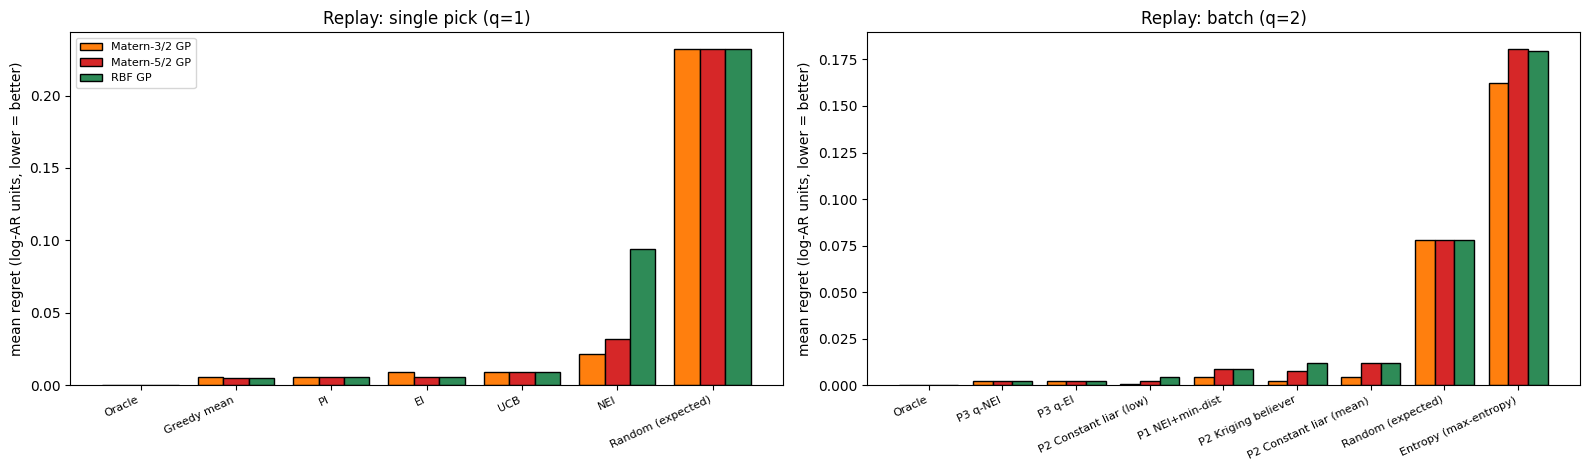

In [ ]:
replay["advantage"] = replay["rand_regret"] - replay["regret"]       # positive = better than random picking

def summarize(mode):
    g = replay[replay["mode"] == mode].groupby(["strategy", "kernel"])
    out = pd.DataFrame({"regret": g["regret"].mean(), "hit_rate": g["hit"].mean(), "adv": g["advantage"].mean(),
                        "adv_se": g["advantage"].std() / np.sqrt(g["advantage"].size())}).reset_index()
    return out

for mode in replay["mode"].unique():
    s = summarize(mode)
    print(f"\n=== {mode}: mean regret (lower = better), hit rate, and advantage over random (mean ± SE) ===")
    reg = s.pivot(index="strategy", columns="kernel", values="regret")
    hit = s.pivot(index="strategy", columns="kernel", values="hit_rate")
    adv = s.pivot(index="strategy", columns="kernel", values="adv"); se = s.pivot(index="strategy", columns="kernel", values="adv_se")
    table = pd.concat({"mean regret": reg.round(2), "hit rate": hit.round(2),
                       "advantage vs random": adv.round(2).astype(str) + " ± " + se.round(2).astype(str)}, axis=1)
    table.index.name = None
    order = reg.mean(axis=1).sort_values().index
    display(table.loc[order])

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
kernel_cols = dict(zip(GP_FAMILIES, ["tab:orange", "tab:red", "seagreen"]))
for ax, mode in zip(axes, replay["mode"].unique()):
    s = summarize(mode); strategies = list(s.groupby("strategy")["regret"].mean().sort_values().index); w = 0.8 / len(GP_FAMILIES)
    for j, k in enumerate(GP_FAMILIES):
        v = s[s.kernel == k].set_index("strategy").loc[strategies, "regret"]
        ax.bar(np.arange(len(strategies)) + (j - 1) * w, v.values, width=w, color=kernel_cols[k], edgecolor="k", label=k)
    ax.set_xticks(range(len(strategies))); ax.set_xticklabels(strategies, fontsize=8, rotation=25, ha="right")
    ax.set_title(f"Replay: {mode}"); ax.set_ylabel("mean regret (log-AR units, lower = better)")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**How to read the replay (and what not to conclude).**
* **Random and Oracle bracket every other row.** A strategy whose advantage over Random is within about ±2 standard errors is **indistinguishable from chance** here. With a surface that is mostly flat and noise comparable to the signal, expect many rows in that zone.
* **Same recipe pool, same folds, same trials for every row**, so the *ordering* is meaningful as a diagnostic, while the *size* of differences is not reliable (dependent trials, only 3 candidates per pick).
* **Built-in bias against exploration.** The candidate pool is made of recipes that were *already run* inside the explored region. Exploration (UCB, NEI, q-NEI, max-entropy, CL-low) pays off when there are **unexplored regions with hidden upside**; a replay on known recipes contains none, so it structurally favours exploitation (greedy mean, EI, PI, Kriging believer). A poor replay score for an exploratory rule is therefore **not evidence that it is a bad rule for proposing new experiments**. In a flat-surface regime NEI scores are also all close to 0 (it refuses to be fooled by a lucky incumbent), so its ranking of the candidates is close to arbitrary.
* **Kernel columns** show whether the choice of kernel changes which acquisition rule looks good. If the columns disagree, the conclusion depends on the surrogate.
* **Single pick vs batch.** Batch strategies differ from single acquisition functions mainly in *diversity*; with a pool of 3 recipes and q=2 there is little room for diversity to matter. They are therefore compared fully in Step 10 (real proposals) and, ultimately, in measured rounds (Step 17).


## Step 10c: Joint q-NEI batch design, seed stability, and oven-run markers

**What.** (a) Re-runs the joint q-NEI batch of Step 8 on the current model, prints it in laboratory units (predicted AR, uncertainty, oven group), and repeats the selection with 10 different Monte Carlo seeds. (b) Redraws the time-coloured slices with one marker shape per oven run and the proposed batch as numbered red stars.

**Why.** Differences in q-NEI between batches are small, so a batch that changes with the seed is only weakly determined. The oven-run markers show whether any pattern in the data is really an oven-run effect. This section needs the batch tools (Steps 5 to 10), which is why it comes after them.

Joint q-NEI batch (q=3), expected improvement of the whole batch = 0.046 log-AR units



,time_h,baoh_mass_g,water_initial_ml,pred_geo_mean_AR,sd_log_AR,oven_group
0,10.0,1.03,54.0,12.648,0.121,2
1,14.0,0.77,55.0,12.880,0.135,1
2,16.0,0.87,30.0,11.572,0.190,3



Stability check: same method, different Monte-Carlo seeds (time_h, baoh_mass_g, water_initial_ml):


,qNEI,picks
seed,,
42,0.046,"[(10.0, 1.03, 54.0), (14.0, 0.77, 55.0), (16.0, 0.87, 30.0)]"
43,0.047,"[(10.0, 0.84, 31.0), (14.0, 0.77, 30.0), (16.0, 1.77, 53.0)]"
44,0.046,"[(10.0, 1.06, 31.0), (14.0, 0.77, 30.0), (16.0, 1.71, 54.0)]"
45,0.045,"[(10.0, 1.08, 30.0), (13.0, 1.79, 30.0), (15.0, 1.03, 30.0)]"
46,0.047,"[(10.0, 0.81, 30.0), (14.0, 0.77, 55.0), (15.0, 1.78, 30.0)]"
47,0.046,"[(10.0, 1.14, 30.0), (14.0, 0.77, 30.0), (15.0, 1.68, 55.0)]"
48,0.046,"[(10.0, 0.87, 34.0), (14.0, 0.77, 55.0), (14.0, 1.77, 32.0)]"
49,0.047,"[(10.0, 0.81, 32.0), (13.0, 1.71, 30.0), (14.0, 0.77, 55.0)]"
50,0.046,"[(10.0, 0.87, 32.0), (14.0, 0.77, 55.0), (16.0, 1.8, 34.0)]"


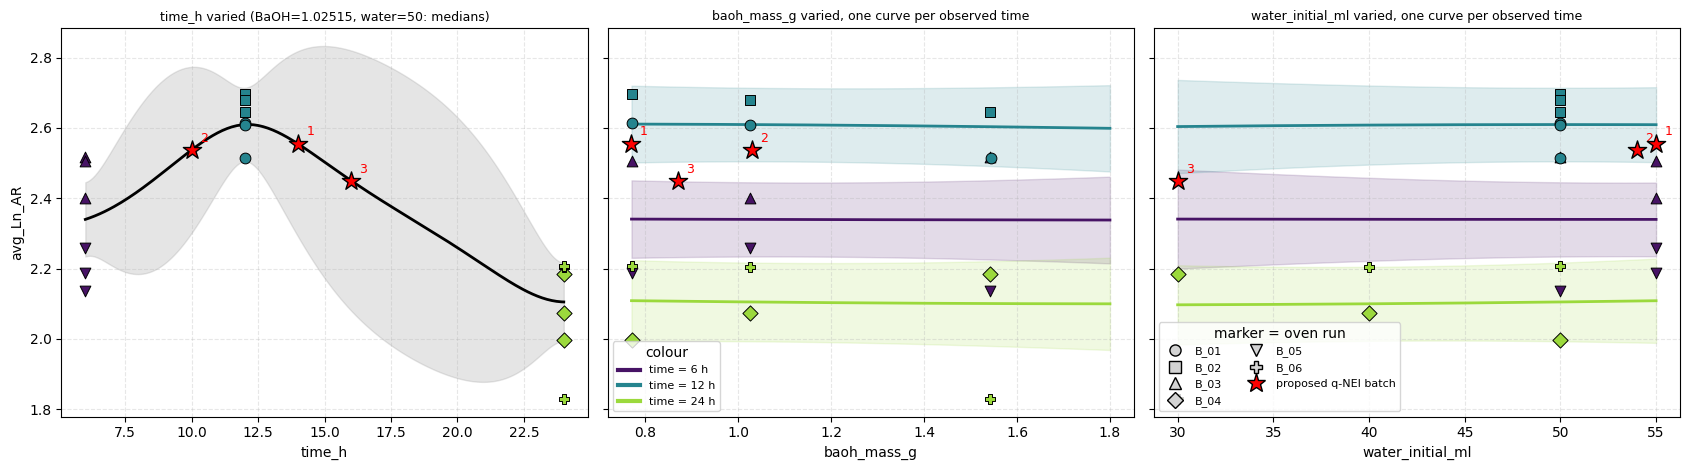

In [ ]:


# ############ Part 1 ############
# ===================== Step 10c (a): joint q-NEI batch (Prong 3) on the current model =====================
# Re-runs the notebook's own greedy joint q-NEI (greedy_joint_batch, noisy=True) and then checks how stable the batch is
# when only the Monte-Carlo seed changes. q-NEI differences between batches are small, so stability matters.
def describe_batch(idx):
    idx = np.asarray(idx)
    t = pd.DataFrame(pool_raw[idx], columns=OPT_VARS)
    t["pred_geo_mean_AR"] = np.exp(ctx.mu_pool[idx] * Y_SD + Y_MEAN)     # back to AR units (geometric mean)
    t["sd_log_AR"] = ctx.sd_pool[idx] * Y_SD                             # latent-f uncertainty, log-AR units
    t["oven_group"] = pd.factorize(t["time_h"])[0] + 1                   # runs with the same time can share an oven run
    return t.sort_values(["time_h", "baoh_mass_g", "water_initial_ml"]).reset_index(drop=True)

batch_qnei_now = greedy_joint_batch(ctx, Q, noisy=True)                  # same call and seed as Step 8
print(f"Joint q-NEI batch (q={Q}), expected improvement of the whole batch = "
      f"{mc_q_improvement(ctx, batch_qnei_now, True):.3f} log-AR units\n")
display(describe_batch(batch_qnei_now).round(3))

print("\nStability check: same method, different Monte-Carlo seeds (time_h, baoh_mass_g, water_initial_ml):")
stab = []
for s in range(10):
    b = greedy_joint_batch(ctx, Q, noisy=True, seed=SEED + s)
    picks = sorted(map(tuple, np.round(pool_raw[b], 2)))
    stab.append({"seed": SEED + s, "qNEI": round(mc_q_improvement(ctx, b, True), 3), "picks": picks})
with pd.option_context("display.max_colwidth", 200): display(pd.DataFrame(stab).set_index("seed"))


# ############ Part 2 ############
# ===================== Step 10c (b): slices with oven-run markers and the proposed q-NEI batch =====================
from matplotlib.lines import Line2D

def predict_raw(est, raw):
    raw = np.atleast_2d(raw).astype(float); n = len(raw)
    A = np.column_stack([raw, np.full((n, 1), df["hto_mass_g"].median()), np.zeros(n)])   # FEATURES + dummy batch_code
    return est.predict(A, return_std=True)

def plot_slices_time_batch(est, proposed_raw=None, grid_n=200):
    """colour = time of the run, marker shape = oven run (batch_id). Red stars = proposed batch, drawn at the GP mean
    of each proposed recipe (its own coordinates), numbered in the order of `proposed_raw`."""
    time_levels = np.sort(df["time_h"].unique()); med = {v: df[v].median() for v in OPT_VARS}
    colors = dict(zip(time_levels, plt.cm.viridis(np.linspace(0.05, 0.85, len(time_levels)))))
    batches = sorted(df["batch_id"].unique())
    shapes = dict(zip(batches, ["o", "s", "^", "D", "v", "P", "X", "h", "<", ">"]))
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
    for ax, var in zip(axes, OPT_VARS):
        grid = np.linspace(*BOUNDS[var], grid_n)
        if var == "time_h":
            raw = np.column_stack([grid if v == "time_h" else np.full(grid_n, med[v]) for v in OPT_VARS])
            mu, sd = predict_raw(est, raw)
            ax.fill_between(grid, mu - 1.96 * sd, mu + 1.96 * sd, color="gray", alpha=0.2); ax.plot(grid, mu, "k", lw=2)
            ax.set_title(f"time_h varied (BaOH={med['baoh_mass_g']:g}, water={med['water_initial_ml']:g}: medians)", fontsize=9)
        else:
            for t in time_levels:
                raw = np.column_stack([grid if v == var else np.full(grid_n, t if v == "time_h" else med[v]) for v in OPT_VARS])
                mu, sd = predict_raw(est, raw)
                ax.fill_between(grid, mu - 1.96 * sd, mu + 1.96 * sd, color=colors[t], alpha=0.15); ax.plot(grid, mu, color=colors[t], lw=2)
            ax.set_title(f"{var} varied, one curve per observed time", fontsize=9)
        for (t, b), g in df.groupby(["time_h", "batch_id"]):
            ax.scatter(g[var], g[TARGET], s=60, color=colors[t], marker=shapes[b], edgecolor="k", lw=0.7, zorder=5)
        if proposed_raw is not None:
            P = np.atleast_2d(proposed_raw); mu_p, _ = predict_raw(est, P); xs = P[:, OPT_VARS.index(var)]
            ax.scatter(xs, mu_p, s=190, marker="*", color="red", edgecolor="k", zorder=6)
            for k, (x_, y_) in enumerate(zip(xs, mu_p), 1): ax.annotate(str(k), (x_, y_), xytext=(6, 6), textcoords="offset points", fontsize=9, color="red")
        ax.set_xlabel(var); ax.grid(True, ls="--", alpha=0.3)
    axes[0].set_ylabel(TARGET)
    h_t = [Line2D([], [], color=colors[t], lw=3, label=f"time = {t:g} h") for t in time_levels]
    h_b = [Line2D([], [], marker=shapes[b], color="w", markerfacecolor="lightgray", markeredgecolor="k", ms=8, label=b) for b in batches]
    h_p = [Line2D([], [], marker="*", color="w", markerfacecolor="red", markeredgecolor="k", ms=14, label="proposed q-NEI batch")] if proposed_raw is not None else []
    axes[1].legend(handles=h_t, fontsize=8, loc="lower left", title="colour"); axes[2].legend(handles=h_b + h_p, fontsize=8, loc="lower left", title="marker = oven run", ncol=2)
    plt.tight_layout(); plt.show()

plot_slices_time_batch(bo_est, proposed_raw=pool_raw[batch_qnei_now])

## Step 10d: Replicate statistics and auxiliary GPs (variance and delta)

**What.** Each recipe has two runs in different oven batches. This section turns the replicates into two recipe-level quantities, the **variance** of the two log-ARs and their **signed difference** (delta), fits one small GP to each, and draws their predicted surfaces next to the mean GP.

**Why.** The mean GP assumes constant noise. These auxiliary GPs ask whether the replicate scatter and the shift between oven runs depend on the recipe (time, Ba(OH)₂, water). The answer decides whether a heteroscedastic mean GP (Step 10f) is worth building. With only 9 recipes and two replicates each, every conclusion here is weak evidence.

#### Recipe-level replicate statistics

**What.** For each recipe: mean log-AR, sample variance of log-AR, delta (second run minus first run), and the oven batches involved. The variance is log-transformed (`log_log_AR_variance`) because variances are positive and heavy-tailed.

**Why.** These tables are the training data of the two auxiliary GPs. With exactly two replicates, `s² = delta²/2`, so the two GPs are two views of the same small dataset, not independent evidence.

In [ ]:
# ---------------------------------------------------------------------------
# Recipe-level replicate statistics on the SAME log-AR scale as the main GP.
# Each recipe has two synthesis runs in different oven batches.
# ---------------------------------------------------------------------------
recipe_rows = []
for recipe_id, group in df.groupby("recipe_id", sort=True):
    group = group.sort_values("run_id")
    y = group[TARGET].astype(float).to_numpy()
    row = {
        "recipe_id": recipe_id,
        "time_h": group["time_h"].iloc[0],
        "baoh_mass_g": group["baoh_mass_g"].mean(),
        "water_initial_ml": group["water_initial_ml"].iloc[0],
        "n_replicates": len(y),
        "mean_log_AR": np.mean(y),
        "log_AR_variance": np.var(y, ddof=1) if len(y) > 1 else np.nan,
        "delta_log_AR_second_minus_first": y[-1] - y[0] if len(y) >= 2 else np.nan,
        "first_batch": group["batch_id"].iloc[0],
        "last_batch": group["batch_id"].iloc[-1],
    }
    recipe_rows.append(row)

recipe_stats = pd.DataFrame(recipe_rows)
VAR_EPS = 1e-8
recipe_stats["log_log_AR_variance"] = np.log(recipe_stats["log_AR_variance"].clip(lower=VAR_EPS))
X_stats = recipe_stats[OPT_VARS]
y_var = recipe_stats["log_log_AR_variance"].to_numpy()
y_delta = recipe_stats["delta_log_AR_second_minus_first"].to_numpy()

print("Recipe-level replicate statistics (all on log-AR scale):")
display(recipe_stats[[
    "recipe_id", "n_replicates", "mean_log_AR", "log_AR_variance",
    "delta_log_AR_second_minus_first", "first_batch", "last_batch"
]].round(4))

print(
    "\\nImportant interpretation: with exactly two replicates, sample variance "
    "and squared replicate delta are algebraically linked (s² = delta² / 2). "
    "The variance GP and delta GP are therefore two views of the same small "
    "replicate dataset, not independent evidence."
)


Recipe-level replicate statistics (all on log-AR scale):


,recipe_id,n_replicates,mean_log_AR,log_AR_variance,delta_log_AR_second_minus_first,first_batch,last_batch
0,1,2,2.6554,0.0035,0.0835,B_01,B_02
1,2,2,2.6447,0.0024,0.0697,B_01,B_02
2,3,2,2.5805,0.0087,0.1315,B_01,B_02
3,4,2,2.3267,0.0730,-0.3821,B_03,B_05
4,5,2,2.3475,0.0508,-0.3187,B_03,B_05
5,6,2,2.3305,0.0102,-0.1431,B_03,B_05
6,7,2,2.0066,0.0631,-0.3551,B_04,B_06
7,8,2,2.1023,0.0224,0.2115,B_04,B_06
8,9,2,2.1397,0.0084,0.1298,B_04,B_06


\nImportant interpretation: with exactly two replicates, sample variance and squared replicate delta are algebraically linked (s² = delta² / 2). The variance GP and delta GP are therefore two views of the same small replicate dataset, not independent evidence.


#### Fitting the two auxiliary GPs

**What.** `gp_var` models the log of the replicate variance and `gp_delta` models the signed delta, both with the same GP code as the mean GP (Matérn-5/2, shared structure, weak prior, no oven offset, no HTO).

**Why.** The same estimator class keeps the comparison consistent. Their predictions are exponentiated later (for the variance) to return to variance units.

In [ ]:
# The variance GP models log(sample variance of log AR); exponentiate predictions
# later to return to variance units. The delta GP models a SIGNED change:
# second run minus first run, so negative values mean the second run was lower.
gp_var = GPSurrogate(family="matern52", batch_effect=False, use_hto=False, prior="weak", n_restarts=FINAL_RESTARTS)
gp_delta = GPSurrogate(family="matern52", batch_effect=False, use_hto=False, prior="weak", n_restarts=FINAL_RESTARTS)
gp_var.fit(X_stats, y_var)
gp_delta.fit(X_stats, y_delta)
print("Auxiliary GPs fitted: log replicate variance and signed replicate delta in log-AR.")


Auxiliary GPs fitted: log replicate variance and signed replicate delta in log-AR.


### Visualización de las Superficies: Media vs Varianza vs Delta de Lote

Proyectaremos las predicciones de los tres modelos en el plano de temperatura y masa de $\text{Ba(OH)}_2$ con un volumen de agua fijo en $50\text{ mL}$ para analizar espacialmente dónde se concentran las mayores desviaciones de lote.


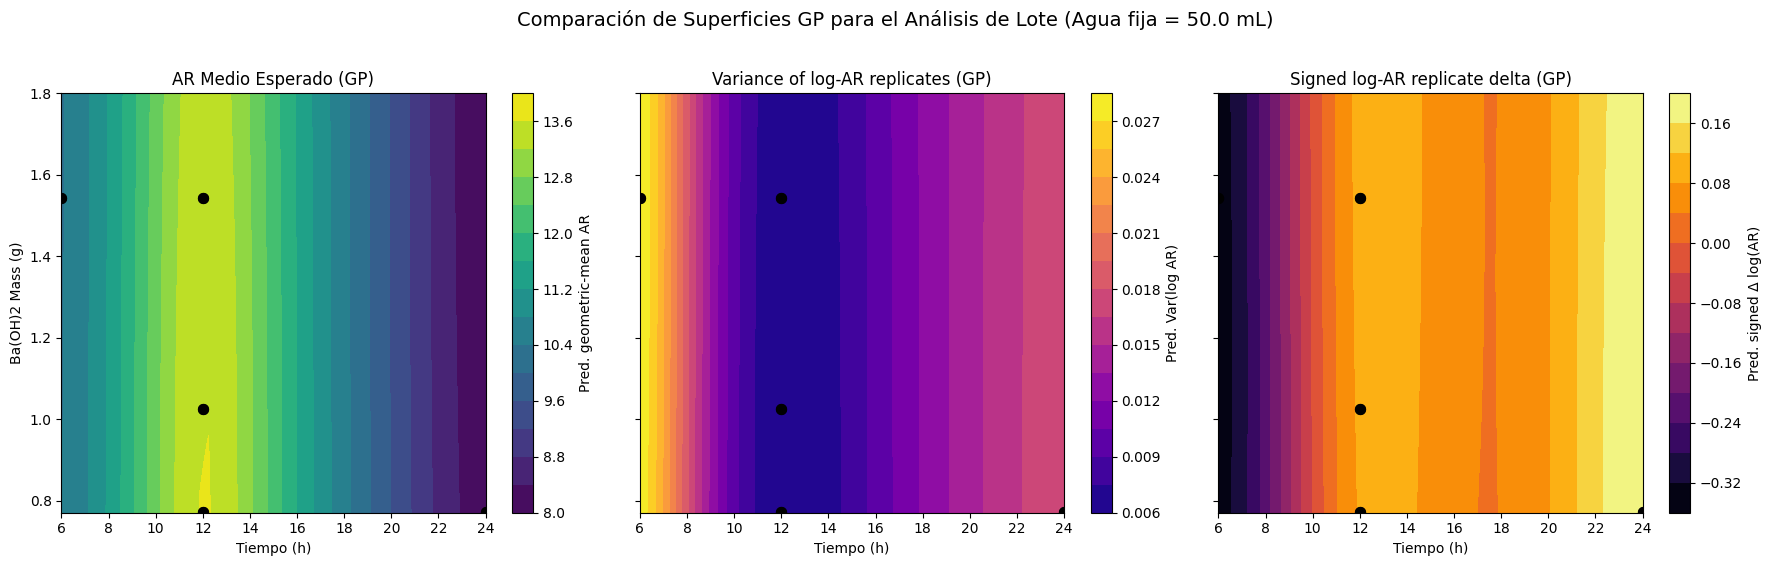

In [ ]:
# Generar malla de predicción
gt, gb = np.linspace(LO[0], HI[0], 50), np.linspace(LO[1], HI[1], 50)
Tm, Bm = np.meshgrid(gt, gb)
# Fijamos el volumen de agua en 50 mL
water_fixed = 50.0
target_grid = np.column_stack([Tm.ravel(), Bm.ravel(), np.full(Tm.size, water_fixed)])

# Predicciones
mu_mean, _ = ctx.predict(to_model(target_grid, bo_est.use_hto))
mu_mean_raw = np.exp(mu_mean * Y_SD + Y_MEAN)

pred_var = np.exp(gp_var.predict(target_grid))
pred_delta = gp_delta.predict(target_grid)

# Graficar
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)

# Panel 1: Media de AR
cs0 = axes[0].contourf(Tm, Bm, mu_mean_raw.reshape(Tm.shape), levels=15, cmap="viridis")
axes[0].set_title("AR Medio Esperado (GP)")
axes[0].set_xlabel("Tiempo (h)")
axes[0].set_ylabel("Ba(OH)2 Mass (g)")
fig.colorbar(cs0, ax=axes[0], label="Pred. geometric-mean AR")

# Panel 2: Varianza del AR
cs1 = axes[1].contourf(Tm, Bm, pred_var.reshape(Tm.shape), levels=15, cmap="plasma")
axes[1].set_title("Variance of log-AR replicates (GP)")
axes[1].set_xlabel("Tiempo (h)")
fig.colorbar(cs1, ax=axes[1], label="Pred. Var(log AR)")

# Panel 3: Signed replicate delta in log-AR (GP)
cs2 = axes[2].contourf(Tm, Bm, pred_delta.reshape(Tm.shape), levels=15, cmap="inferno")
axes[2].set_title("Signed log-AR replicate delta (GP)")
axes[2].set_xlabel("Tiempo (h)")
fig.colorbar(cs2, ax=axes[2], label="Pred. signed Δ log(AR)")

# Marcar puntos observados cercanos a water = 50 mL como círculos negros sólidos
near_50 = (df["water_initial_ml"] - water_fixed).abs() < 2
for ax in axes:
    ax.scatter(df.loc[near_50, "time_h"], df.loc[near_50, "baoh_mass_g"], color="black", s=50, zorder=5)

plt.suptitle(f"Comparación de Superficies GP para el Análisis de Lote (Agua fija = {water_fixed} mL)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### Additional GP Surface Projections: Variance and Delta

To complete the spatial analysis, we project the predicted replica variance and absolute delta surfaces over the remaining parameter pairs:
1. **Time vs. Water Volume** (with Ba(OH)₂ mass fixed at its median value of 1.025 g).
2. **Ba(OH)₂ Mass vs. Water Volume** (with Time fixed at its median value of 12 h).


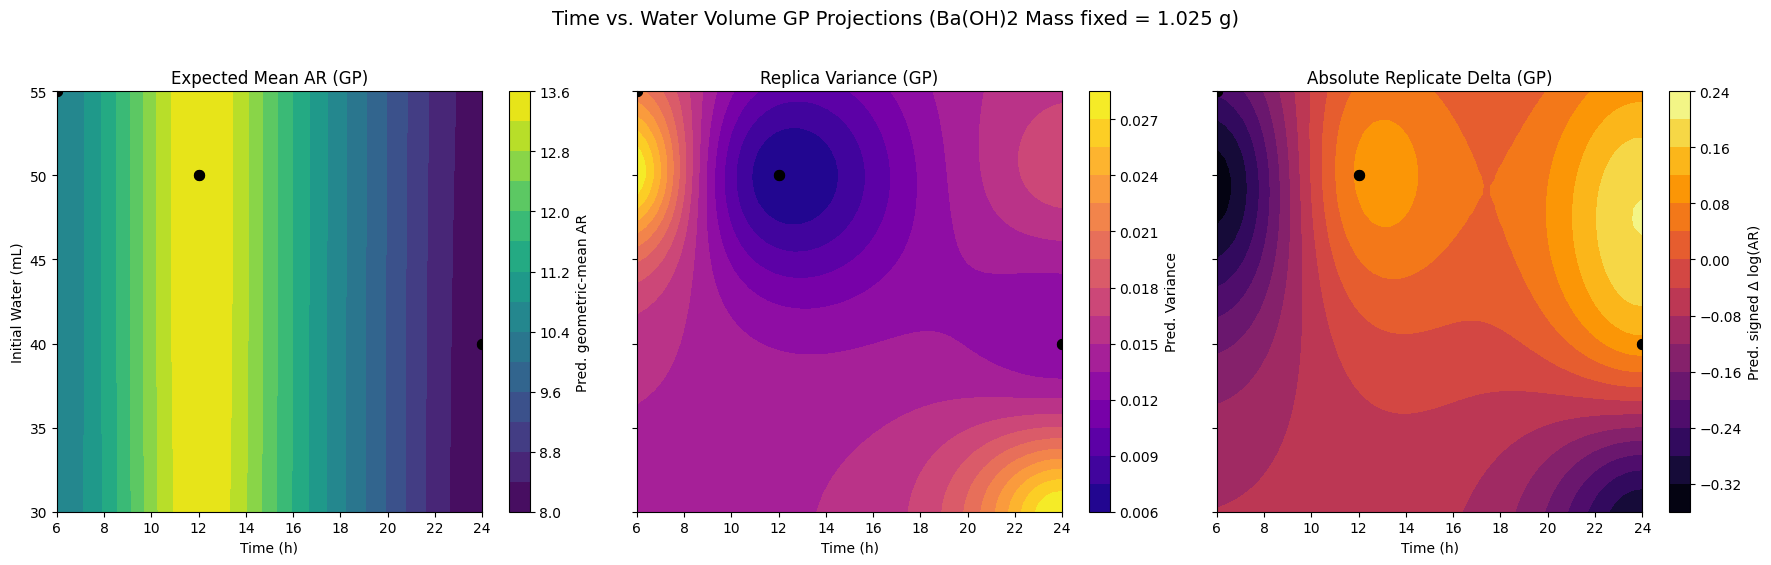

In [ ]:
# 1. Parameter Pair: Time vs. Water Volume (Ba(OH)2 fixed at median)
baoh_fixed = 1.025
gt, gw = np.linspace(LO[0], HI[0], 50), np.linspace(LO[2], HI[2], 50)
Tm, Wm = np.meshgrid(gt, gw)
target_grid_tw = np.column_stack([Tm.ravel(), np.full(Tm.size, baoh_fixed), Wm.ravel()])

mu_mean_tw, _ = ctx.predict(to_model(target_grid_tw, bo_est.use_hto))
mu_mean_tw_raw = np.exp(mu_mean_tw * Y_SD + Y_MEAN)
pred_var_tw = np.exp(gp_var.predict(target_grid_tw))
pred_delta_tw = gp_delta.predict(target_grid_tw)

fig1, axes1 = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)

# Panel 1: Mean AR
cs0 = axes1[0].contourf(Tm, Wm, mu_mean_tw_raw.reshape(Tm.shape), levels=15, cmap="viridis")
axes1[0].set_title("Expected Mean AR (GP)")
axes1[0].set_xlabel("Time (h)")
axes1[0].set_ylabel("Initial Water (mL)")
fig1.colorbar(cs0, ax=axes1[0], label="Pred. geometric-mean AR")

# Panel 2: Replica Variance
cs1 = axes1[1].contourf(Tm, Wm, pred_var_tw.reshape(Tm.shape), levels=15, cmap="plasma")
axes1[1].set_title("Replica Variance (GP)")
axes1[1].set_xlabel("Time (h)")
fig1.colorbar(cs1, ax=axes1[1], label="Pred. Variance")

# Panel 3: Signed log-AR Delta
cs2 = axes1[2].contourf(Tm, Wm, pred_delta_tw.reshape(Tm.shape), levels=15, cmap="inferno")
axes1[2].set_title("Absolute Replicate Delta (GP)")
axes1[2].set_xlabel("Time (h)")
fig1.colorbar(cs2, ax=axes1[2], label="Pred. signed Δ log(AR)")

# Plot observed experimental points close to the fixed Ba(OH)2 mass as black circles
near_baoh = (df["baoh_mass_g"] - baoh_fixed).abs() < 0.15
for ax in axes1:
    ax.scatter(df.loc[near_baoh, "time_h"], df.loc[near_baoh, "water_initial_ml"], color="black", s=50, zorder=5)

plt.suptitle(f"Time vs. Water Volume GP Projections (Ba(OH)2 Mass fixed = {baoh_fixed} g)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

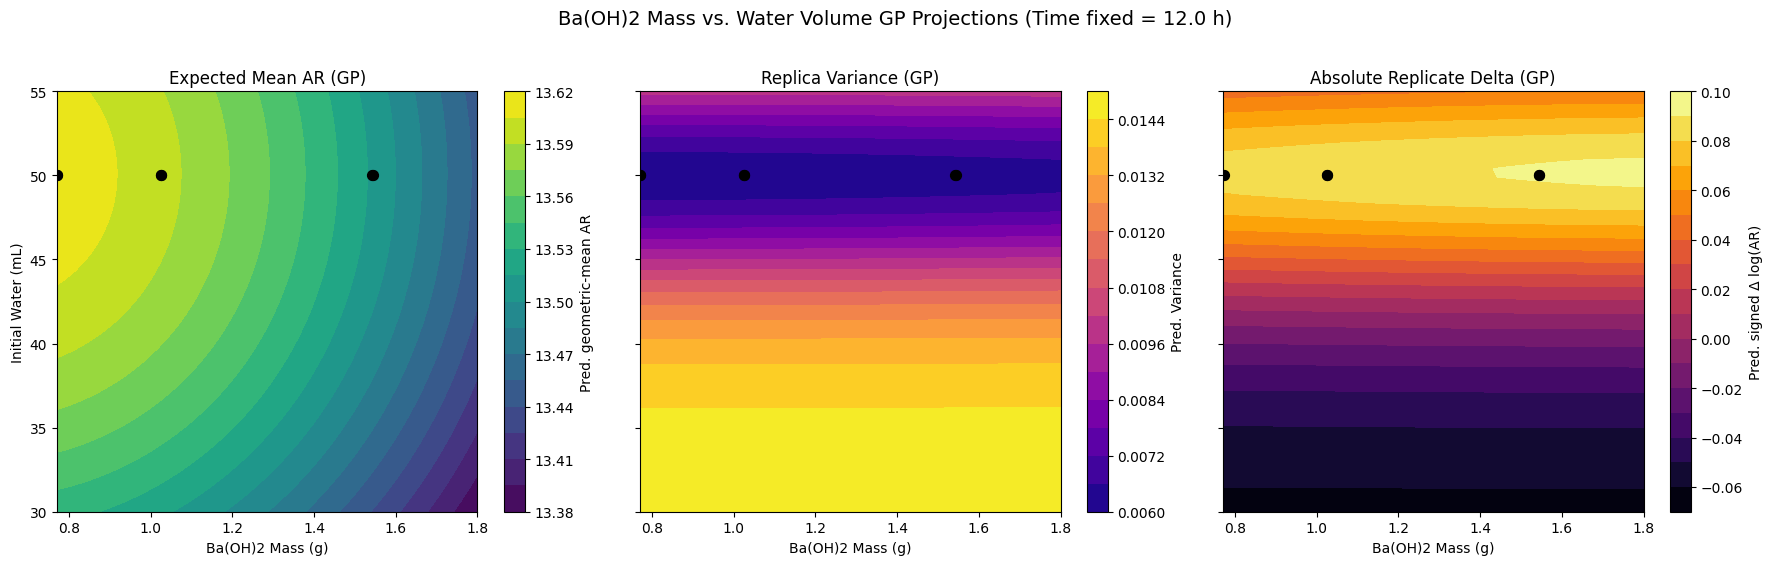

In [ ]:
# 2. Parameter Pair: Ba(OH)2 Mass vs. Water Volume (Time fixed at median)
time_fixed = 12.0
gb, gw = np.linspace(LO[1], HI[1], 50), np.linspace(LO[2], HI[2], 50)
Bm, Wm = np.meshgrid(gb, gw)
target_grid_bw = np.column_stack([np.full(Bm.size, time_fixed), Bm.ravel(), Wm.ravel()])

mu_mean_bw, _ = ctx.predict(to_model(target_grid_bw, bo_est.use_hto))
mu_mean_bw_raw = np.exp(mu_mean_bw * Y_SD + Y_MEAN)
pred_var_bw = np.exp(gp_var.predict(target_grid_bw))
pred_delta_bw = gp_delta.predict(target_grid_bw)

fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)

# Panel 1: Mean AR
cs0 = axes2[0].contourf(Bm, Wm, mu_mean_bw_raw.reshape(Bm.shape), levels=15, cmap="viridis")
axes2[0].set_title("Expected Mean AR (GP)")
axes2[0].set_xlabel("Ba(OH)2 Mass (g)")
axes2[0].set_ylabel("Initial Water (mL)")
fig2.colorbar(cs0, ax=axes2[0], label="Pred. geometric-mean AR")

# Panel 2: Replica Variance
cs1 = axes2[1].contourf(Bm, Wm, pred_var_bw.reshape(Bm.shape), levels=15, cmap="plasma")
axes2[1].set_title("Replica Variance (GP)")
axes2[1].set_xlabel("Ba(OH)2 Mass (g)")
fig2.colorbar(cs1, ax=axes2[1], label="Pred. Variance")

# Panel 3: Signed log-AR Delta
cs2 = axes2[2].contourf(Bm, Wm, pred_delta_bw.reshape(Bm.shape), levels=15, cmap="inferno")
axes2[2].set_title("Absolute Replicate Delta (GP)")
axes2[2].set_xlabel("Ba(OH)2 Mass (g)")
fig2.colorbar(cs2, ax=axes2[2], label="Pred. signed Δ log(AR)")

# Plot observed experimental points close to the fixed Time value as black circles
near_time = (df["time_h"] - time_fixed).abs() < 2.0
for ax in axes2:
    ax.scatter(df.loc[near_time, "baoh_mass_g"], df.loc[near_time, "water_initial_ml"], color="black", s=50, zorder=5)

plt.suptitle(f"Ba(OH)2 Mass vs. Water Volume GP Projections (Time fixed = {time_fixed} h)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## Step 10e: Diagnostics of the fitted GPs (slices, constant-noise tests, lengthscale profiles)

**What.** A set of checks that ask: *are the fitted GPs well fitted, and does the data support any spatial structure at all?* It contains midpoint slices for the variance and delta GPs, time-coloured slices for the mean GP with a lengthscale profile, and the same diagnostics for the variance GP and the delta GP.

**Why.** A 1D slice of a multi-variable model can look like a bad fit simply because the other variables are fixed while the dots span all values. Colouring by time and profiling the lengthscales separates a real misfit from a projection effect and from a weakly identified parameter.

### 1D slices of the variance and delta GPs at the midpoint

**What.** For each of the three variables, plots the variance GP and the delta GP along that variable while the other two are held at the midpoints defined in Step 5b (`midpoints`), together with the observed recipe values.

**Why.** It is the quickest first look at the auxiliary GPs. The next sections replace these midpoint slices with slices that respect the structure of the design.

In [ ]:
def plot_auxiliary_gp_slices(gp_model, model_title, variable_to_vary, fixed_values, grid_resolution=200, is_variance=True):
    var_idx = OPT_VARS.index(variable_to_vary)
    v_min, v_max = BOUNDS[variable_to_vary]
    v_grid = np.linspace(v_min, v_max, grid_resolution)

    raw_grid = np.zeros((grid_resolution, len(OPT_VARS)))
    for idx, var_name in enumerate(OPT_VARS):
        raw_grid[:, idx] = v_grid if var_name == variable_to_vary else fixed_values[var_name]

    # Generate predictions from the chosen auxiliary GP surrogate
    X_slice = pd.DataFrame(raw_grid, columns=OPT_VARS)
    pred_mean, pred_std = gp_model.predict(X_slice, return_std=True)

    if is_variance:
        # Exponentiate since gp_var predicts log-variance
        mu = np.exp(pred_mean)
        sd = np.exp(pred_mean) * pred_std # Delta method approximation
        y_label = "Predicted Variance"
    else:
        mu = pred_mean
        sd = pred_std
        y_label = "Predicted Signed Delta (log-AR)"

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.fill_between(v_grid, mu - 1.96 * sd, mu + 1.96 * sd, alpha=0.18, color="tab:red" if is_variance else "tab:orange", label="95% credible interval")
    ax.plot(v_grid, mu, color="tab:red" if is_variance else "tab:orange", lw=2.2, label="GP Mean Prediction")

    # Scatter experimental points
    if is_variance:
        # Exponentiate log_AR_variance back to original variance units
        ax.scatter(recipe_stats[variable_to_vary], recipe_stats["log_AR_variance"], color="black", edgecolor="white", s=60, zorder=5, label="Observed Recipe Variance")
    else:
        # Plot signed delta points directly
        ax.scatter(recipe_stats[variable_to_vary], recipe_stats["delta_log_AR_second_minus_first"], color="black", edgecolor="white", s=60, zorder=5, label="Observed Recipe Delta")

    fixed_text = ", ".join(f"{k}={v:g}" for k, v in fixed_values.items() if k != variable_to_vary)
    ax.set_title(f"{model_title} 1D Slice: {variable_to_vary}\nOther variables fixed at {fixed_text}")
    ax.set_ylabel(y_label)
    ax.set_xlabel(f"{variable_to_vary} (experimental units)")
    ax.grid(True, ls="--", alpha=0.35)
    ax.legend(loc="best")
    plt.tight_layout()
    plt.show()

# Generate diagnostic slices for Variance GP and Delta GP with scattered observations
for var in OPT_VARS:
    print(f"Generating auxiliary slices for {var}...")
    plot_auxiliary_gp_slices(gp_var, "Variance GP", var, midpoints, is_variance=True)
    plot_auxiliary_gp_slices(gp_delta, "Delta GP", var, midpoints, is_variance=False)

## **Better 1D visualizations (Across different time slices)**

**What and why.** The next cell draws the mean-GP slices with one curve per observed time and runs coloured by their own time, then profiles each lengthscale. A slice at one fixed time can look like a bad fit when the dots span all times; this separates a real misfit from a projection effect.


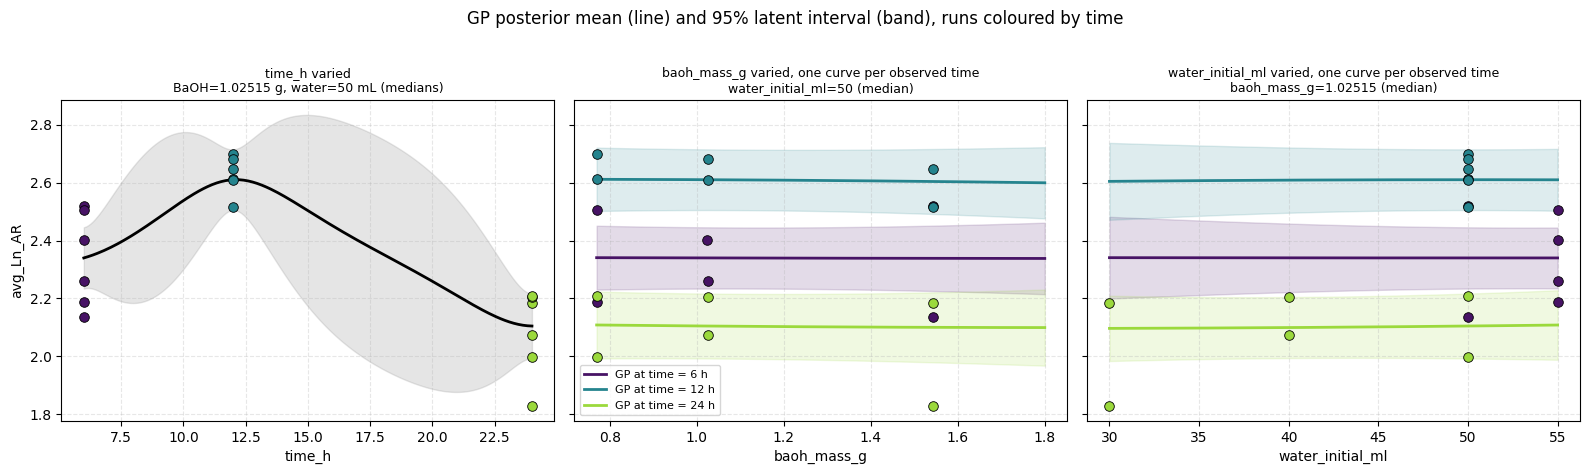

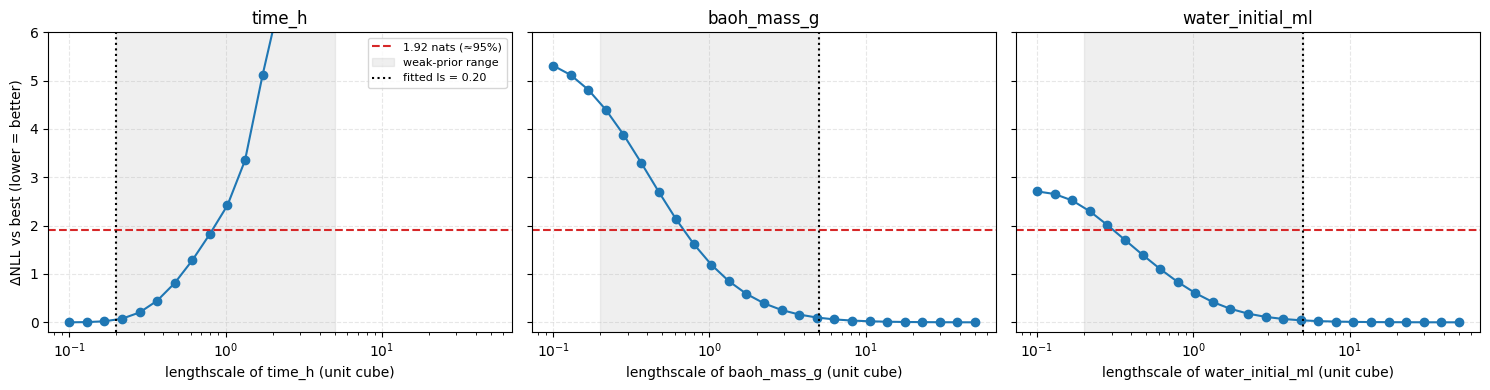

,fitted_ls,ls_within_95%,best_ls_in_grid,hits_upper_edge_of_grid
variable,,,,
time_h,0.2,0.10 – 0.79,0.1,False
baoh_mass_g,5.0,0.79 – 50.00,50.0,True
water_initial_ml,5.0,0.36 – 50.00,50.0,True


Reading it: a curve that stays under the red line out to the right edge means 'this variable could have NO effect';
a curve that rises steeply on the left means 'short, wiggly lengthscales are ruled out'.


In [ ]:
# ===================== DIAGNOSTICS A: time-coloured 1D slices =====================
import numpy as np, pandas as pd, matplotlib.pyplot as plt

def predict_raw(est, raw):
    """Latent-f mean and SD (avg_Ln_AR units) at raw points; columns of `raw` follow OPT_VARS."""
    raw = np.atleast_2d(raw).astype(float); n = len(raw)
    hto = np.full((n, 1), df["hto_mass_g"].median())          # only used if the GP has use_hto=True
    A = np.column_stack([raw, hto, np.zeros(n)])               # FEATURES + dummy batch_code (not used in predict)
    return est.predict(A, return_std=True)

def plot_slices_by_time(est, grid_n=200):
    """One panel per variable.
    BaOH and water panels: one curve per OBSERVED time level, same colour as the runs made at that time.
    Time panel: time varied, BaOH and water at their data medians; runs coloured by their own time."""
    time_levels = np.sort(df["time_h"].unique())
    med = {v: df[v].median() for v in OPT_VARS}
    colors = dict(zip(time_levels, plt.cm.viridis(np.linspace(0.05, 0.85, len(time_levels)))))
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
    for ax, var in zip(axes, OPT_VARS):
        grid = np.linspace(*BOUNDS[var], grid_n)
        if var == "time_h":
            raw = np.column_stack([grid if v == "time_h" else np.full(grid_n, med[v]) for v in OPT_VARS])
            mu, sd = predict_raw(est, raw)
            ax.fill_between(grid, mu - 1.96 * sd, mu + 1.96 * sd, color="gray", alpha=0.2)
            ax.plot(grid, mu, color="k", lw=2)
            ax.set_title(f"time_h varied\nBaOH={med['baoh_mass_g']:g} g, water={med['water_initial_ml']:g} mL (medians)", fontsize=9)
        else:
            for t in time_levels:
                raw = np.column_stack([grid if v == var else np.full(grid_n, t if v == "time_h" else med[v]) for v in OPT_VARS])
                mu, sd = predict_raw(est, raw)
                ax.fill_between(grid, mu - 1.96 * sd, mu + 1.96 * sd, color=colors[t], alpha=0.15)
                ax.plot(grid, mu, color=colors[t], lw=2, label=f"GP at time = {t:g} h")
            other = [v for v in OPT_VARS if v not in ("time_h", var)][0]
            ax.set_title(f"{var} varied, one curve per observed time\n{other}={med[other]:g} (median)", fontsize=9)
        for t in time_levels:                                   # observed runs, coloured by their own time
            m = df["time_h"] == t
            ax.scatter(df.loc[m, var], df.loc[m, TARGET], s=48, color=colors[t], edgecolor="k", lw=0.6, zorder=5,
                       label=f"runs at {t:g} h" if var == "time_h" else None)
        ax.set_xlabel(var); ax.grid(True, ls="--", alpha=0.3)
    axes[0].set_ylabel(TARGET)
    h, l = axes[1].get_legend_handles_labels(); axes[1].legend(h, l, fontsize=8, loc="best")
    fig.suptitle("GP posterior mean (line) and 95% latent interval (band), runs coloured by time", y=1.02)
    plt.tight_layout(); plt.show()

plot_slices_by_time(bo_est)


# ===================== DIAGNOSTICS B: lengthscale profile likelihood =====================
def profile_lengthscale(est, var_name, grid=None, ls_range=(0.1, 50.0), n_restarts=8, seed=0):
    """Fix ONE lengthscale at each value of `grid` (unit-cube units), re-optimise every other hyperparameter,
    and record the negative log marginal likelihood (lower = data like it more).
    Bounds here are wide ('free' amp/noise, ls up to 50) so the weak prior is NOT what limits the answer."""
    assert est.ard, "profile needs one lengthscale per input (ard=True)"
    j = OPT_VARS.index(var_name); d = est.U_.shape[1]
    grid = np.geomspace(0.1, ls_range[1], 25) if grid is None else np.asarray(grid)
    P = PRIORS["free"]; rng = np.random.default_rng(seed); out = []
    for L in grid:
        b = [tuple(np.log(P["amp2"]))] + [tuple(np.log(ls_range))] * d
        b[1 + j] = (np.log(L), np.log(L))                        # pin this lengthscale
        if est.batch_effect: b.append(tuple(np.log(P["sb2"])))
        b.append(tuple(np.log(P["sn2"])))
        best = np.inf
        for _ in range(n_restarts):
            res = minimize(neg_log_marginal_likelihood, [rng.uniform(lo, hi) for lo, hi in b],
                           args=(est.U_, est.ys_, est.b_, est.family, True, est.batch_effect, True),
                           method="L-BFGS-B", bounds=b)
            best = min(best, res.fun)
        out.append(best)
    out = np.array(out)
    return pd.DataFrame({"ls_unit": grid, "ls_raw_units": grid * (HI[j] - LO[j]), "nll": out, "delta_nll": out - out.min()})

def lengthscale_check(est, cutoff=1.92):
    """cutoff = 1.92 nats is the usual 95% likelihood-ratio threshold for ONE parameter (chi2_1/2)."""
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True); summary = []
    for ax, var in zip(axes, OPT_VARS):
        prof = profile_lengthscale(est, var)
        ok = prof[prof.delta_nll <= cutoff]
        j = OPT_VARS.index(var); fitted = est.H_["ls"][j]
        ax.plot(prof.ls_unit, prof.delta_nll, "o-", color="tab:blue")
        ax.axhline(cutoff, color="tab:red", ls="--", label=f"{cutoff} nats (≈95%)")
        ax.axvspan(PRIORS["weak"]["ls"][0], PRIORS["weak"]["ls"][1], color="gray", alpha=0.12, label="weak-prior range")
        ax.axvline(fitted, color="k", ls=":", label=f"fitted ls = {fitted:.2f}")
        ax.set_xscale("log"); ax.set_ylim(-0.2, 6); ax.set_xlabel(f"lengthscale of {var} (unit cube)")
        ax.grid(True, ls="--", alpha=0.3); ax.set_title(var)
        summary.append({"variable": var, "fitted_ls": round(fitted, 2),
                        "ls_within_95%": f"{ok.ls_unit.min():.2f} – {ok.ls_unit.max():.2f}",
                        "best_ls_in_grid": round(prof.loc[prof.nll.idxmin(), "ls_unit"], 2),
                        "hits_upper_edge_of_grid": bool(ok.ls_unit.max() >= 0.95 * 50)})
    axes[0].set_ylabel("ΔNLL vs best (lower = better)"); axes[0].legend(fontsize=8)
    plt.tight_layout(); plt.show()
    display(pd.DataFrame(summary).set_index("variable"))
    print("Reading it: a curve that stays under the red line out to the right edge means 'this variable could have NO effect';\n"
          "a curve that rises steeply on the left means 'short, wiggly lengthscales are ruled out'.")

lengthscale_check(bo_est)

### Variance GP diagnostics: time-coloured slices, constant-variance test, lengthscale profile

**What.** Refits the variance GP cleanly (`gp_var_fit`), draws time-coloured slices on a log axis with the band that pure chance would produce if the true variance were constant, tests a constant-variance model against the flexible GP, and profiles the lengthscales.

**Why.** Each replicate variance has one degree of freedom, so spread across recipes is expected even with constant noise. This section checks whether the observed pattern exceeds what chance explains. `gp_var_fit` is also what the heteroscedastic mean GP (Step 10f) uses by default.

optimizer fit        : {'amp2': 0.47756079931458656, 'ls': array([0.2, 5. , 0.2]), 'sb2': 0.0, 'sn2': 0.5348304609013458, 'nll': 12.342806830707204}
gp_var (current H_)  : {'amp2': 0.47756079931458656, 'ls': array([0.2, 5. , 0.2]), 'sb2': 0.0, 'sn2': 0.5348304609013458, 'nll': 12.342806830707204}


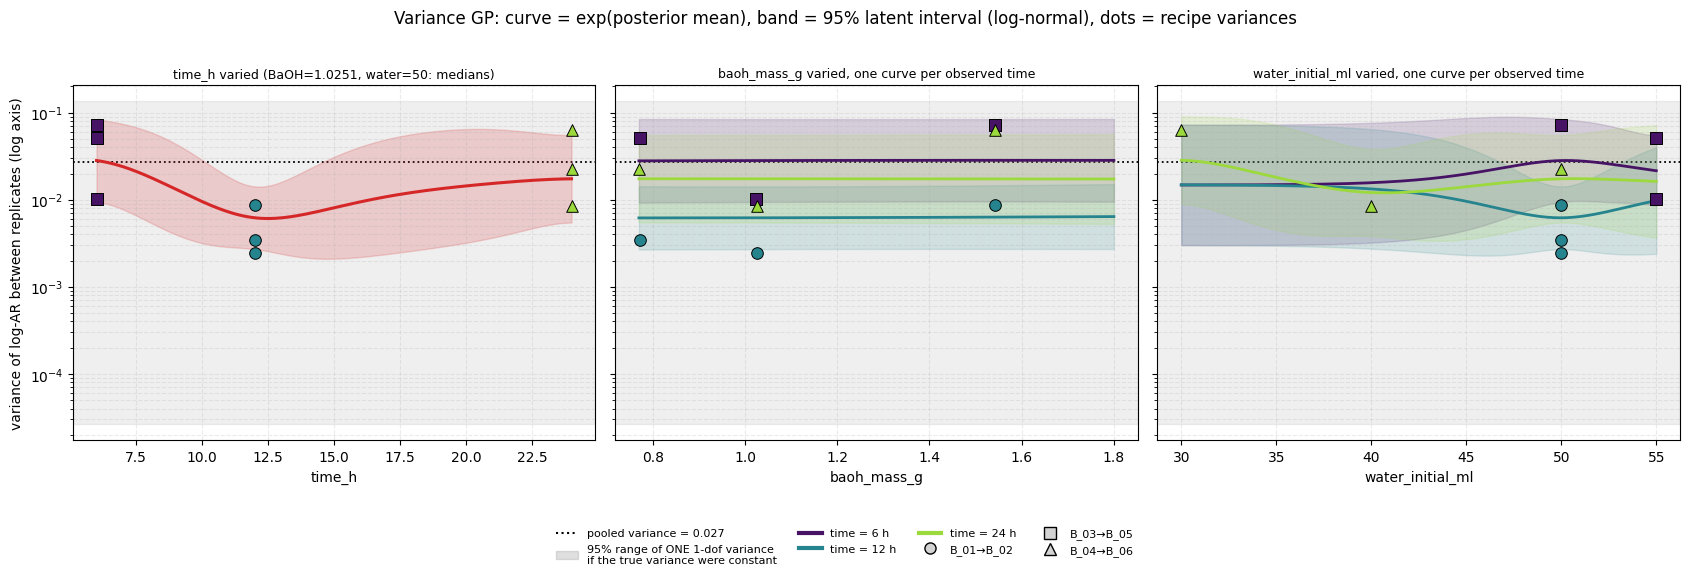

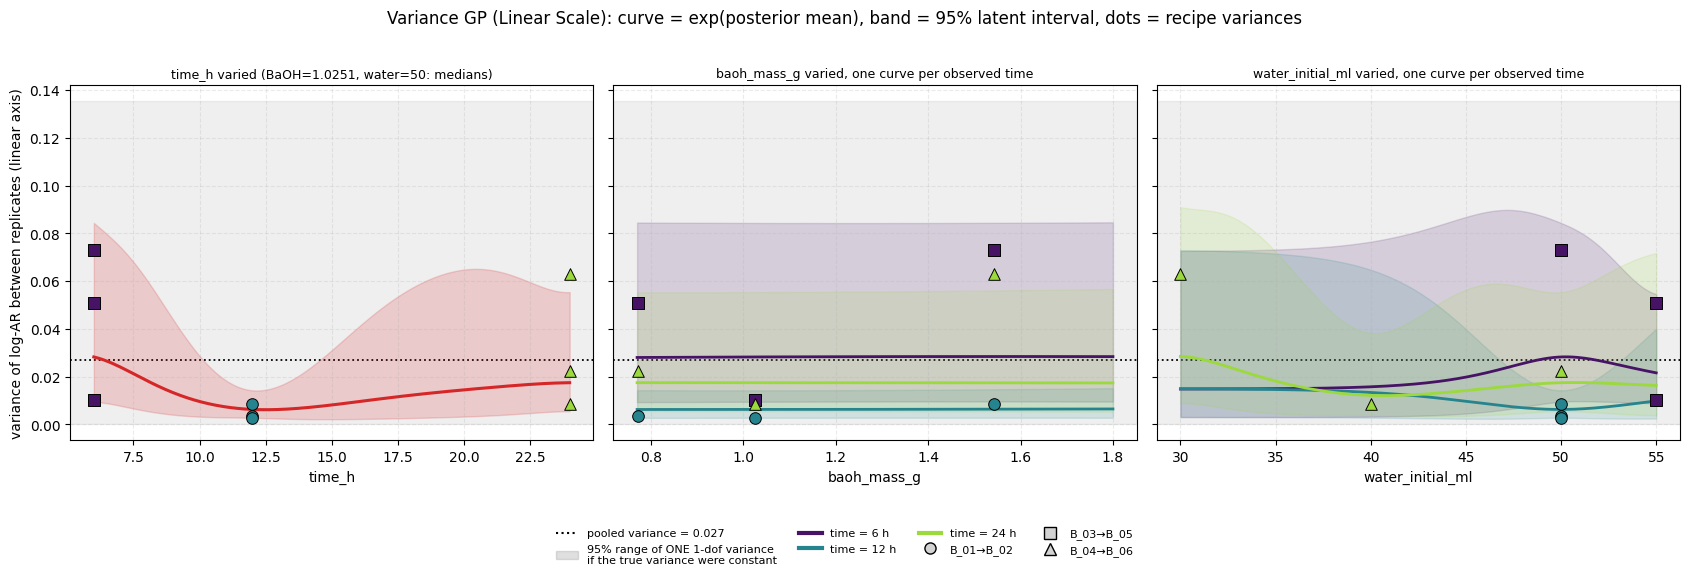

NLL best free model = 12.07 | NLL constant-variance model = 12.81 | difference = 0.74 nats (rough 95% bar for 3 lengthscales ≈ 3.9)


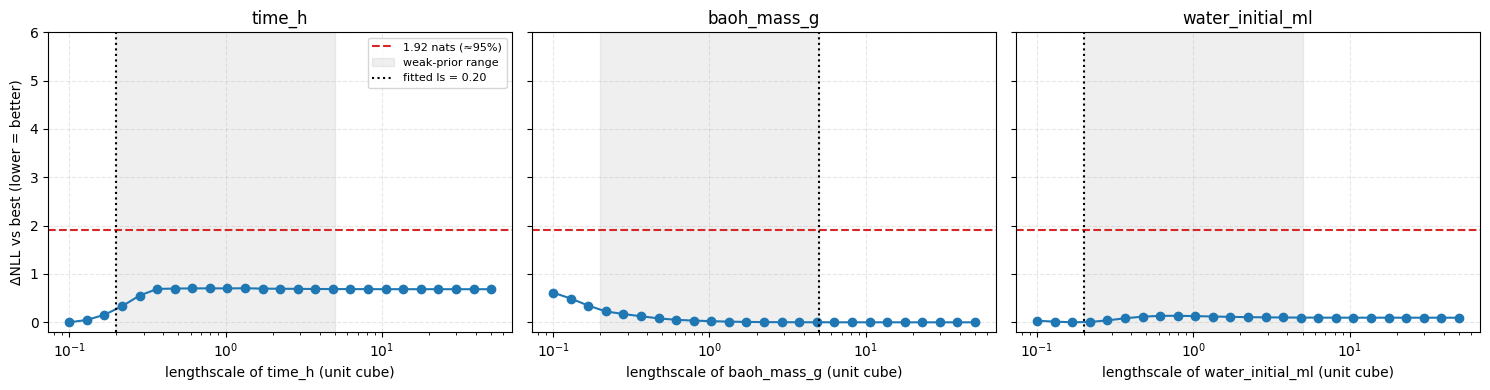

,fitted_ls,ls_within_95%,best_ls_in_grid,hits_upper_edge_of_grid
variable,,,,
time_h,0.2,0.10 – 50.00,0.10,True
baoh_mass_g,5.0,0.10 – 50.00,50.00,True
water_initial_ml,0.2,0.10 – 50.00,0.17,True


Reading it: a curve that stays under the red line out to the right edge means 'this variable could have NO effect';
a curve that rises steeply on the left means 'short, wiggly lengthscales are ruled out'.


In [ ]:
# Variance GP diagnostics. Needs recipe_stats / X_stats / y_var and the fitted gp_var, which the auxiliary-GP step creates earlier in the notebook.

# ===================== Variance GP diagnostics (time-coloured slices + lengthscale check) =====================
# Runs after the auxiliary-GP step (Step 10d) has built recipe_stats / X_stats / y_var and fitted gp_var.
from matplotlib.lines import Line2D
from scipy.stats import chi2

VAR_COL = "log_AR_variance"                      # sample variance of log-AR per recipe (from recipe_stats)

# Clean refit with the notebook's own settings, so the plots show what the OPTIMIZER found,
# not the hand-set overrides (predict() recomputes from gp_var.H_, so overrides DO change gp_var's curves).
gp_var_fit = GPSurrogate(family="matern52", batch_effect=False, use_hto=False, prior="weak",
                         n_restarts=FINAL_RESTARTS).fit(X_stats, y_var)
print("optimizer fit        :", {k: v for k, v in gp_var_fit.H_.items() if k != "family"})
print("gp_var (current H_)  :", {k: v for k, v in gp_var.H_.items() if k != "family"})

def plot_variance_slices_by_time(est, grid_n=200):
    """y-axis = variance on a LOG scale (the scale the GP actually models), so bands stay positive.
    Gray band = what pure chance does to ONE sample variance if the true variance were constant (= pooled variance)."""
    time_levels = np.sort(recipe_stats["time_h"].unique())
    med = {v: recipe_stats[v].median() for v in OPT_VARS}
    colors = dict(zip(time_levels, plt.cm.viridis(np.linspace(0.05, 0.85, len(time_levels)))))
    pair = recipe_stats["first_batch"].astype(str) + "→" + recipe_stats["last_batch"].astype(str)
    shapes = dict(zip(sorted(pair.unique()), ["o", "s", "^", "D", "v", "P", "X", "h", "<", ">"]))
    nu = max(int(recipe_stats["n_replicates"].min()) - 1, 1)                   # degrees of freedom of each sample variance
    pooled = recipe_stats[VAR_COL].mean()                                       # arithmetic mean = unbiased pooled variance
    lo_c, hi_c = pooled * chi2.ppf([0.025, 0.975], nu) / nu

    # Generate primary log-scale plot
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
    for ax, var in zip(axes, OPT_VARS):
        grid = np.linspace(*BOUNDS[var], grid_n)
        def band(fixed_time):
            raw = np.column_stack([grid if v == var else np.full(grid_n, fixed_time if v == "time_h" else med[v]) for v in OPT_VARS])
            return est.predict(pd.DataFrame(raw, columns=OPT_VARS), return_std=True)
        ax.axhspan(lo_c, hi_c, color="gray", alpha=0.12, zorder=0)
        ax.axhline(pooled, color="k", ls=":", lw=1.3, zorder=1)
        if var == "time_h":
            mu, sd = band(None)
            ax.fill_between(grid, np.exp(mu - 1.96 * sd), np.exp(mu + 1.96 * sd), color="tab:red", alpha=0.18)
            ax.plot(grid, np.exp(mu), color="tab:red", lw=2.2)
            ax.set_title(f"time_h varied (BaOH={med['baoh_mass_g']:g}, water={med['water_initial_ml']:g}: medians)", fontsize=9)
        else:
            for t in time_levels:
                mu, sd = band(t)
                ax.fill_between(grid, np.exp(mu - 1.96 * sd), np.exp(mu + 1.96 * sd), color=colors[t], alpha=0.15)
                ax.plot(grid, np.exp(mu), color=colors[t], lw=2)
            ax.set_title(f"{var} varied, one curve per observed time", fontsize=9)
        for p in pair.unique():
            for t in time_levels:
                m = (pair == p) & (recipe_stats["time_h"] == t)
                if m.any():
                    ax.scatter(recipe_stats.loc[m, var], recipe_stats.loc[m, VAR_COL], s=70, color=colors[t],
                               marker=shapes[p], edgecolor="k", lw=0.7, zorder=5)
        ax.set_yscale("log"); ax.set_xlabel(var); ax.grid(True, which="both", ls="--", alpha=0.25)
    axes[0].set_ylabel("variance of log-AR between replicates (log axis)")
    h_t = [Line2D([], [], color=colors[t], lw=3, label=f"time = {t:g} h") for t in time_levels]
    h_ref = [Line2D([], [], color="k", ls=":", label=f"pooled variance = {pooled:.3f}"),
             plt.Rectangle((0, 0), 1, 1, color="gray", alpha=0.25, label=f"95% range of ONE {nu}-dof variance\nif the true variance were constant")]
    h_b = [Line2D([], [], marker=shapes[p], color="w", markerfacecolor="lightgray", markeredgecolor="k", ms=8, label=p) for p in sorted(pair.unique())]
    fig.legend(handles=h_ref + h_t + h_b, loc="lower center", ncol=4, fontsize=8, frameon=False, bbox_to_anchor=(0.5, -0.16))
    fig.suptitle("Variance GP: curve = exp(posterior mean), band = 95% latent interval (log-normal), dots = recipe variances", y=1.02)
    plt.tight_layout(); plt.show()

    # Generate secondary linear-scale plot (identical model construction but standard linear y-axis)
    fig_lin, axes_lin = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
    for ax, var in zip(axes_lin, OPT_VARS):
        grid = np.linspace(*BOUNDS[var], grid_n)
        def band(fixed_time):
            raw = np.column_stack([grid if v == var else np.full(grid_n, fixed_time if v == "time_h" else med[v]) for v in OPT_VARS])
            return est.predict(pd.DataFrame(raw, columns=OPT_VARS), return_std=True)
        ax.axhspan(lo_c, hi_c, color="gray", alpha=0.12, zorder=0)
        ax.axhline(pooled, color="k", ls=":", lw=1.3, zorder=1)
        if var == "time_h":
            mu, sd = band(None)
            ax.fill_between(grid, np.exp(mu - 1.96 * sd), np.exp(mu + 1.96 * sd), color="tab:red", alpha=0.18)
            ax.plot(grid, np.exp(mu), color="tab:red", lw=2.2)
            ax.set_title(f"time_h varied (BaOH={med['baoh_mass_g']:g}, water={med['water_initial_ml']:g}: medians)", fontsize=9)
        else:
            for t in time_levels:
                mu, sd = band(t)
                ax.fill_between(grid, np.exp(mu - 1.96 * sd), np.exp(mu + 1.96 * sd), color=colors[t], alpha=0.15)
                ax.plot(grid, np.exp(mu), color=colors[t], lw=2)
            ax.set_title(f"{var} varied, one curve per observed time", fontsize=9)
        for p in pair.unique():
            for t in time_levels:
                m = (pair == p) & (recipe_stats["time_h"] == t)
                if m.any():
                    ax.scatter(recipe_stats.loc[m, var], recipe_stats.loc[m, VAR_COL], s=70, color=colors[t],
                               marker=shapes[p], edgecolor="k", lw=0.7, zorder=5)
        ax.set_xlabel(var); ax.grid(True, ls="--", alpha=0.25)
    axes_lin[0].set_ylabel("variance of log-AR between replicates (linear axis)")
    fig_lin.legend(handles=h_ref + h_t + h_b, loc="lower center", ncol=4, fontsize=8, frameon=False, bbox_to_anchor=(0.5, -0.16))
    fig_lin.suptitle("Variance GP (Linear Scale): curve = exp(posterior mean), band = 95% latent interval, dots = recipe variances", y=1.02)
    plt.tight_layout(); plt.show()

plot_variance_slices_by_time(gp_var_fit)

def constant_variance_check(est, ls_const=50.0, n_restarts=10, seed=0):
    """Is ANY spatial structure in the variance supported? Compare the best 'free' GP with one whose lengthscales are all
    huge (= variance constant everywhere). ~3.9 nats is the rough 95% bar for 3 extra lengthscales."""
    d = est.U_.shape[1]; P = PRIORS["free"]; rng = np.random.default_rng(seed)
    def best(bounds):
        out = np.inf
        for _ in range(n_restarts):
            r = minimize(neg_log_marginal_likelihood, [rng.uniform(lo, hi) for lo, hi in bounds],
                         args=(est.U_, est.ys_, est.b_, est.family, True, est.batch_effect, True), method="L-BFGS-B", bounds=bounds)
            out = min(out, r.fun)
        return out
    tail = ([tuple(np.log(P["sb2"]))] if est.batch_effect else []) + [tuple(np.log(P["sn2"]))]
    free = best([tuple(np.log(P["amp2"]))] + [(np.log(0.1), np.log(ls_const))] * d + tail)
    const = best([tuple(np.log(P["amp2"]))] + [(np.log(ls_const), np.log(ls_const))] * d + tail)
    print(f"NLL best free model = {free:.2f} | NLL constant-variance model = {const:.2f} | difference = {const - free:.2f} nats "
          f"(rough 95% bar for 3 lengthscales ≈ 3.9)")

# ---- profile-likelihood helpers (identical to the helpers defined in the mean-GP diagnostics cell; harmless to re-run)
def profile_lengthscale(est, var_name, grid=None, ls_range=(0.1, 50.0), n_restarts=8, seed=0):
    """Fix ONE lengthscale at each value of `grid` (unit-cube units), re-optimise every other hyperparameter,
    and record the negative log marginal likelihood (lower = data like it more).
    Bounds here are wide ('free' amp/noise, ls up to 50) so the weak prior is NOT what limits the answer."""
    assert est.ard, "profile needs one lengthscale per input (ard=True)"
    j = OPT_VARS.index(var_name); d = est.U_.shape[1]
    grid = np.geomspace(0.1, ls_range[1], 25) if grid is None else np.asarray(grid)
    P = PRIORS["free"]; rng = np.random.default_rng(seed); out = []
    for L in grid:
        b = [tuple(np.log(P["amp2"]))] + [tuple(np.log(ls_range))] * d
        b[1 + j] = (np.log(L), np.log(L))                        # pin this lengthscale
        if est.batch_effect: b.append(tuple(np.log(P["sb2"])))
        b.append(tuple(np.log(P["sn2"])))
        best = np.inf
        for _ in range(n_restarts):
            res = minimize(neg_log_marginal_likelihood, [rng.uniform(lo, hi) for lo, hi in b],
                           args=(est.U_, est.ys_, est.b_, est.family, True, est.batch_effect, True),
                           method="L-BFGS-B", bounds=b)
            best = min(best, res.fun)
        out.append(best)
    out = np.array(out)
    return pd.DataFrame({"ls_unit": grid, "ls_raw_units": grid * (HI[j] - LO[j]), "nll": out, "delta_nll": out - out.min()})

def lengthscale_check(est, cutoff=1.92):
    """cutoff = 1.92 nats is the usual 95% likelihood-ratio threshold for ONE parameter (chi2_1/2)."""
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True); summary = []
    for ax, var in zip(axes, OPT_VARS):
        prof = profile_lengthscale(est, var)
        ok = prof[prof.delta_nll <= cutoff]
        j = OPT_VARS.index(var); fitted = est.H_["ls"][j]
        ax.plot(prof.ls_unit, prof.delta_nll, "o-", color="tab:blue")
        ax.axhline(cutoff, color="tab:red", ls="--", label=f"{cutoff} nats (≈95%)")
        ax.axvspan(PRIORS["weak"]["ls"][0], PRIORS["weak"]["ls"][1], color="gray", alpha=0.12, label="weak-prior range")
        ax.axvline(fitted, color="k", ls=":", label=f"fitted ls = {fitted:.2f}")
        ax.set_xscale("log"); ax.set_ylim(-0.2, 6); ax.set_xlabel(f"lengthscale of {var} (unit cube)")
        ax.grid(True, ls="--", alpha=0.3); ax.set_title(var)
        summary.append({"variable": var, "fitted_ls": round(fitted, 2),
                        "ls_within_95%": f"{ok.ls_unit.min():.2f} – {ok.ls_unit.max():.2f}",
                        "best_ls_in_grid": round(prof.loc[prof.nll.idxmin(), "ls_unit"], 2),
                        "hits_upper_edge_of_grid": bool(ok.ls_unit.max() >= 0.95 * 50)})
    axes[0].set_ylabel("ΔNLL vs best (lower = better)"); axes[0].legend(fontsize=8)
    plt.tight_layout(); plt.show()
    display(pd.DataFrame(summary).set_index("variable"))
    print("Reading it: a curve that stays under the red line out to the right edge means 'this variable could have NO effect';\n"
          "a curve that rises steeply on the left means 'short, wiggly lengthscales are ruled out'.")

constant_variance_check(gp_var_fit)
lengthscale_check(gp_var_fit)

### Delta GP Deep Dive: Slices, Global Calibration, and Lengthscale Profiles
This section mirrors the diagnostic analysis performed for the Variance GP to evaluate if spatial gradients in batch discrepancies across `time_h`, `baoh_mass_g`, and `water_initial_ml` are statistically supported by the dataset.


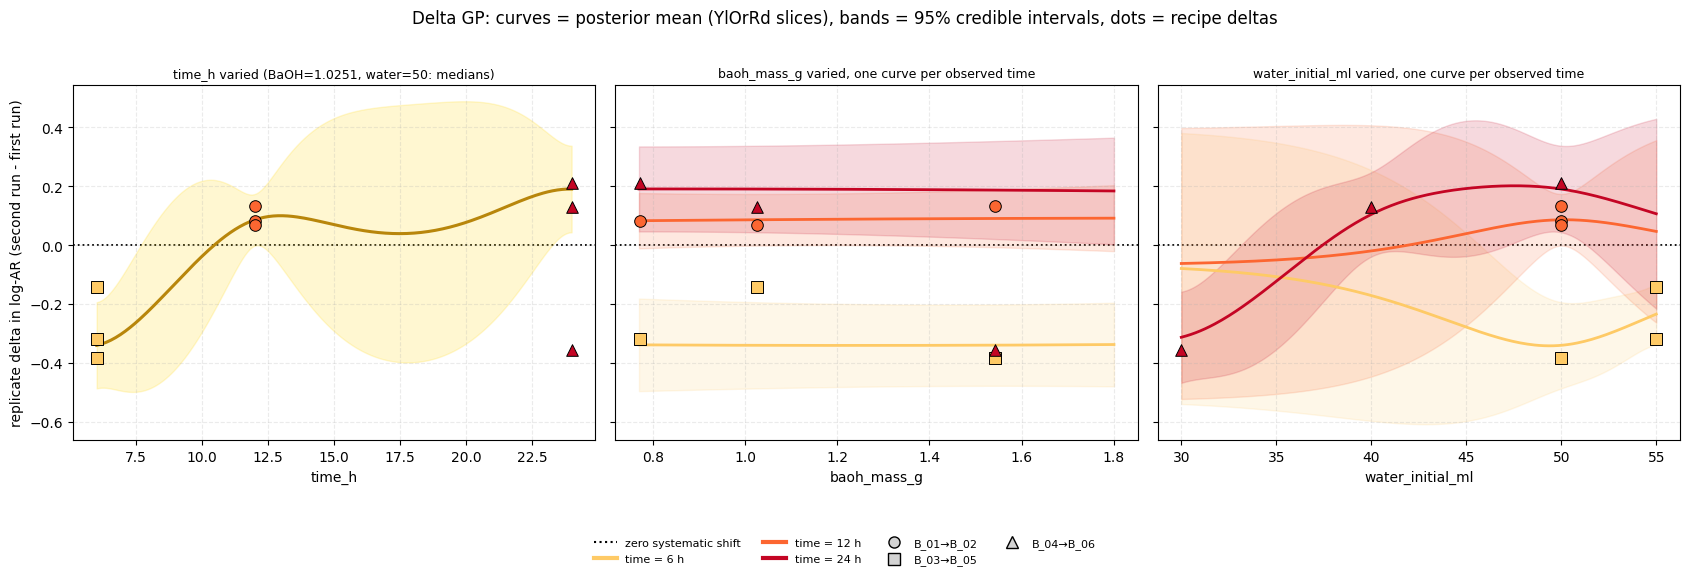


NLL best free model = 10.46 | NLL constant-delta model = 12.81 | difference = 2.36 nats (rough 95% bar for 3 lengthscales ≈ 3.9)


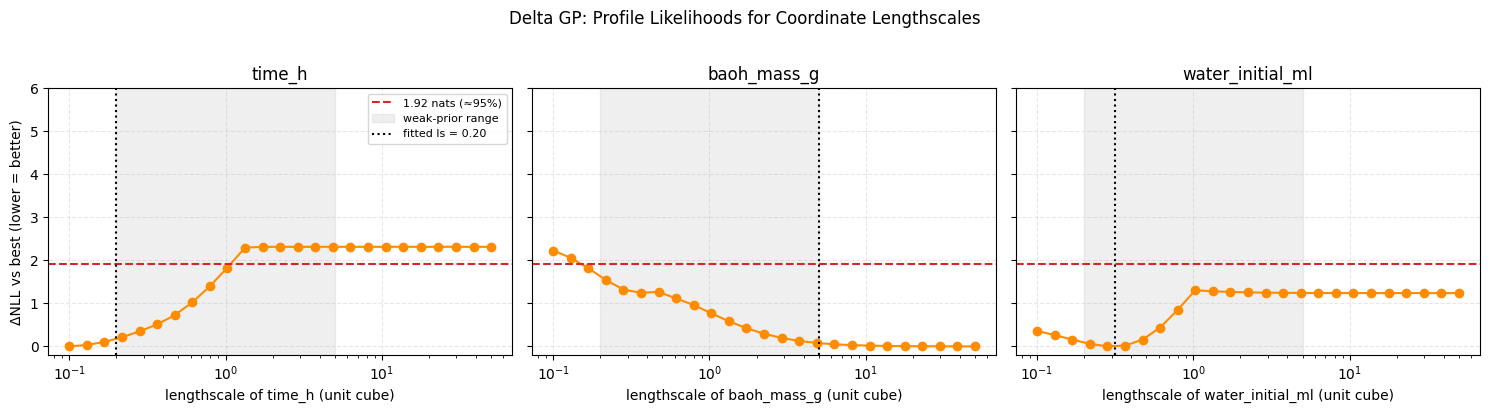

,fitted_ls,ls_within_95%,best_ls_in_grid,hits_upper_edge_of_grid
variable,,,,
time_h,0.20,0.10 – 1.03,0.10,False
baoh_mass_g,5.00,0.17 – 50.00,50.00,True
water_initial_ml,0.31,0.10 – 50.00,0.28,True


In [ ]:
# ===========================================================================
# DELTA GP DIAGNOSTICS: Slices, Constant Check, and Profile Likelihoods
# ===========================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.optimize import minimize

# Ensure we have a clean refit of the Delta GP using our optimized settings
gp_delta_fit = GPSurrogate(family="matern52", batch_effect=False, use_hto=False, prior="weak",
                           n_restarts=FINAL_RESTARTS).fit(X_stats, y_delta)

def plot_delta_slices_by_time(est, grid_n=200):
    """y-axis = signed log-AR replicate delta (linear scale).
    Colors follow a yellow/autumn gradient for the time-varying slices."""
    time_levels = np.sort(recipe_stats["time_h"].unique())
    med = {v: recipe_stats[v].median() for v in OPT_VARS}

    # Yellow-based color palette as requested (YlOrRd colormap ensures high visibility)
    colors = dict(zip(time_levels, plt.cm.YlOrRd(np.linspace(0.3, 0.85, len(time_levels)))))
    pair = recipe_stats["first_batch"].astype(str) + "→" + recipe_stats["last_batch"].astype(str)
    shapes = dict(zip(sorted(pair.unique()), ["o", "s", "^", "D", "v", "P", "X", "h", "<", ">"]))

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
    for ax, var in zip(axes, OPT_VARS):
        grid = np.linspace(*BOUNDS[var], grid_n)
        def band(fixed_time):
            raw = np.column_stack([grid if v == var else np.full(grid_n, fixed_time if v == "time_h" else med[v]) for v in OPT_VARS])
            return est.predict(pd.DataFrame(raw, columns=OPT_VARS), return_std=True)

        ax.axhline(0.0, color="k", ls=":", lw=1.3, zorder=1)
        if var == "time_h":
            mu, sd = band(None)
            ax.fill_between(grid, mu - 1.96 * sd, mu + 1.96 * sd, color="gold", alpha=0.18)
            ax.plot(grid, mu, color="darkgoldenrod", lw=2.2)
            ax.set_title(f"time_h varied (BaOH={med['baoh_mass_g']:g}, water={med['water_initial_ml']:g}: medians)", fontsize=9)
        else:
            for t in time_levels:
                mu, sd = band(t)
                ax.fill_between(grid, mu - 1.96 * sd, mu + 1.96 * sd, color=colors[t], alpha=0.15)
                ax.plot(grid, mu, color=colors[t], lw=2)
            ax.set_title(f"{var} varied, one curve per observed time", fontsize=9)

        for p in pair.unique():
            for t in time_levels:
                m = (pair == p) & (recipe_stats["time_h"] == t)
                if m.any():
                    ax.scatter(recipe_stats.loc[m, var], recipe_stats.loc[m, "delta_log_AR_second_minus_first"], s=70, color=colors[t],
                               marker=shapes[p], edgecolor="k", lw=0.7, zorder=5)
        ax.set_xlabel(var); ax.grid(True, ls="--", alpha=0.25)

    axes[0].set_ylabel("replicate delta in log-AR (second run - first run)")
    h_t = [Line2D([], [], color=colors[t], lw=3, label=f"time = {t:g} h") for t in time_levels]
    h_ref = [Line2D([], [], color="k", ls=":", label="zero systematic shift")]
    h_b = [Line2D([], [], marker=shapes[p], color="w", markerfacecolor="lightgray", markeredgecolor="k", ms=8, label=p) for p in sorted(pair.unique())]
    fig.legend(handles=h_ref + h_t + h_b, loc="lower center", ncol=4, fontsize=8, frameon=False, bbox_to_anchor=(0.5, -0.16))
    fig.suptitle("Delta GP: curves = posterior mean (YlOrRd slices), bands = 95% credible intervals, dots = recipe deltas", y=1.02)
    plt.tight_layout(); plt.show()

# Run the slice visualization
plot_delta_slices_by_time(gp_delta_fit)

# --- Calibration & Significance checks ---
def constant_delta_check(est, ls_const=50.0, n_restarts=10, seed=0):
    """Is any spatial variation in batch-to-batch shift supported over a constant global offset?"""
    d = est.U_.shape[1]; P = PRIORS["free"]; rng = np.random.default_rng(seed)
    def best(bounds):
        out = np.inf
        for _ in range(n_restarts):
            r = minimize(neg_log_marginal_likelihood, [rng.uniform(lo, hi) for lo, hi in bounds],
                         args=(est.U_, est.ys_, est.b_, est.family, True, est.batch_effect, True), method="L-BFGS-B", bounds=bounds)
            out = min(out, r.fun)
        return out
    tail = ([tuple(np.log(P["sb2"]))] if est.batch_effect else []) + [tuple(np.log(P["sn2"]))]
    free = best([tuple(np.log(P["amp2"]))] + [(np.log(0.1), np.log(ls_const))] * d + tail)
    const = best([tuple(np.log(P["amp2"]))] + [(np.log(ls_const), np.log(ls_const))] * d + tail)
    print(f"\nNLL best free model = {free:.2f} | NLL constant-delta model = {const:.2f} | difference = {const - free:.2f} nats "
          f"(rough 95% bar for 3 lengthscales ≈ 3.9)")

def delta_lengthscale_check(est, cutoff=1.92):
    """Profile likelihood for each coordinate lengthscale of the Delta GP"""
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True); summary = []
    for ax, var in zip(axes, OPT_VARS):
        prof = profile_lengthscale(est, var)
        ok = prof[prof.delta_nll <= cutoff]
        j = OPT_VARS.index(var); fitted = est.H_["ls"][j]
        ax.plot(prof.ls_unit, prof.delta_nll, "o-", color="darkorange")
        ax.axhline(cutoff, color="tab:red", ls="--", label=f"{cutoff} nats (≈95%)")
        ax.axvspan(PRIORS["weak"]["ls"][0], PRIORS["weak"]["ls"][1], color="gray", alpha=0.12, label="weak-prior range")
        ax.axvline(fitted, color="k", ls=":", label=f"fitted ls = {fitted:.2f}")
        ax.set_xscale("log"); ax.set_ylim(-0.2, 6); ax.set_xlabel(f"lengthscale of {var} (unit cube)")
        ax.grid(True, ls="--", alpha=0.3); ax.set_title(var)
        summary.append({"variable": var, "fitted_ls": round(fitted, 2),
                        "ls_within_95%": f"{ok.ls_unit.min():.2f} – {ok.ls_unit.max():.2f}",
                        "best_ls_in_grid": round(prof.loc[prof.nll.idxmin(), "ls_unit"], 2),
                        "hits_upper_edge_of_grid": bool(ok.ls_unit.max() >= 0.95 * 50)})
    axes[0].set_ylabel("ΔNLL vs best (lower = better)"); axes[0].legend(fontsize=8)
    fig.suptitle("Delta GP: Profile Likelihoods for Coordinate Lengthscales", y=1.02)
    plt.tight_layout(); plt.show()
    display(pd.DataFrame(summary).set_index("variable"))

constant_delta_check(gp_delta_fit)
delta_lengthscale_check(gp_delta_fit)

# Heteroscedastic mean GP: letting the measurement noise depend on the recipe

**What this notebook section does.** It builds a *clone* of the final mean GP (`bo_est`) whose noise level is not one constant but varies from run to run, with the shape taken from the  fitted **variance GP**. It then plots the original and the clone side by side. The original `bo_est` is never modified; the clone is a new object called `bo_est_hetero`.

## 1. The standard (homoscedastic) GP, and what is wrong with it here

Let $y_i$ be the measured `avg_Ln_AR` of run $i$ at recipe $x_i=(\text{time},\text{BaOH},\text{water})$. The GP assumes a smooth hidden function $f$ plus measurement noise:

$$y_i = f(x_i) + \varepsilon_i, \qquad \varepsilon_i \sim \mathcal N(0,\sigma_n^2)\ \ \text{(the same } \sigma_n^2 \text{ for every run)}$$

After standardising $y$, all measurements together follow

$$\mathbf y \sim \mathcal N\big(\mathbf 0,\; K + \sigma_n^2 I\big),$$

where $K_{ij}=k(x_i,x_j)$ is the kernel (the prior correlation of $f$ at two recipes) and $I$ is the identity matrix. The posterior of $f$ at a new recipe $x_*$ is

$$\mu_*(x_*)=\mathbf k_*^\top (K+\sigma_n^2 I)^{-1}\mathbf y, \qquad v_*(x_*)=k(x_*,x_*)-\mathbf k_*^\top (K+\sigma_n^2 I)^{-1}\mathbf k_* .$$

The problem: the replicates scatter very differently at different conditions (the variance GP shows a lower variance around 12 h than at 6 h or 24 h). A single $\sigma_n^2$ forces the GP to treat a precise 12 h run and a scattered 6 h run as equally trustworthy.

## 2. The heteroscedastic GP

We let the noise variance depend on the recipe, $\varepsilon_i\sim\mathcal N\big(0,\sigma^2(x_i)\big)$. The only change in the equations is that $\sigma_n^2 I$ becomes a diagonal matrix with one entry per run:

$$\Sigma=\operatorname{diag}\big(\sigma^2(x_1),\dots,\sigma^2(x_n)\big),\qquad \mathbf y\sim\mathcal N\big(\mathbf 0,\;K+\Sigma\big),$$

with the same posterior formulas as above, with $\sigma_n^2 I$ replaced by $\Sigma$. The hyperparameters (kernel amplitude and lengthscales, and the oven offset if used) are learned by minimising the negative log marginal likelihood

$$-\ln p(\mathbf y)=\tfrac12\,\mathbf y^\top (K+\Sigma)^{-1}\mathbf y+\tfrac12\ln\lvert K+\Sigma\rvert+\tfrac n2\ln 2\pi,$$

exactly as in the original model.

**Intuition: shrinkage.** For a single run whose prior variance of $f$ is $a$ and whose noise variance is $\sigma^2$, the posterior mean is $\mu=\dfrac{a}{a+\sigma^2}\,y$. A noisy run is pulled less strongly, so the curve follows the precise runs more closely and trusts the scattered ones less.

## 3. Where $\sigma^2(x)$ comes from: the variance GP, with two corrections

For each recipe $r$ with $n$ replicates, $s_r^2$ is the sample variance, with $\nu=n-1$ degrees of freedom. The variance GP models $g(x)=\ln s^2$. Two facts make $\exp(g)$ a biased estimate of the noise variance:

1. **Bias of the log of a sample variance.** Since $s^2=\sigma^2\chi^2_\nu/\nu$,
$$\mathbb E[\ln s^2]=\ln\sigma^2+\psi(\nu/2)+\ln(2/\nu),$$
where $\psi$ is the digamma function. For two replicates ($\nu=1$) this offset is $-1.27$, so $\exp(g)$ underestimates $\sigma^2$ by a factor of about 3.6.
2. **Log-normal mean.** The variance GP gives $g(x)\sim\mathcal N(m,v)$ at each recipe, and $\mathbb E[e^{g}]=e^{m+v/2}$, not $e^{m}$.

Combining both, the expected noise variance at a recipe is

$$\hat\sigma^2(x)=\exp\!\Big(m_g(x)+\tfrac12 v_g(x)-\big[\psi(\nu/2)+\ln(2/\nu)\big]\Big).$$

## 4. A global noise scale $\kappa$ (optional, on by default)

We use $\Sigma=\kappa\,\operatorname{diag}\big(\hat\sigma^2(x_i)\big)$ and learn the single number $\kappa$ from the mean GP's marginal likelihood. The variance GP supplies the **shape** of the noise across recipes, while $\kappa$ calibrates the **level**. Reading it:

- $\kappa\approx 1$: the replicate-based noise and the mean GP's likelihood agree.
- $\kappa>1$: the mean GP sees more scatter than the replicates explain (for example misfit or oven effects).
- $\kappa<1$: the opposite.

Set `LEARN_NOISE_SCALE = False` to fix $\kappa=1$ and use the variance GP's noise exactly. The noise is divided by $\mathrm{sd}(y)^2$ because the GP works on standardised $y$.

## 5. What to keep in mind

- **Weak evidence behind the variance GP.** It is fitted to 9 sample variances with one degree of freedom each, so its shape is uncertain. Treat this as a sensitivity analysis: how much would the mean GP change if noise really did depend on time?
- **The data are used twice.** The same replicates feed the variance GP and the mean GP, so the likelihood improvement of the clone is optimistic. A fair comparison refits the variance GP inside each cross-validation fold.
- **The plotted band is for the latent $f$.** A new measurement would add its own noise $\sigma^2(x)$ on top.
- **Acquisition code is unchanged.** `BOContext`, EI and q-NEI still assume a constant noise. To use the clone for a BO round, their covariance function must be replaced by the heteroscedastic one in this section.


In [ ]:
# =====================================================================================================
# Heteroscedastic mean GP, part 1: build a HETEROSCEDASTIC clone of the final mean GP (bo_est) and fit it.
# Needs (already defined earlier in the notebook): df, X_cv, y_ser, OPT_VARS, bo_est, recipe_stats, a fitted variance GP,
#   and the GP helper functions kernel_matrix / unpack / theta_bounds, plus GPSurrogate.
# bo_est itself is NEVER modified: the new model is a separate object, `bo_est_hetero`.
# =====================================================================================================
import copy
from scipy.special import digamma                       # ψ(x), needed for the log-variance bias correction
from scipy.linalg import cho_factor, cho_solve, cholesky
from scipy.optimize import minimize

# ---- USER SETTINGS ------------------------------------------------------------------------------------
# Which fitted variance GP to plug in. Point this at the preferred version (e.g. the one behind the
# time-dependent variance plot). The default is the clean refit from the variance-GP diagnostics cell,
# falling back to the notebook's gp_var if that cell was not run.
VAR_GP = gp_var_fit if "gp_var_fit" in globals() else gp_var
# True : noise = kappa * (variance-GP noise), kappa learned from the mean GP's likelihood (recommended)
# False: noise = variance-GP noise exactly (kappa fixed at 1)
LEARN_NOISE_SCALE = True
# --------------------------------------------------------------------------------------------------------

orig_snapshot = copy.deepcopy(bo_est.H_)                # snapshot, only used at the end to prove bo_est was not touched

# ---------- 1. variance GP  ->  expected noise variance of every training run -----------------------------
def noise_variance_from_var_gp(var_gp, runs, n_rep):
    """The variance GP models g(x) = ln(sample variance of the replicates). Two corrections turn its posterior
    into the expected measurement-noise variance sigma^2(x) of ONE run:
      (a) bias: with nu = n_rep-1 degrees of freedom, E[ln s^2] = ln sigma^2 + psi(nu/2) + ln(2/nu)
          (= -1.27 for two replicates), so exp(g) alone UNDERestimates sigma^2 by about 3.6x;
      (b) log-normal mean: if g(x) ~ N(m, v) then E[exp(g)] = exp(m + v/2), not exp(m)."""
    nu = n_rep - 1                                                       # degrees of freedom of each sample variance
    log_bias = digamma(nu / 2.0) + np.log(2.0 / nu)                      # E[ln s^2] - ln sigma^2  (negative number)
    m, sd = var_gp.predict(runs[OPT_VARS], return_std=True)              # posterior mean / SD of g at each run's recipe
    return np.exp(m + 0.5 * sd ** 2 - log_bias)                          # sigma^2(x_i) in log-AR^2 units

n_rep = int(recipe_stats["n_replicates"].min())                          # replicates per recipe (2 in this design)
noise_var = noise_variance_from_var_gp(VAR_GP, df, n_rep)                # one noise variance per training run

# ---------- 2. covariance with a DIAGONAL, run-specific noise term ----------------------------------------
def hetero_train_cov(H, U, batch, noise_i):
    """K(x,x') + oven-offset block + diag(kappa * sigma_i^2).  The homoscedastic GP uses sn2 * I here; the ONLY change
    for heteroscedasticity is that this diagonal now has a different entry for each run.  Here H['sn2'] plays the role
    of kappa (a global scale on the noise), because we reuse the notebook's unpack()."""
    same_oven = (batch[:, None] == batch[None, :]).astype(float)         # 1 where two runs came from the same oven run
    K = kernel_matrix(U, U, H["ls"], H["amp2"], H["family"])             # smooth recipe effect (the GP prior on f)
    return K + H["sb2"] * same_oven + np.diag(H["sn2"] * noise_i + 1e-8) # + per-run noise on the diagonal (jitter for stability)

class HeteroGPSurrogate(GPSurrogate):
    """Same kernel/prior/standardisation as GPSurrogate, but with known-shape, run-specific noise variances."""
    def __init__(self, family="matern52", ard=True, batch_effect=True, prior="weak", use_hto=False,
                 signal=True, n_restarts=CV_RESTARTS, seed=SEED, learn_noise_scale=True):
        super().__init__(family=family, ard=ard, batch_effect=batch_effect, prior=prior, use_hto=use_hto,
                         signal=signal, n_restarts=n_restarts, seed=seed)
        self.learn_noise_scale = learn_noise_scale

    def fit(self, X, y, noise_var):
        A = np.asarray(X, float); y = np.asarray(y, float)
        self.y_mean_, self.y_sd_ = y.mean(), (y.std(ddof=0) or 1.0)       # standardise with the training runs (as GPSurrogate does)
        self.U_, self.ys_ = self.unit_inputs(A), (y - self.y_mean_) / self.y_sd_
        self.b_ = A[:, -1].astype(int)                                    # oven-run code (last column of X)
        self.noise_ = np.asarray(noise_var, float) / self.y_sd_ ** 2      # noise in STANDARDISED units: divide variance by sd_y^2
        d = self.U_.shape[1]

        # bounds: same as the original model for amp2 / lengthscales / oven offset; the last bound of theta_bounds() is the
        # homoscedastic noise, which we replace by a bound on the noise SCALE kappa (0.1x ... 10x of the variance-GP noise)
        bnds = theta_bounds(d, self.ard, self.batch_effect, self.signal, self.prior)[:-1]
        if self.learn_noise_scale: bnds.append((np.log(0.1), np.log(10.0)))

        def nll(theta):                                                   # negative log marginal likelihood, same formula as the notebook's
            th = theta if self.learn_noise_scale else np.append(theta, 0.0)   # kappa fixed to exp(0) = 1 when not learned
            H = unpack(th, d, self.family, self.ard, self.batch_effect, self.signal)
            try:    L = cholesky(hetero_train_cov(H, self.U_, self.b_, self.noise_), lower=True)
            except Exception: return 1e10                                 # covariance not positive definite -> reject
            a = cho_solve((L, True), self.ys_)
            return 0.5 * self.ys_ @ a + np.log(np.diag(L)).sum() + 0.5 * len(self.ys_) * np.log(2 * np.pi)

        r = np.random.default_rng(self.seed); best = None
        for _ in range(self.n_restarts):                                  # several random starts: the likelihood has local optima
            res = minimize(nll, [r.uniform(lo, hi) for lo, hi in bnds], method="L-BFGS-B", bounds=bnds)
            if best is None or res.fun < best.fun: best = res
        th = best.x if self.learn_noise_scale else np.append(best.x, 0.0)
        self.H_ = unpack(th, d, self.family, self.ard, self.batch_effect, self.signal)
        self.H_["nll"] = float(best.fun); self.H_["noise_scale"] = self.H_["sn2"]   # sn2 is kappa here
        return self

    def predict(self, X, return_std=False):
        """Posterior of the LATENT function f (same formulas as posterior(), with the heteroscedastic covariance)."""
        cf = cho_factor(hetero_train_cov(self.H_, self.U_, self.b_, self.noise_), lower=True)   # factor (K + offsets + Sigma)
        Us = self.unit_inputs(X)
        Ks = kernel_matrix(Us, self.U_, self.H_["ls"], self.H_["amp2"], self.H_["family"])      # cross-covariance new x vs training x
        mu = Ks @ cho_solve(cf, self.ys_)                                 # mean:     K* (K+Sigma)^-1 y
        V = cho_solve(cf, Ks.T)
        var = np.maximum(self.H_["amp2"] - np.einsum("ij,ji->i", Ks, V), 1e-12)   # variance: k(x,x) - K* (K+Sigma)^-1 K*^T
        mean = mu * self.y_sd_ + self.y_mean_                              # back to log-AR units
        return (mean, np.sqrt(var) * self.y_sd_) if return_std else mean

# ---------- 3. the CLONE: same structure/settings as the final mean GP, but heteroscedastic noise ----------
bo_est_hetero = HeteroGPSurrogate(**bo_est.get_params(), learn_noise_scale=LEARN_NOISE_SCALE).fit(X_cv, y_ser, noise_var)

# ---------- 4. compare the two fits in log-AR units ---------------------------------------------------------
y_sd = bo_est.y_sd_
eff_noise = bo_est_hetero.H_["noise_scale"] * noise_var                   # noise variance the hetero model actually uses per run
cmp_tab = pd.DataFrame({
    "original (constant noise)": {"amp2 (standardised)": bo_est.H_["amp2"], "noise SD (log-AR), mean over runs": np.sqrt(bo_est.H_["sn2"]) * y_sd,
                                  "NLL (standardised y)": bo_est.H_["nll"], "lengthscales (unit cube)": np.round(bo_est.H_["ls"], 2)},
    "heteroscedastic clone":     {"amp2 (standardised)": bo_est_hetero.H_["amp2"], "noise SD (log-AR), mean over runs": float(np.sqrt(eff_noise).mean()),
                                  "NLL (standardised y)": bo_est_hetero.H_["nll"], "lengthscales (unit cube)": np.round(bo_est_hetero.H_["ls"], 2)}})
display(cmp_tab)
print(f"noise scale kappa learned by the mean GP: {bo_est_hetero.H_['noise_scale']:.2f}  "
      f"(1 = the replicate-based noise and the mean GP's own likelihood agree; >1 = the mean GP sees MORE scatter than the replicates explain)")
print("noise SD (log-AR) the heteroscedastic model assigns, by time level:")
display(pd.DataFrame({"time_h": df["time_h"], "noise SD": np.sqrt(eff_noise)}).groupby("time_h")["noise SD"].agg(["min", "max"]).round(3))
print("NOTE: the variance GP and the mean GP both use the SAME replicates, so the NLL gap is optimistic; "
      "an honest comparison refits the variance GP inside each CV fold.")


,original (constant noise),heteroscedastic clone
amp2 (standardised),0.703236,0.699008
"noise SD (log-AR), mean over runs",0.134431,0.11797
NLL (standardised y),18.425422,15.806112
lengthscales (unit cube),"[0.2, 5.0, 5.0]","[0.2, 5.0, 5.0]"


noise scale kappa learned by the mean GP: 0.22  (1 = the replicate-based noise and the mean GP's own likelihood agree; >1 = the mean GP sees MORE scatter than the replicates explain)
noise SD (log-AR) the heteroscedastic model assigns, by time level:


,min,max
time_h,,
6,0.139,0.163
12,0.074,0.074
24,0.107,0.165


NOTE: the variance GP and the mean GP both use the SAME replicates, so the NLL gap is optimistic; an honest comparison refits the variance GP inside each CV fold.


### Side-by-side comparison: original mean GP and heteroscedastic clone

**What.** Draws the time slice of the original mean GP and of the clone, with the noise each model assumes for every run, and a third panel with the posterior SD of the latent function for both.

**Why.** The two models share the same kernel and data; only the noise differs. Comparing the bands shows where the noise assumption matters (near runs) and where it does not (in gaps between runs).

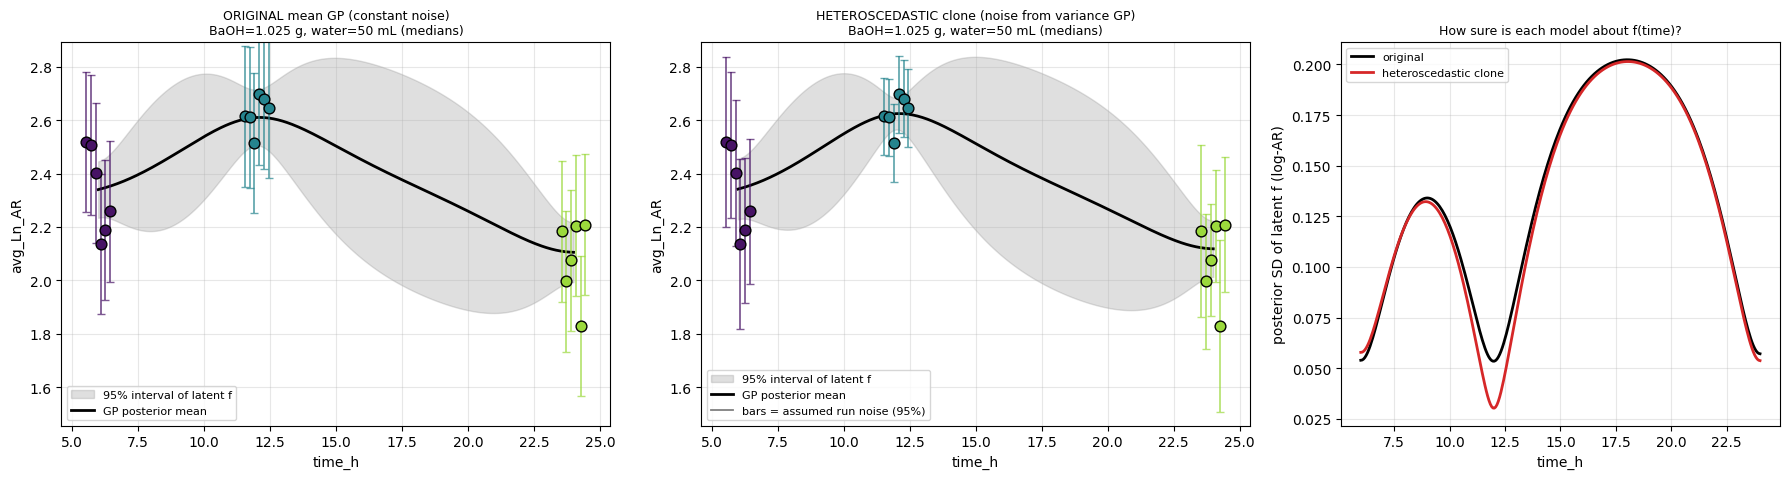

bo_est (original mean GP) is untouched: its hyperparameters are identical to the snapshot taken before the clone was fitted.


In [ ]:
# =====================================================================================================
# Heteroscedastic mean GP, part 2: side-by-side time slices (same style as before): original mean GP vs heteroscedastic clone.
# Black line = posterior mean of the latent function, gray band = 95% interval of the latent function,
# dots = measured runs (coloured by time), vertical bars = the NOISE each model ASSUMES for that run (95%).
# =====================================================================================================
tg = np.linspace(*BOUNDS["time_h"], 300)                                   # time grid
med = {v: df[v].median() for v in OPT_VARS}                                # other variables held at their data medians
raw = np.column_stack([tg if v == "time_h" else np.full(300, med[v]) for v in OPT_VARS])
A = np.column_stack([raw, np.full((300, 1), df["hto_mass_g"].median()), np.zeros(300)])   # FEATURES + dummy batch_code (unused by predict)
mu0, sd0 = bo_est.predict(A, return_std=True)                              # ORIGINAL model (constant noise)
mu1, sd1 = bo_est_hetero.predict(A, return_std=True)                       # CLONE (run-specific noise)

noise_sd_orig = np.full(len(df), np.sqrt(bo_est.H_["sn2"]) * bo_est.y_sd_) # constant noise SD of the original, log-AR units
noise_sd_het = np.sqrt(eff_noise)                                          # run-specific noise SD of the clone

time_levels = np.sort(df["time_h"].unique())
colors = dict(zip(time_levels, plt.cm.viridis(np.linspace(0.05, 0.85, len(time_levels)))))
rank = df.groupby("time_h").cumcount().to_numpy()                          # tiny horizontal offset so overlapping runs stay visible
jit = (rank - df.groupby("time_h")["time_h"].transform("size").to_numpy() / 2 + 0.5) * 0.18   # display only, not used in any model

lo = min((mu0 - 1.96 * sd0).min(), (mu1 - 1.96 * sd1).min(), (y_ser - 1.96 * noise_sd_het).min()) - 0.05
hi = max((mu0 + 1.96 * sd0).max(), (mu1 + 1.96 * sd1).max(), (y_ser + 1.96 * noise_sd_het).max()) + 0.05
fig, axes = plt.subplots(1, 3, figsize=(18, 4.9), gridspec_kw={"width_ratios": [1, 1, 0.8]})
for ax, mu, sd, nsd, title in [(axes[0], mu0, sd0, noise_sd_orig, "ORIGINAL mean GP (constant noise)"),
                               (axes[1], mu1, sd1, noise_sd_het, "HETEROSCEDASTIC clone (noise from variance GP)")]:
    ax.fill_between(tg, mu - 1.96 * sd, mu + 1.96 * sd, color="gray", alpha=0.25, label="95% interval of latent f")
    ax.plot(tg, mu, "k", lw=2, label="GP posterior mean")
    for t in time_levels:                                                  # runs coloured by their time, as in the earlier plots
        m = (df["time_h"] == t).to_numpy()
        ax.errorbar(df["time_h"][m] + jit[m], y_ser[m], yerr=1.96 * nsd[m], fmt="none", ecolor=colors[t], alpha=0.7, capsize=3, lw=1.3)
        ax.scatter(df["time_h"][m] + jit[m], y_ser[m], s=60, color=colors[t], edgecolor="k", zorder=5)
    ax.set_ylim(lo, hi); ax.set_xlabel("time_h"); ax.set_ylabel(TARGET); ax.grid(alpha=0.3)
    ax.set_title(f"{title}\nBaOH={med['baoh_mass_g']:.4g} g, water={med['water_initial_ml']:g} mL (medians)", fontsize=9)
axes[0].legend(fontsize=8, loc="lower left")
axes[1].plot([], [], color="gray", lw=1.3, label="bars = assumed run noise (95%)"); axes[1].legend(fontsize=8, loc="lower left")

axes[2].plot(tg, sd0, "k", lw=2, label="original"); axes[2].plot(tg, sd1, color="tab:red", lw=2, label="heteroscedastic clone")
axes[2].set_xlabel("time_h"); axes[2].set_ylabel("posterior SD of latent f (log-AR)"); axes[2].grid(alpha=0.3); axes[2].legend(fontsize=8)
axes[2].set_title("How sure is each model about f(time)?", fontsize=9)
plt.tight_layout(); plt.show()

# proof that the original model was not modified by anything above
assert all(np.allclose(np.atleast_1d(orig_snapshot[k]), np.atleast_1d(bo_est.H_[k])) for k in ["amp2", "ls", "sb2", "sn2"]), "bo_est changed!"
print("bo_est (original mean GP) is untouched: its hyperparameters are identical to the snapshot taken before the clone was fitted.")


## Step 11: Select the experimental batch to synthesize

Choose according to the objective **and resources**:
* best expected AR soon → a Prong-3 batch (q-NEI), or Prong 1/2 if close in `qNEI`;
* surrogate no better than the baseline (Step 4 leaderboard) → lean to exploration (max-entropy, CL-low);
* a **mixed** batch is legitimate (e.g. 3 from q-NEI + 1 from max-entropy).

**Oven runs matter.** Runs share an oven run only if they use the same time and temperature. A batch mixing times is really several oven runs, each with its own unknown offset. (i) If one oven run per round is affordable, restrict `ALLOWED_TIMES` in Step 1 and re-run from Step 5; (ii) put each recipe into **at least two different oven runs** across rounds (as Round 1 did), otherwise oven offset and recipe effect cannot be separated.

`REPLICATES` repeats each recipe in a **different** oven run. The `strategy` column is what Step 17 needs to compare strategies on measured data.


In [ ]:
CHOSEN     = "P3 q-NEI"     # one of the keys of BATCHES
REPLICATES = 1              # 1 = each recipe once; 2 = each recipe in two different oven runs (like Round 1)

T_CONST, RINSE_CONST = float(df["temperature_c"].iloc[0]), float(df["water_rinse_ml"].iloc[0])
HTO_CONST = round(HTO_FIXED, 4)
sel = BATCHES[CHOSEN]
out = pd.DataFrame(np.repeat(pool_raw[sel], REPLICATES, axis=0), columns=OPT_VARS)
out["replicate"] = np.tile(np.arange(REPLICATES), len(sel))

nums = df["batch_id"].str.extract(r"(\d+)")[0].astype(float)
next_b = int(nums.max()) + 1 if nums.notna().any() else 1
keys = out[["time_h", "replicate"]].drop_duplicates().sort_values(["replicate", "time_h"]).reset_index(drop=True)
keys["batch_id"] = [f"B{next_b + i}" for i in range(len(keys))]
out = out.merge(keys, on=["time_h", "replicate"], how="left").sort_values("batch_id", kind="stable").reset_index(drop=True)
out["notes"] = out["batch_id"] + "S" + (out.groupby("batch_id").cumcount() + 1).astype(str)

out.insert(0, "run_id", range(int(df.run_id.max()) + 1, int(df.run_id.max()) + 1 + len(out)))
out.insert(1, "round", int(df["round"].max()) + 1)
out.insert(2, "temperature_c", T_CONST); out.insert(4, "hto_mass_g", HTO_CONST); out["water_rinse_ml"] = RINSE_CONST
out["avg_Ln_AR"] = np.nan; out["purity_pct"] = np.nan
out["strategy"] = CHOSEN
out = out[["run_id", "round", "temperature_c", "time_h", "hto_mass_g", "baoh_mass_g", "water_initial_ml", "water_rinse_ml",
           "avg_Ln_AR", "purity_pct", "notes", "batch_id", "strategy"]]
out.to_csv("proposed_batch_next_round.csv", index=False)
proposals.to_csv("all_proposed_batches_comparison.csv", index=False)
display(out)
n_ovens = out["batch_id"].nunique()
print(f"These {len(out)} runs need {n_ovens} oven run(s) (runs share an oven run only if they use the same time).")
if n_ovens > REPLICATES:
    print("For ONE oven run per round, set ALLOWED_TIMES in Step 1 to a single time and re-run from Step 5.")
print("Saved: proposed_batch_next_round.csv and all_proposed_batches_comparison.csv")

,run_id,round,temperature_c,time_h,hto_mass_g,baoh_mass_g,water_initial_ml,water_rinse_ml,avg_Ln_AR,purity_pct,notes,batch_id,strategy
0,19,2,210.0,10.0,0.1402,1.03,54.0,10.0,NaN,NaN,B7S1,B7,P3 q-NEI
1,20,2,210.0,14.0,0.1402,0.77,55.0,10.0,NaN,NaN,B8S1,B8,P3 q-NEI
2,21,2,210.0,16.0,0.1402,0.87,30.0,10.0,NaN,NaN,B9S1,B9,P3 q-NEI


These 3 runs need 3 oven run(s) (runs share an oven run only if they use the same time).
For ONE oven run per round, set ALLOWED_TIMES in Step 1 to a single time and re-run from Step 5.
Saved: proposed_batch_next_round.csv and all_proposed_batches_comparison.csv


## Steps 12-13: Synthesis and characterization (lab)

Run the recipes in `proposed_batch_next_round.csv`; keep every other condition identical to Round 1 and write deviations/failed reactions in `notes` (a failed reaction is information: do not drop it silently). **SEM** gives needle dimensions and AR (same protocol for every sample, per-run values, not averaged replicates); **XRD** (± Rietveld) gives `purity_pct`. Fill `aspect_ratio` and `purity_pct` in the CSV.

## Step 14: Update the experimental dataset

Only **measured** values enter the dataset. The helper refuses missing results and columns that look like predictions or fantasies.


In [ ]:
df_raw = df.copy()  # normalized active dataset; preserves run/recipe/batch IDs
def append_new_results(df_old_raw, filled_csv, save_as):
    """Append the measured results of a finished round to the experimental dataset."""
    new = pd.read_csv(filled_csv)
    required = OPT_VARS + [TARGET, PURITY_COL]
    assert new[required].notna().all().all(), "Some runs have no measured aspect ratio / purity yet (or a missing parameter)."
    suspicious = [c for c in new.columns if any(t in c.lower() for t in ("fantasy", "pred", "mu_", "sd_"))]
    assert not suspicious, f"Columns that look like predictions/fantasies must not be saved as data: {suspicious}"
    merged = pd.concat([df_old_raw, new], ignore_index=True); merged.to_csv(save_as, index=False)
    print(f"Saved {save_as}: {len(df_old_raw)} old + {len(new)} new runs"); return merged
# After the lab work:  df_raw_updated = append_new_results(df_raw, "proposed_batch_next_round.csv", "Experiment_Results_Rd2.csv")

## Steps 15-16: Retrain and repeat

Set `CSV_PATH` to the updated file and re-run from Step 2. **Everything is rebuilt on the enlarged data**: recipes and oven runs, the shared CV scaffold (Step 3b), the nested-CV leaderboard and tuned GP structure (Step 4), the candidate pool, all batch strategies, and the replay. The CV-selected surrogate is therefore **re-chosen every round** rather than assumed. Keep `Q`, bounds, grids, `D_MIN` and the acquisition fixed between rounds. Consider splitting each round's batch between two strategies (labelled in `strategy`) so that all strategies face the same lab conditions.

## Step 17: Evaluate optimization performance across iterations

Measured outcomes only. Per round and strategy: runs, best purity-acceptable AR, mean AR, fraction meeting purity; cumulative best-so-far; experiments to reach a target; reproducibility.


In [ ]:
def evaluate_progress(d, target_ar=None):
    d = d.copy()
    if "strategy" not in d.columns: d["strategy"] = np.nan
    d["strategy"] = d["strategy"].fillna("initial")
    d["feasible"] = d[PURITY_COL] >= PURITY_MIN
    d["AR_feasible"] = d[TARGET].where(d["feasible"])
    per = (d.groupby(["round", "strategy"]).agg(n_runs=("run_id", "size"), mean_AR=(TARGET, "mean"),
           best_AR_feasible=("AR_feasible", "max"), frac_feasible=("feasible", "mean")))
    cum = d.sort_values("run_id")["AR_feasible"].cummax().reset_index(drop=True)
    print("Per round and strategy:"); display(per.round(3))
    print("Best purity-acceptable AR so far, by round:"); display(d.groupby("round")["AR_feasible"].max().cummax().round(3).to_frame("best_so_far"))
    if target_ar is not None:
        hit = np.where(cum.values >= target_ar)[0]
        print(f"Experiments needed to reach AR >= {target_ar}: {hit[0] + 1 if len(hit) else 'not reached yet'}")
    rep_std = d.groupby("recipe_id")[TARGET].std().dropna()
    print(f"Reproducibility: median replicate std = {rep_std.median():.2f} (recipes with replicates = {len(rep_std)})")
    return per
_ = evaluate_progress(df)

## Step 18: Validate the final optimized condition

Run several new independent replicates of the best recipe and compare with the baseline. With 2-4 replicates per group power is low: report the **difference with a bootstrap interval**, not only a p-value.


In [ ]:
def compare_to_baseline(d, recipe_id_new, recipe_id_baseline, n_boot=10000, seed=0):
    """Difference in mean AR (new - baseline) with a bootstrap 95% interval and Welch's t-test. Use on NEW validation runs."""
    from scipy.stats import ttest_ind
    a = d.loc[d.recipe_id == recipe_id_new, TARGET].values; b = d.loc[d.recipe_id == recipe_id_baseline, TARGET].values
    r = np.random.default_rng(seed)
    diffs = [r.choice(a, len(a)).mean() - r.choice(b, len(b)).mean() for _ in range(n_boot)]
    lo_ci, hi_ci = np.percentile(diffs, [2.5, 97.5]); t = ttest_ind(a, b, equal_var=False)
    print(f"mean(new)={a.mean():.2f} (n={len(a)})  mean(base)={b.mean():.2f} (n={len(b)})  diff={a.mean()-b.mean():.2f}  "
          f"95% bootstrap CI [{lo_ci:.2f}, {hi_ci:.2f}]  Welch p={t.pvalue:.3f}")
# Usage once validation runs exist:  compare_to_baseline(df, recipe_id_new=10, recipe_id_baseline=1)

## Step 19: Drawing conclusions

Questions the final analysis should answer, with the evidence available *in this notebook*:
1. **Which surrogate?** Step 4 leaderboard (outer-CV, shared folds) and the stability of the chosen structure across folds. If no GP is clearly better than the mean baseline, say so: proposals are exploration.
2. **Which acquisition function / batch strategy?** Replay (Step 10b) gives a *diagnostic* ranking under identical conditions; measured rounds (Step 17) give the evidence. Joint q-NEI vs ranking + distance is worth testing in the lab by splitting batches between strategies.
3. **Does modelling oven-run offsets help?** Compare `batch_effect=True` vs `False` among the best structures in the Step 4 candidate table, and the variance decomposition.

**Honest limits.** 9 recipes, replicate scatter comparable to the effect size, and oven offsets confounded with reaction time (each time level has only two oven runs) limit what any model or strategy comparison can show. The CV scaffold removes *avoidable* unfairness (leakage, different splits, different metrics); it cannot create information the data do not contain. A complementary check is an in-silico benchmark on a synthetic ground truth drawn from the fitted GP, with many repetitions.


## Appendix: markdown notes whose code cells are not in this notebook

The three notes below describe cells (manual variance/delta GP tuning, mean-GP hyperparameter overrides) that are **not present** in this version of the notebook. They are kept unchanged in meaning so that nothing is lost, but there is no code below them. If those cells are added again, they should be placed after Step 10f.

### Side-by-Side 1D Slice Analysis for Auxiliary GPs (Variance & Delta)

The following code generates comparative 1D slice plots. For each experimental variable, the predicted curves and confidence intervals can be compared under three distinct noise levels: the active setup (originally fit or set above), and two user-defined comparison values.


### Side-by-Side 1D Slice Analysis for the Mean GP under Custom Hyperparameter Overrides

The cell below allows experimenting with custom parameters for the Mean GP model (`bo_est`). The signal amplitude and lengthscales can be set manually, and predictions compared side-by-side under three custom noise settings ($s_n^2$) without altering the primary active GP model driving the optimization loop.


Manual variance and delta GP tuning
